# Data Mining Project — Information Operations (A.Y. 2026/2027)

This notebook contains the complete analysis of the project:

* **Task 1 – Data Understanding and Preparation**: data semantics, data quality (including an investigation of
  the timestamps), distributions, correlations and the construction of a **user (account) profile** with
  engineered features;
* **Task 2 – Clustering Analysis**: K-means, DBSCAN, hierarchical clustering, a final comparison and, as optional
  technique, **Gaussian Mixture Models fitted with the EM algorithm**.

**Course-material rule.** Every technique, algorithm, metric and visualisation used here appears in the course
slides (folder `material/`). At the beginning of every section a Markdown cell lists the techniques used and the
slide deck / page where they are introduced. The slide decks are cited with these short names:

| Short name | File in `material/` |
|---|---|
| **[DU]** Data Understanding | `2-data_understanding-2026.pdf` |
| **[DP]** Data Preparation & Cleaning | `3-data_preparation-2026.pdf` |
| **[SIM]** Data Similarity | `6-data_similarity.pdf` |
| **[CL-INTRO]** Cluster analysis – introduction | `6-basic_cluster_analysis-intro.pdf` |
| **[KM]** K-means | `6-basic_cluster_analysis-kmeans.pdf` |
| **[KM-VAR]** K-means variants (bisecting, X-means, mixture models / EM) | `6-basic_cluster_analysis-kmeans-variants.pdf` |
| **[HIER]** Hierarchical clustering | `7.basic_cluster_analysis-hierarchical.pdf` |
| **[DBSCAN]** DBSCAN | `8.basic_cluster_analysis-dbscan.pdf` |
| **[VAL]** Cluster validity | `8.basic_cluster_analysis-validity.pdf` |

The slides do not prescribe software libraries; the notebook uses the standard Python data-analysis stack
(`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`) only as implementations of the techniques of
the slides, plus `pyarrow` to store intermediate tables in Parquet format.

**Identifiers.** All identifiers (`postid`, `accountid`, `in_reply_to_postid`, `in_reply_to_accountid`,
`reposted_postid`, `reposted_accountid`) were anonymised with a hash computed **per country**: they are unique
only inside the same `ioCountry`. The notebook therefore always uses the **composite key (ioCountry, id)** –
for duplicates, labels, joins and user profiles.

**IO vs control.** Information-operation accounts (**IO**, `is_control == False`) are always compared with
**control** accounts (`is_control == True`). Long-tailed variables (followers, following, number of posts, ...)
are analysed on a logarithmic scale.

**How to run.** Put `data.csv.zip` in the project folder (or the extracted `data.csv` in `data/`) and run all the
cells. The raw CSV (~5 GB, 8.7 M posts) is read in chunks and converted into a compact Parquet table that is used
by the following cells.

## 0. Setup

In [1]:
# --- Standard library ---
import gc
import time
import warnings
import zipfile
from pathlib import Path

# --- Scientific stack ---
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

# One consistent colour per class in every comparison
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
CLASS_ORDER = ['IO', 'Control']
CLASS_PALETTE = {'IO': '#d62728', 'Control': '#1f77b4'}

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# --- Paths ---
PROJECT_DIR = Path('.').resolve()
DATA_DIR = PROJECT_DIR / 'data'
DATA_DIR.mkdir(exist_ok=True)
RAW_ZIP = PROJECT_DIR / 'data.csv.zip'
RAW_CSV = DATA_DIR / 'data.csv'
POSTS_PQ = DATA_DIR / 'posts_compact.parquet'      # compact post-level table built from the raw CSV
CLEAN_PQ = DATA_DIR / 'posts_clean.parquet'        # cleaned post-level table
PROFILES_PQ = DATA_DIR / 'user_profiles.parquet'   # account-level profiles (output of Task 1, input of Task 2)

print('pandas', pd.__version__, '| numpy', np.__version__)


def sturges_bins(n: int) -> int:
    """Number of histogram bins according to Sturges' rule, k = 1 + log2(n)  [DU p. 30]."""
    return int(np.ceil(1 + np.log2(n)))


def entropy_bits(counts) -> float:
    """Shannon entropy H = -sum p log2 p of a vector of counts  [SIM pp. 20-22]."""
    p = np.asarray(counts, dtype=float)
    p = p[p > 0] / p.sum()
    return float(-(p * np.log2(p)).sum() + 0.0)


def mutual_information_bits(x, y) -> float:
    """Mutual information I(X,Y) = H(X) + H(Y) - H(X,Y) in bits  [SIM pp. 23-24]."""
    ct = pd.crosstab(pd.Series(np.asarray(x)), pd.Series(np.asarray(y))).to_numpy()
    return entropy_bits(ct.sum(1)) + entropy_bits(ct.sum(0)) - entropy_bits(ct.ravel())

pandas 3.1.1 | numpy 2.5.5


In [2]:
# Extract the raw CSV from the ZIP archive if it is not already available.
if not RAW_CSV.exists():
    if not RAW_ZIP.exists():
        raise FileNotFoundError('Put data.csv.zip in the project folder (or data.csv in ./data).')
    with zipfile.ZipFile(RAW_ZIP) as zf:
        zf.extract('data.csv', DATA_DIR)  # the __MACOSX entry of the archive is skipped
print(f'Raw CSV: {RAW_CSV}  ({RAW_CSV.stat().st_size / 1e9:.2f} GB)')

Raw CSV: C:\Users\Diogo\Desktop\Data mining project\data\data.csv  (5.03 GB)


### 0.1 From the raw CSV to a compact Parquet table

The raw file is read in chunks of 500k rows **as plain strings** (no type inference), so that no information is
lost before the quality assessment. For each chunk:

* every identifier is replaced by a 64-bit hash of the **composite key `ioCountry|id`** (`*_key` columns, `0` =
  missing). Equal composite keys keep equal hashes in every chunk and in every column (e.g. `accountid` vs
  `reposted_accountid`), which is all we need for joins and duplicate detection, while identifiers of different
  countries can never be confused;
* the free-text fields (`post_text`, `account_profile_description`) are replaced by derived descriptors (length,
  number of words) and by a hash of the normalised text (used to find copied content);
* the list fields (`hashtags`, `urls`, `account_mentions`, stored as `"['a' 'b']"`) become counts;
* numbers and dates are parsed; for `follower_count` / `following_count` a **status code** records why a value is
  not valid (missing, non-numeric token, negative, non-integer) together with the offending token;
* a hash of the **whole raw row** is kept to detect exact duplicate records.

In [3]:
LIST_ITEM_RE = r"'[^']*'|\"[^\"]*\""   # one quoted element of a stringified list
COUNT_STATUS = {0: 'valid', 1: 'missing', 2: 'non-numeric token', 3: 'negative', 4: 'non-integer'}
ID_COLUMNS = {'postid': 'post_key', 'accountid': 'acc_key', 'in_reply_to_postid': 'reply_post_key',
              'in_reply_to_accountid': 'reply_acc_key', 'reposted_postid': 'rep_post_key',
              'reposted_accountid': 'rep_acc_key'}


def hash_col(s: pd.Series) -> np.ndarray:
    """Deterministic 64-bit hash of a string column (missing values -> 0)."""
    h = pd.util.hash_pandas_object(s.fillna(''), index=False).to_numpy().copy()
    h[s.isna().to_numpy()] = 0
    return h


def composite_key(country: pd.Series, ident: pd.Series) -> np.ndarray:
    """Hash of the composite key 'ioCountry|id' (ids are unique only within the same country)."""
    return hash_col(country + '|' + ident)          # NaN ids stay NaN -> key 0


def parse_count(raw: pd.Series):
    """Parse a count column; returns (numeric value, status code, offending token)."""
    num = pd.to_numeric(raw, errors='coerce')
    status = np.select([raw.isna(), num.isna(), num < 0, (num % 1) != 0], [1, 2, 3, 4], default=0).astype('int8')
    return num.astype('float64'), status, raw.where(status == 2)


SCHEMA = pa.schema(
    [('row_h', pa.uint64()), ('ioCountry', pa.string()), ('accountid', pa.string())]
    + [(k, pa.uint64()) for k in ID_COLUMNS.values()]
    + [('text_len', pa.float32()), ('n_words', pa.float32()), ('text_h', pa.uint64()),
       ('application_name', pa.string()), ('post_language', pa.string()),
       ('post_time', pa.timestamp('s')), ('desc_len', pa.float32()),
       ('follower_count', pa.float64()), ('follower_status', pa.int8()), ('follower_bad_token', pa.string()),
       ('following_count', pa.float64()), ('following_status', pa.int8()), ('following_bad_token', pa.string()),
       ('account_creation_date', pa.timestamp('s')), ('is_repost_raw', pa.string()),
       ('n_hashtags', pa.int16()), ('n_urls', pa.int16()), ('n_mentions', pa.int16()),
       ('is_control_raw', pa.string())])


def transform_chunk(ch: pd.DataFrame) -> pd.DataFrame:
    """Turn one raw chunk (all strings) into the compact representation described above."""
    out = pd.DataFrame(index=ch.index)
    out['row_h'] = pd.util.hash_pandas_object(ch, index=False).to_numpy()
    out['ioCountry'] = ch['ioCountry']
    out['accountid'] = ch['accountid']
    for raw_col, key_col in ID_COLUMNS.items():
        out[key_col] = composite_key(ch['ioCountry'], ch[raw_col])
    txt = ch['post_text']
    out['text_len'] = txt.str.len().astype('float32')
    out['n_words'] = txt.str.count(r'\S+').astype('float32')
    out['text_h'] = hash_col(txt.str.lower().str.replace(r'\s+', ' ', regex=True).str.strip())
    out['application_name'] = ch['application_name']
    out['post_language'] = ch['post_language']
    out['post_time'] = pd.to_datetime(ch['post_time'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
    out['desc_len'] = ch['account_profile_description'].str.len().astype('float32')
    for col, short in [('follower_count', 'follower'), ('following_count', 'following')]:
        out[col], out[f'{short}_status'], out[f'{short}_bad_token'] = parse_count(ch[col])
    out['account_creation_date'] = pd.to_datetime(ch['account_creation_date'], format='%Y-%m-%d', errors='coerce')
    out['is_repost_raw'] = ch['is_repost']
    out['n_hashtags'] = ch['hashtags'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['n_urls'] = ch['urls'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['n_mentions'] = ch['account_mentions'].str.count(LIST_ITEM_RE).fillna(0).astype('int16')
    out['is_control_raw'] = ch['is_control']
    return out


if not POSTS_PQ.exists():
    t0 = time.time()
    writer = pq.ParquetWriter(POSTS_PQ, SCHEMA, compression='zstd')
    reader = pd.read_csv(RAW_CSV, dtype=str, keep_default_na=False, na_values=[''], chunksize=500_000)
    for i, chunk in enumerate(reader):
        writer.write_table(pa.Table.from_pandas(transform_chunk(chunk), preserve_index=False).cast(SCHEMA))
        if i % 4 == 0:
            print(f'chunk {i:2d}: {(i + 1) * 500_000:>10,d} rows read  ({time.time() - t0:5.0f}s)')
    writer.close()
    del reader, chunk
    gc.collect()
print(f'Compact table: {POSTS_PQ.name}  ({POSTS_PQ.stat().st_size / 1e6:.0f} MB, '
      f'{pq.ParquetFile(POSTS_PQ).metadata.num_rows:,} rows)')

chunk  0:    500,000 rows read  (   13s)


chunk  4:  2,500,000 rows read  (   58s)


chunk  8:  4,500,000 rows read  (  103s)


chunk 12:  6,500,000 rows read  (  143s)


chunk 16:  8,500,000 rows read  (  191s)


Compact table: posts_compact.parquet  (381 MB, 8,714,356 rows)


In [4]:
def load_posts(columns, path=POSTS_PQ):
    """Load a subset of columns; repeated strings are loaded as pandas categoricals to save memory."""
    cat_cols = [c for c in ['ioCountry', 'application_name', 'post_language', 'accountid',
                            'is_repost_raw', 'is_control_raw'] if c in columns]
    return pq.read_table(path, columns=columns, read_dictionary=cat_cols).to_pandas()


# A few raw records (first rows of the CSV), only to show what the original data look like.
raw_sample = pd.read_csv(RAW_CSV, nrows=5, dtype=str)
display(raw_sample.T.apply(lambda s: s.str.slice(0, 60)))

,0,1,2,3,4
ioCountry,ecuador,ecuador,ecuador,ecuador,ecuador
postid,0bafe020a260495bee38b98fde83668d924454019b,608fba51f2460c7f1ca527dfc48de2bc858d4ad201,514b2c38b26e240cac85382be74ed7d61a02468ac1,e82a816068e88387d19430348f0420b040e0d11b4e,13ed6aaeec4fffaf840f1c42ff88f5ab2cb324be64
post_text,Vamos a cambiar la forma de hacer comunicación...,"Damos servicio de manejo de prensa, elaboració...",@db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...,"Mario, debemos denuciar que en los poderes pub...",Tambien debemos estar claro que la oposición e...
application_name,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224,2727201c363b6fc4afe259ba4094ae0c49cb4df224
post_language,NaN,NaN,NaN,NaN,NaN
in_reply_to_postid,NaN,NaN,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464,NaN,NaN
in_reply_to_accountid,NaN,NaN,db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302,NaN,NaN
post_time,2010-03-13 02:52:00,2010-03-13 03:08:00,2010-03-13 15:26:00,2010-03-13 15:32:00,2010-03-13 15:35:00
accountid,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,2c6c0ef5f445760177b016e33b36809bde3c7ac241,2c6c0ef5f445760177b016e33b36809bde3c7ac241,2c6c0ef5f445760177b016e33b36809bde3c7ac241
account_profile_description,"#Periodismo, #RelacionesPúblicas, #Comunicac...","#Periodismo, #RelacionesPúblicas, #Comunicac...",NaN,NaN,NaN


---
# Task 1 – Data Understanding and Preparation

## 1.1 Data semantics

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Data objects, attributes, data matrix | [DU] pp. 5–6 |
| Attribute types: nominal, binary (symmetric/asymmetric), ordinal, interval, ratio | [DU] pp. 13–14, 16–17 |
| Discrete vs continuous attributes | [DU] p. 15 |
| Ordered (temporal/sequential) data | [DU] pp. 10–12 |

Each record of the dataset is a **post**. Some attributes describe the post, others describe the **account** that
published it and are simply repeated on every post of the account (a snapshot taken at collection time).

| # | Variable | Level | Attribute type (slides [DU] pp. 13–17) | Meaning / role in the analysis |
|---|---|---|---|---|
| 1 | `ioCountry` | account | nominal | Information operation (country + release) the record belongs to; control accounts are matched to the same operation. Part of every composite key. |
| 2 | `postid` | post | nominal (identifier) | Anonymised post id; unique only within `ioCountry` → key `(ioCountry, postid)`. |
| 3 | `post_text` | post | text (document data) | Content of the post (URLs and mentions anonymised). Used through derived descriptors. |
| 4 | `application_name` | post | nominal (hashed) | Client used to publish. |
| 5 | `post_language` | post | nominal | Language label (ISO-639-1 code, `und` = undetermined). |
| 6 | `in_reply_to_postid` | post | nominal (identifier) | Replied post; missing when the post is not a reply. |
| 7 | `in_reply_to_accountid` | post | nominal (identifier) | Author of the replied post. |
| 8 | `post_time` | post | interval (date-time), ordered data | Timestamp of the post (investigated in 1.2.6). |
| 9 | `accountid` | post → account | nominal (identifier) | Author; with `ioCountry` it is the **key of the user profile**. |
| 10 | `account_profile_description` | account | text | Biography (optional). Used through its length / presence. |
| 11 | `follower_count` | account | ratio, discrete | Number of followers (snapshot). Long-tailed → log scale. |
| 12 | `following_count` | account | ratio, discrete | Number of followed accounts (snapshot). Long-tailed → log scale. |
| 13 | `account_creation_date` | account | interval (date) | Creation date of the account. |
| 14 | `is_repost` | post | asymmetric binary | Whether the post is a repost. |
| 15 | `reposted_accountid` | post | nominal (identifier) | Author of the original post (reposts only). |
| 16 | `reposted_postid` | post | nominal (identifier) | Original post (reposts only). |
| 17 | `hashtags` | post | set of nominal values (transaction-like) | Hashtags of the post. Used as counts. |
| 18 | `urls` | post | set of nominal values | URLs of the post (anonymised). Used as counts. |
| 19 | `account_mentions` | post | set of identifiers | Mentioned accounts. Used as counts. |
| 20 | `is_control` | account | binary (class label) | `True` = control, `False` = IO. **Never used as clustering input**, only to evaluate and compare. |

In [5]:
posts = load_posts(['ioCountry', 'acc_key', 'is_control_raw', 'application_name', 'post_language', 'post_time',
                    'account_creation_date'])
n_raw = len(posts)
print(f'Posts: {n_raw:,}   |   accounts (ioCountry, accountid): {posts["acc_key"].nunique():,}')
print(f'Distinct application_name values: {posts["application_name"].nunique():,}')
print(f'Distinct post_language values: {posts["post_language"].nunique():,} (+ missing)')
print(f'post_time range: {posts["post_time"].min()}  ->  {posts["post_time"].max()}')
print(f'account_creation_date range: {posts["account_creation_date"].min().date()}  ->  '
      f'{posts["account_creation_date"].max().date()}')
overview = (posts.groupby(['ioCountry', 'is_control_raw'], observed=True)
            .agg(posts=('acc_key', 'size'), accounts=('acc_key', 'nunique'))
            .unstack('is_control_raw').fillna(0).astype(int))
display(overview)
del posts
gc.collect()

Posts: 8,714,356   |   accounts (ioCountry, accountid): 86,525
Distinct application_name values: 3,728
Distinct post_language values: 70 (+ missing)
post_time range: 2008-04-30 10:35:00  ->  2019-07-30 23:59:56
account_creation_date range: 2006-07-26  ->  2019-07-12


posts                      accounts                   
is_control_raw    False     True is_control?    False   True is_control?
ioCountry                                                               
ecuador          700274   770338         207      787  21138         174
iran_1          1122977   199873         173      660   5015          81
iran_4           254797   306822          64     2519   7612          56
russia_1        1826432  1823841         455     3293  31299         407
uae             1325597   382293         213     3658  10545         195

0

The dataset covers five operations; Russia is the largest (≈42% of the posts). IO and control posts are not
balanced in the same way across operations (e.g. `iran_1` and `uae` are dominated by IO posts), and at account level
the data are **unbalanced** ([DU] p. 20): ≈11 thousand IO accounts against ≈75 thousand control accounts.
Comparisons are therefore made globally **and within each operation**. The label already shows an invalid value
(`is_control?`), handled in 1.2.

## 1.2 Data quality

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Data quality problems: syntactic accuracy, semantic accuracy, completeness, unbalanced data, timeliness | [DU] pp. 18–20 |
| Duplicate data and data cleaning | [DU] p. 21 |
| Missing values (structural / hidden by default values) | [DU] p. 64; [DP] pp. 25–26 |
| Substitution of missing / invalid values with the median of a segment | [DP] p. 26 |
| Descriptive statistics and visualisation to detect problems (histograms, bar charts) | [DU] pp. 22, 27–30 |
| Outliers: box plots, IQR rule, substitution | [DU] pp. 34, 61–63; [DP] p. 68 |
| Logarithmic transformation of long-tailed attributes | [DP] pp. 64–66 |

### 1.2.1 Missing values (completeness)

In [6]:
mq = load_posts(['is_control_raw', 'post_language', 'text_len', 'desc_len', 'follower_status', 'following_status',
                 'reply_post_key', 'reply_acc_key', 'rep_acc_key', 'rep_post_key', 'follower_count'])
missing = pd.DataFrame({
    'post_text': mq['text_len'].isna(),
    'post_language': mq['post_language'].isna(),
    'account_profile_description': mq['desc_len'].isna(),
    'follower_count': mq['follower_status'].eq(1),
    'following_count': mq['following_status'].eq(1),
    'in_reply_to_postid': mq['reply_post_key'].eq(0),
    'in_reply_to_accountid': mq['reply_acc_key'].eq(0),
    'reposted_accountid': mq['rep_acc_key'].eq(0),
    'reposted_postid': mq['rep_post_key'].eq(0),
})
miss = missing.groupby(mq['is_control_raw'].astype(str)).mean().T * 100
miss = miss.rename(columns={'False': 'IO %', 'True': 'Control %'}).drop(columns='is_control?', errors='ignore')
miss['overall %'] = missing.mean() * 100
miss['missing count'] = missing.sum()
print('Other fields (ioCountry, postid, accountid, post_time, account_creation_date, lists, is_repost) are never '
      'missing.')
display(miss.round(3))
print(f'Posts whose account reports 0 followers (possible "hidden" missing value, [DU] p. 64): '
      f'{(mq["follower_count"] == 0).mean() * 100:.2f}%')

Other fields (ioCountry, postid, accountid, post_time, account_creation_date, lists, is_repost) are never missing.


is_control_raw,IO %,Control %,overall %,missing count
post_text,0.0000,0.0000,0.0000,3
post_language,1.9830,0.0000,1.1900,103743
account_profile_description,17.8930,21.0690,19.1630,1669919
follower_count,0.0150,0.0160,0.0150,1318
following_count,0.0140,0.0140,0.0140,1192
in_reply_to_postid,88.5940,91.6860,89.8300,7828114
in_reply_to_accountid,88.7240,91.8120,89.9580,7839269
reposted_accountid,57.1190,60.8980,58.6290,5109181
reposted_postid,57.1190,60.8980,58.6290,5109181


Posts whose account reports 0 followers (possible "hidden" missing value, [DU] p. 64): 0.75%


* The reply and repost identifiers are missing **by design** (structural missingness): they exist only when the
  post is a reply or a repost, so their absence encodes the post type and is not a data error.
* `account_profile_description` is missing for ≈19% of the posts: an empty biography is itself a behavioural
  signal (feature `has_description`).
* `post_language` is missing for ≈1% of the posts – **only IO posts** (≈2% of them), a first hint of non-standard
  publishing tools. It becomes an explicit `unknown` category.
* `post_text` is missing for 3 posts; `follower_count` / `following_count` for ≈1.3k posts each (repaired at
  account level in 1.2.5). A count of 0 followers is plausible (new or fake accounts), so zeros are not treated as
  hidden missing values.

### 1.2.2 Syntactic accuracy (values outside the domain)

In [7]:
print('is_control raw values:')
display(mq['is_control_raw'].value_counts().to_frame('posts'))
del mq, missing
gc.collect()

cq = load_posts(['is_repost_raw', 'follower_status', 'follower_bad_token', 'following_status', 'following_bad_token'])
print('is_repost raw values:')
display(cq['is_repost_raw'].value_counts().to_frame('posts'))
status_tab = pd.DataFrame({
    'follower_count': cq['follower_status'].map(COUNT_STATUS).value_counts(),
    'following_count': cq['following_status'].map(COUNT_STATUS).value_counts()}).fillna(0).astype(int)
display(status_tab)
tokens = pd.concat([cq['follower_bad_token'].dropna(), cq['following_bad_token'].dropna()]).value_counts()
print('Non-numeric tokens found in follower_count / following_count:')
display(tokens.to_frame('occurrences').T)
del cq
gc.collect()

is_control raw values:


,posts
is_control_raw,
False,5230077
True,3483167
is_control?,1112


is_repost raw values:


,posts
is_repost_raw,
False,5109181
True,3605175


,follower_count,following_count
valid,8709796,8709975
non-numeric token,2265,2160
missing,1318,1192
negative,977,1029


Non-numeric tokens found in follower_count / following_count:


,unknown,NaN-ish,error,none,many,12abc,??42,4O00,ten,"1,2,3"
occurrences,517,516,508,499,480,414,384,377,370,360


0

* The class label contains **1,112 posts with the value `is_control?`** (≈0.01%).
* `follower_count` and `following_count` contain **text in numerical attributes** (`unknown`, `NaN-ish`, `error`,
  `none`, `many`, `12abc`, `??42`, `4O00` with a letter O, `ten`, `1,2,3`) and **negative values** – both outside
  the domain of a count. No non-integer value was found. `is_repost` contains only valid booleans.
* Since `is_control`, `follower_count` and `following_count` are **account attributes** repeated on every post,
  they can be repaired from the other posts of the same account (1.2.5).

### 1.2.3 Duplicate data (with the composite key)

In [8]:
keys = load_posts(['row_h', 'post_key', 'ioCountry', 'accountid', 'acc_key', 'text_h', 'post_time',
                   'account_creation_date', 'is_control_raw'])
exact_dup = keys['row_h'].duplicated()
print(f'Exact duplicated rows (identical in every field, ioCountry included): {exact_dup.sum():,}')
k1 = keys[~exact_dup]
key_dup = k1['post_key'].duplicated(keep=False)
grp = k1[key_dup].groupby('post_key').agg(n=('acc_key', 'size'), n_accounts=('acc_key', 'nunique'),
                                         n_texts=('text_h', 'nunique'), n_times=('post_time', 'nunique'))
print(f'Remaining records sharing the same (ioCountry, postid): {key_dup.sum():,} in {len(grp):,} groups')
display(grp.assign(same_account=grp['n_accounts'].eq(1), same_text=grp['n_texts'].eq(1),
                   same_time=grp['n_times'].eq(1))[['same_account', 'same_text', 'same_time']]
        .value_counts().to_frame('groups'))

# The same raw identifier can appear in different operations: with per-country hashing these are different keys.
raw_ids = k1.groupby('accountid', observed=True)['ioCountry'].nunique()
multi_ids = raw_ids[raw_ids > 1].index
mk = k1[k1['accountid'].isin(multi_ids)]
print(f'Raw accountid values occurring in more than one ioCountry: {len(multi_ids):,} '
      f'-> {mk["acc_key"].nunique():,} distinct composite accounts; their posts by label: '
      f'{mk["is_control_raw"].astype(str).value_counts().to_dict()}')
print('Distinct accounts – raw accountid:', f'{keys["accountid"].nunique():,}',
      '| composite (ioCountry, accountid):', f'{keys["acc_key"].nunique():,}')
del grp, raw_ids, mk

Exact duplicated rows (identical in every field, ioCountry included): 1,579


Remaining records sharing the same (ioCountry, postid): 601 in 296 groups


groups
same_account same_text same_time        
False        True      True          149
             False     True           76
True         False     True           70
False        False     False           1

Raw accountid values occurring in more than one ioCountry: 1,295 -> 2,664 distinct composite accounts; their posts by label: {'True': 230712, 'is_control?': 23}
Distinct accounts – raw accountid: 85,156 | composite (ioCountry, accountid): 86,525


* **1,579 rows are exact copies** of other rows → removed.
* 296 composite post keys `(ioCountry, postid)` (601 records) occur more than once with different content
  (different account, text or time): identifier collisions or corrupted records. A post must be counted once, so
  only the **first record of every composite key** is kept.
* Because identifiers are unique only within a country, a raw `postid`/`accountid` occurring in two operations is
  **not** a duplicate: it is a different key. About 1,300 raw account identifiers (all control accounts) occur in
  2–4 operations, which gives **86,525 composite accounts** instead of 85,156 raw identifiers. We keep them as
  separate accounts of different operations, as required by the per-country hashing (their posts share text and
  time, so they probably are the same users sampled for several operations: a minor overlap of the control
  samples that does not affect within-operation comparisons).

### 1.2.4 Semantic accuracy (business rules)

In [9]:
inc = load_posts(['acc_key', 'is_control_raw', 'post_time', 'account_creation_date', 'reply_post_key',
                  'reply_acc_key', 'is_repost_raw', 'rep_acc_key', 'rep_post_key', 'follower_count',
                  'follower_status'])
inc = inc[~exact_dup.to_numpy()]
valid_lab = inc[inc['is_control_raw'].isin(['True', 'False'])]
labels_per_acc = valid_lab.groupby('acc_key')['is_control_raw'].nunique()
bad_lab_accs = inc.loc[~inc['is_control_raw'].isin(['True', 'False']), 'acc_key'].unique()
is_rep = inc['is_repost_raw'].eq('True')
checks = {
    'accounts with both True and False labels': int((labels_per_acc > 1).sum()),
    'accounts with an invalid label on some post': len(bad_lab_accs),
    '  ... of which have a valid label on other posts': int(np.isin(bad_lab_accs, labels_per_acc.index).sum()),
    'accounts with >1 creation date': int((inc.groupby('acc_key')['account_creation_date'].nunique() > 1).sum()),
    'accounts with >1 valid follower_count value': int(
        (inc[inc['follower_status'] == 0].groupby('acc_key')['follower_count'].nunique() > 1).sum()),
    'posts published before the account creation date': int((inc['post_time'] < inc['account_creation_date']).sum()),
    'replies with in_reply_to_postid but no in_reply_to_accountid':
        int(((inc['reply_post_key'] != 0) & (inc['reply_acc_key'] == 0)).sum()),
    'replies with in_reply_to_accountid but no in_reply_to_postid':
        int(((inc['reply_post_key'] == 0) & (inc['reply_acc_key'] != 0)).sum()),
    'reposts without reposted ids': int((is_rep & (inc['rep_acc_key'] == 0)).sum()),
    'non-reposts with reposted ids': int((~is_rep & (inc['rep_acc_key'] != 0)).sum()),
    'posts that are both reply and repost': int((is_rep & (inc['reply_post_key'] != 0)).sum()),
    'self-replies (reply to own account)': int(((inc['reply_acc_key'] == inc['acc_key']) & (inc['reply_acc_key'] != 0)).sum()),
    'self-reposts (repost of own post)': int(((inc['rep_acc_key'] == inc['acc_key']) & (inc['rep_acc_key'] != 0)).sum()),
}
display(pd.Series(checks, name='count').to_frame())
del inc, valid_lab, is_rep
gc.collect()

,count
accounts with both True and False labels,1
accounts with an invalid label on some post,913
... of which have a valid label on other posts,913
accounts with >1 creation date,0
accounts with >1 valid follower_count value,984
posts published before the account creation date,0
replies with in_reply_to_postid but no in_reply_to_accountid,74608
replies with in_reply_to_accountid but no in_reply_to_postid,63456
reposts without reposted ids,0
non-reposts with reposted ids,0


0

* The class label is consistent at account level: every account with an `is_control?` post has a valid label on its
  other posts, and only one account has contradicting valid labels (resolved by majority).
* `account_creation_date` is constant per account and no post precedes the creation of its account.
* `follower_count` is a per-account snapshot: apart from the injected errors it is (almost) constant per account.
* Reply identifiers are sometimes only partially available (≈0.8% of the posts each way): a post is a **reply** if
  *either* identifier is present. Repost fields are perfectly consistent with `is_repost`.
* Self-replies (threads) and self-reposts are legitimate behaviours (self-reposting is an amplification tactic):
  they are kept.

### 1.2.5 Cleaning

Rules (all keyed by the composite keys):

1. drop exact duplicate rows and keep the first record of every `(ioCountry, postid)`;
2. `is_control`: majority of the valid labels of the account `(ioCountry, accountid)` (repairs every `is_control?`);
3. `follower_count`, `following_count`: invalid values (missing, non-numeric, negative) are set to missing and every
   post receives the **median of the valid values of its account** – substitution with the median of a segment,
   [DP] p. 26; accounts without any valid value receive the median of the accounts of their operation;
4. `post_language`: missing → explicit category `unknown`;
5. new boolean post-type flags: `is_reply` (any reply identifier present) and `is_repost`.

In [10]:
keep = (~exact_dup & ~keys['post_key'].duplicated()).to_numpy()   # rule 1
del keys, k1, exact_dup, key_dup
gc.collect()

if not CLEAN_PQ.exists():
    cols = ['ioCountry', 'accountid', 'acc_key', 'post_key', 'is_control_raw', 'post_time', 'account_creation_date',
            'application_name', 'post_language', 'is_repost_raw', 'reply_post_key', 'reply_acc_key', 'rep_acc_key',
            'rep_post_key', 'text_len', 'n_words', 'text_h', 'n_hashtags', 'n_urls', 'n_mentions', 'desc_len',
            'follower_count', 'follower_status', 'following_count', 'following_status']
    clean = load_posts(cols)
    # account attributes are computed on all the records of the account
    lab_valid = clean['is_control_raw'].astype(str).map({'True': 1.0, 'False': 0.0})
    acc_label = lab_valid.groupby(clean['acc_key']).mean().round().astype(bool)                 # rule 2
    acc_attr = {col: clean[col].where(clean[st] == 0).groupby(clean['acc_key']).median()          # rule 3
                for col, st in [('follower_count', 'follower_status'), ('following_count', 'following_status')]}
    clean = clean[keep].reset_index(drop=True)
    clean['is_control'] = clean['acc_key'].map(acc_label).astype(bool)
    for col in ['follower_count', 'following_count']:
        clean[col] = clean['acc_key'].map(acc_attr[col])
        op_median = clean.drop_duplicates('acc_key').groupby('ioCountry', observed=True)[col].median()
        clean[col] = clean[col].fillna(clean['ioCountry'].map(op_median).astype(float))
    clean['post_language'] = clean['post_language'].cat.add_categories('unknown').fillna('unknown')   # rule 4
    clean['is_repost'] = clean['is_repost_raw'].astype(str).eq('True')                                # rule 5
    clean['is_reply'] = (clean['reply_post_key'] != 0) | (clean['reply_acc_key'] != 0)
    clean = clean.drop(columns=['is_control_raw', 'is_repost_raw', 'follower_status', 'following_status'])
    clean.to_parquet(CLEAN_PQ, index=False, compression='zstd')
    del clean, acc_label, acc_attr, lab_valid
    gc.collect()
del keep

posts = pd.read_parquet(CLEAN_PQ)
posts['class'] = pd.Categorical(np.where(posts['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)
n_acc = posts['acc_key'].nunique()
print(f'Cleaned posts: {len(posts):,} (removed {n_raw - len(posts):,} duplicated records) | accounts: {n_acc:,}')
print('Accounts per class:', posts.drop_duplicates('acc_key')['class'].value_counts().to_dict())
print('Remaining problems -> invalid label:', int(posts['is_control'].isna().sum()),
      '| follower/following missing:', int(posts[['follower_count', 'following_count']].isna().sum().sum()),
      '| negative counts:', int((posts[['follower_count', 'following_count']] < 0).sum().sum()))

Cleaned posts: 8,712,472 (removed 1,884 duplicated records) | accounts: 86,525
Accounts per class: {'Control': 75608, 'IO': 10917}
Remaining problems -> invalid label: 0 | follower/following missing: 0 | negative counts: 0


### 1.2.6 Timeliness: is `post_time` the publication time or the collection time?

A first look at the data shows an unusual temporal structure in the control posts (a large share published at
23h UTC, most control accounts active on a single day). If `post_time` were the moment at which the data were
collected (e.g. by web scraping) instead of the real publication time, every time-based feature would be
meaningless. We check this with simple descriptive statistics ([DU] pp. 22, 31–34; [DU] p. 20 – *timeliness*):

1. the **resolution** of the timestamps (share of timestamps with seconds = 00);
2. the **hour-of-day** distribution;
3. the **time window** covered by each account (first/last post, same calendar day or not);
4. the relation between the number of posts of an account and the length of its window;
5. the **logical order** of reposts and replies: a repost / reply cannot be published before the original post.
   If the timestamps were collection times (or artificial), this rule would be violated.

% of posts whose timestamp has seconds = 00 (uniform seconds would give 1.7%):


class,IO,Control
ioCountry,,
ecuador,100.0000,1.9000
iran_1,100.0000,1.6000
iran_4,100.0000,1.6000
russia_1,100.0000,1.5000
uae,100.0000,1.7000


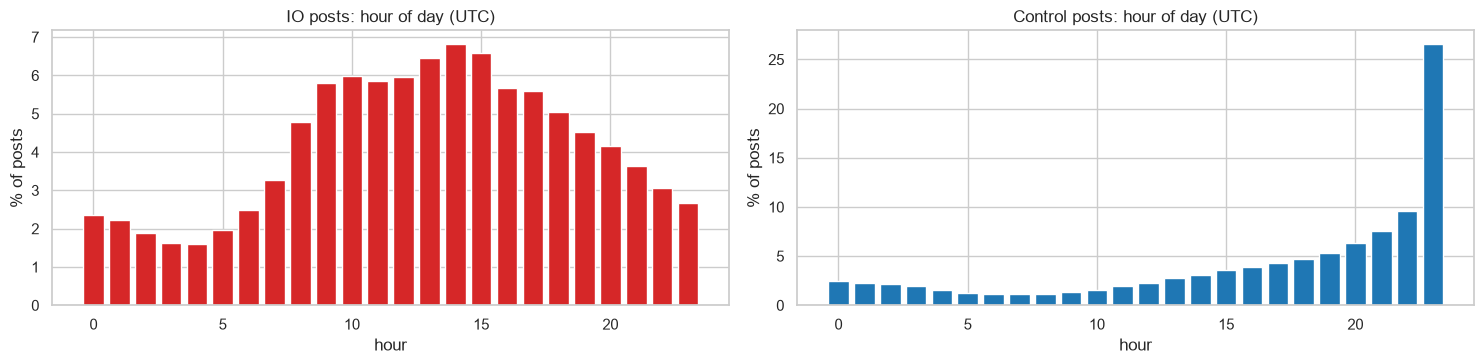

,% accounts with all posts on one calendar day,median gap between consecutive posts (s),% posts at 23h UTC
class,,,
IO,5.9000,720.0000,2.7000
Control,94.9000,72.0000,26.6000


Control accounts with >= 5 posts, all on one day: 55,329
  last post between 23:00 and 23:59: 99.3%  (after 23:50: 97.1%)


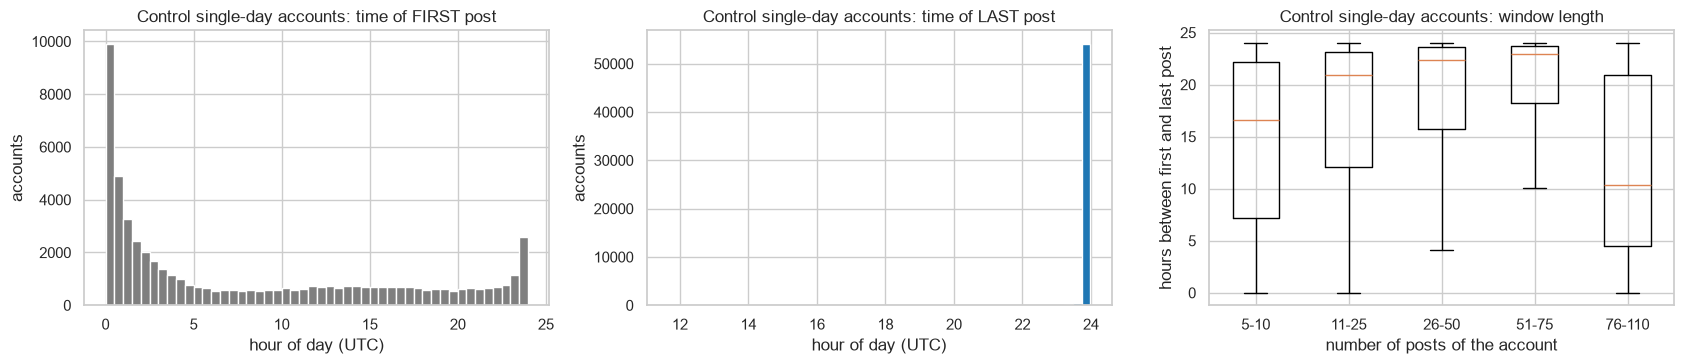

,type,class of the answering post,pairs found in the data,% published BEFORE the original,median delay (minutes)
0,repost,IO,141608,0.0060,56.0000
1,repost,Control,16259,0.0000,4.3170
2,reply,IO,15375,0.0000,13.0000
3,reply,Control,11915,0.0000,1.5330


% of control posts published on a day on which the same operation has IO posts: 100.0%


7281

In [11]:
pt = posts[['ioCountry', 'class', 'acc_key', 'post_key', 'post_time', 'rep_post_key', 'reply_post_key']].copy()
pt['hour'] = pt['post_time'].dt.hour

# 1. resolution: share of timestamps with seconds == 0
res = (pt.assign(sec0=pt['post_time'].dt.second.eq(0))
       .groupby(['ioCountry', 'class'], observed=True)['sec0'].mean().unstack() * 100)
print('% of posts whose timestamp has seconds = 00 (uniform seconds would give 1.7%):')
display(res.round(1))

# 2. hour-of-day distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
for ax, cls in zip(axes, CLASS_ORDER):
    share = pt.loc[pt['class'] == cls, 'hour'].value_counts(normalize=True).sort_index() * 100
    ax.bar(share.index, share.values, color=CLASS_PALETTE[cls])
    ax.set_title(f'{cls} posts: hour of day (UTC)')
    ax.set_xlabel('hour')
    ax.set_ylabel('% of posts')
plt.tight_layout()
plt.show()

# 3. time window of every account
srt = pt.sort_values(['acc_key', 'post_time'])
g = srt.groupby('acc_key')
win = pd.DataFrame({'class': g['class'].first(), 'n': g.size(), 'first': g['post_time'].min(),
                    'last': g['post_time'].max()})
win['same_day'] = win['first'].dt.normalize() == win['last'].dt.normalize()
win['span_h'] = (win['last'] - win['first']).dt.total_seconds() / 3600
gap_s = g['post_time'].diff().dt.total_seconds()
window_tab = pd.DataFrame({
    '% accounts with all posts on one calendar day': win.groupby('class', observed=True)['same_day'].mean() * 100,
    'median gap between consecutive posts (s)': gap_s.groupby(srt['class']).median(),
    '% posts at 23h UTC': pt.groupby('class', observed=True)['hour'].apply(lambda h: (h == 23).mean() * 100),
})
display(window_tab.round(1))

one_day = win[(win['class'] == 'Control') & win['same_day'] & (win['n'] >= 5)]
last_tod = one_day['last'].dt.hour + one_day['last'].dt.minute / 60
first_tod = one_day['first'].dt.hour + one_day['first'].dt.minute / 60
print(f'Control accounts with >= 5 posts, all on one day: {len(one_day):,}')
print(f'  last post between 23:00 and 23:59: {(one_day["last"].dt.hour == 23).mean() * 100:.1f}%  '
      f'(after 23:50: {((one_day["last"].dt.hour == 23) & (one_day["last"].dt.minute >= 50)).mean() * 100:.1f}%)')

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
axes[0].hist(first_tod, bins=48, color='#7f7f7f')
axes[0].set_title('Control single-day accounts: time of FIRST post')
axes[1].hist(last_tod, bins=48, color='#1f77b4')
axes[1].set_title('Control single-day accounts: time of LAST post')
for ax in axes[:2]:
    ax.set_xlabel('hour of day (UTC)')
    ax.set_ylabel('accounts')
# 4. window length vs number of posts (conditional box plot, [DU] p. 37)
one_day = one_day.assign(posts_bucket=pd.cut(one_day['n'], [4, 10, 25, 50, 75, 110],
                                             labels=['5-10', '11-25', '26-50', '51-75', '76-110']))
data_bp = [one_day.loc[one_day['posts_bucket'] == b, 'span_h'] for b in one_day['posts_bucket'].cat.categories]
axes[2].boxplot(data_bp, tick_labels=list(one_day['posts_bucket'].cat.categories), showfliers=False)
axes[2].set_xlabel('number of posts of the account')
axes[2].set_ylabel('hours between first and last post')
axes[2].set_title('Control single-day accounts: window length')
plt.tight_layout()
plt.show()

# 5. order of reposts / replies with respect to the original post (same ioCountry, composite keys)
orig_time = pt.drop_duplicates('post_key').set_index('post_key')['post_time']
rows = []
for kind, col in [('repost', 'rep_post_key'), ('reply', 'reply_post_key')]:
    d = pt[(pt[col] != 0) & pt[col].isin(orig_time.index)]
    delta_h = (d['post_time'] - d[col].map(orig_time)).dt.total_seconds() / 3600
    for cls in CLASS_ORDER:
        m = d['class'] == cls
        rows.append({'type': kind, 'class of the answering post': cls, 'pairs found in the data': int(m.sum()),
                     '% published BEFORE the original': 100 * (delta_h[m] < 0).mean(),
                     'median delay (minutes)': 60 * delta_h[m].median()})
display(pd.DataFrame(rows).round(3))

io = pt[pt['class'] == 'IO']
io_days = pd.MultiIndex.from_arrays([io['ioCountry'].astype(str), io['post_time'].dt.normalize()]).unique()
ctrl = pt[pt['class'] == 'Control']
in_io_day = pd.MultiIndex.from_arrays([ctrl['ioCountry'].astype(str), ctrl['post_time'].dt.normalize()]).isin(io_days)
print(f'% of control posts published on a day on which the same operation has IO posts: {in_io_day.mean() * 100:.1f}%')
del io
del pt, srt, g, gap_s, orig_time, ctrl, in_io_day, io_days
gc.collect()

**Evidence.**

* **Two different sources / formats.** Every IO timestamp has seconds = 00 (minute resolution, the format of the
  released IO archives), while control timestamps have second resolution (≈1.7% with seconds = 00, as expected for
  uniformly distributed seconds).
* **Real publication times.** Reposts and replies are **never** earlier than the post they answer, for both
  classes (the only exceptions are a few IO reposts by less than one minute, explained by the truncation of IO
  timestamps to the minute). Delays are realistic (minutes to hours). Collection times or artificial timestamps would
  violate this rule. Hence `post_time` **is the real publication time**, not the collection time.
* **A day-bounded, capped sample for the control accounts.** ≈95% of the control accounts have all their posts on
  a single calendar day. For these accounts the **last post is almost always between 23:50 and 23:59 UTC**, the
  first post is often right after midnight, and the window becomes shorter as the number of posts approaches ≈100
  (very active accounts fill the quota in a few hours before midnight). This is exactly the pattern of a collection
  that, for each control account, retrieved **at most ≈100 posts of one day, going backwards from 23:59:59** – which
  also explains the accumulation of control posts at 23h. Every control post falls on a day with IO activity of the
  same operation (matched time windows, as stated in the assignment).

**Decision.** Timestamps are reliable for describing *when* the posts in the dataset were published, so the
temporal features are computed and analysed in the profiles (1.5). However, the observation window is completely
different for the two classes (IO: whole account history; control: ≤ 1 day, ≤ ≈100 posts). Features describing
volume and time (number of posts, active days, lifespan, concentration over days/weeks, hour-of-day profile,
inter-post times) would separate IO from control because of the **sampling design** and not because of behaviour.
They are therefore **excluded from the clustering input** (Section 2.1).

### 1.2.7 Outliers

Outliers are detected with the IQR rule: a value is an outlier if it is outside
$[L, U] = [Q_1 - 1.5\,IQR,\ Q_3 + 1.5\,IQR]$ ([DP] p. 68; box plots [DU] p. 34). Long-tailed counts are first
log-transformed, $\log_{10}(1+x)$ ([DP] pp. 64–66).

,max,outliers,outliers %,% of IO units,% of Control units
variable,,,,,
text_len (post),"2,582.0000",377875,4.3400,3.1900,6.0600
n_hashtags (post),40.0000,405883,4.6600,2.4500,7.9800
n_mentions (post),51.0000,114687,1.3200,0.8600,2.0000
n_urls (post),9.0000,564,0.0100,0.0000,0.0100
n_posts (account),"265,448.0000",214,0.2500,1.7500,0.0300
follower_count (account),"19,912,528.0000",3146,3.6400,8.6400,2.9100
following_count (account),"2,301,841.0000",6703,7.7500,6.5900,7.9100


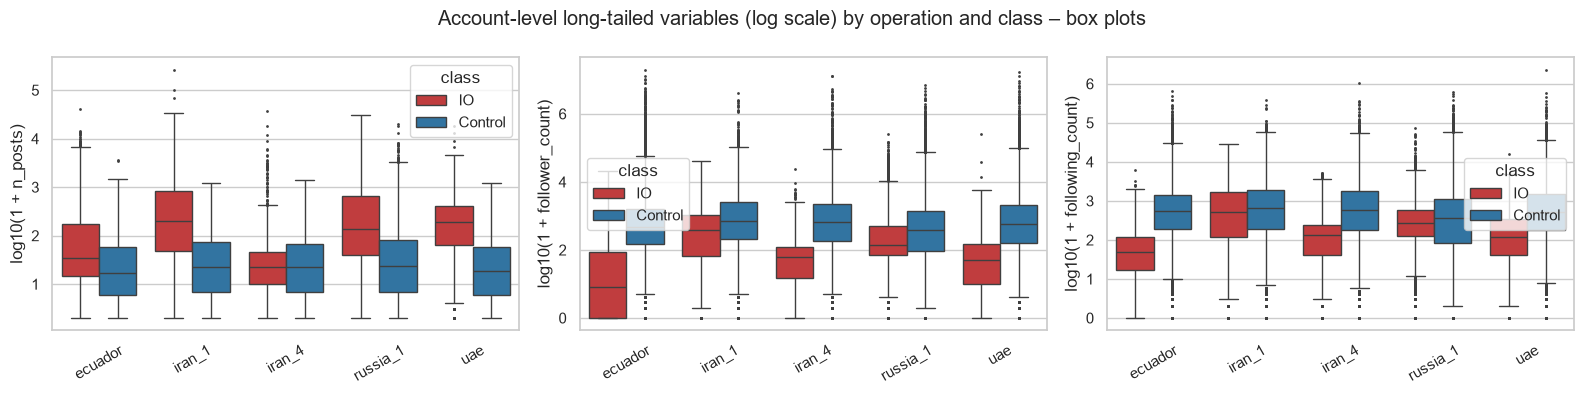

Most active accounts:


,ioCountry,class,n_posts,follower_count,following_count
acc_key,,,,,
16199581744105587512,iran_1,IO,265448,"8,012.0000","1,450.0000"
17870760626845196490,iran_1,IO,101956,"1,137.0000",219.0000
9322395900981560685,iran_1,IO,68808,"14,365.0000","15,104.0000"
17732089239407917882,ecuador,IO,40576,"3,618.0000","2,055.0000"
9060609697850221100,iran_4,IO,36990,"6,044.0000",651.0000


In [12]:
acc = (posts.groupby('acc_key')
       .agg(ioCountry=('ioCountry', 'first'), n_posts=('post_time', 'size'), follower_count=('follower_count', 'first'),
            following_count=('following_count', 'first'), is_control=('is_control', 'first'),
            account_creation_date=('account_creation_date', 'first')))
acc['class'] = pd.Categorical(np.where(acc['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)


def iqr_outliers(x: pd.Series, log=True) -> pd.Series:
    """Boolean mask of IQR outliers, computed on log10(1+x) when log=True."""
    v = np.log10(1 + x) if log else x
    q1, q3 = v.quantile([0.25, 0.75])
    return (v < q1 - 1.5 * (q3 - q1)) | (v > q3 + 1.5 * (q3 - q1))


rows = []
for name, s, cls in [('text_len (post)', posts['text_len'].dropna(), posts.loc[posts['text_len'].notna(), 'class']),
                     ('n_hashtags (post)', posts['n_hashtags'], posts['class']),
                     ('n_mentions (post)', posts['n_mentions'], posts['class']),
                     ('n_urls (post)', posts['n_urls'], posts['class']),
                     ('n_posts (account)', acc['n_posts'], acc['class']),
                     ('follower_count (account)', acc['follower_count'], acc['class']),
                     ('following_count (account)', acc['following_count'], acc['class'])]:
    out = iqr_outliers(s)
    rows.append({'variable': name, 'max': s.max(), 'outliers': int(out.sum()), 'outliers %': 100 * out.mean(),
                 '% of IO units': 100 * out[cls == 'IO'].mean(), '% of Control units': 100 * out[cls == 'Control'].mean()})
display(pd.DataFrame(rows).set_index('variable').round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['n_posts', 'follower_count', 'following_count']):
    sns.boxplot(data=acc, x='ioCountry', y=np.log10(1 + acc[col]), hue='class', palette=CLASS_PALETTE,
                hue_order=CLASS_ORDER, ax=ax, fliersize=1)
    ax.set_ylabel(f'log10(1 + {col})')
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
fig.suptitle('Account-level long-tailed variables (log scale) by operation and class – box plots')
plt.tight_layout()
plt.show()
print('Most active accounts:')
display(acc.nlargest(5, 'n_posts')[['ioCountry', 'class', 'n_posts', 'follower_count', 'following_count']])

* Even on the log scale the activity distribution has a long right tail: a few **IO accounts publish tens of
  thousands of posts** (the most active `iran_1` account has >265k posts), while the typical account has a few dozen.
  Followers and following counts span 6–7 orders of magnitude.
* These values are **not errors**: hyper-active accounts are exactly what an information operation is expected to
  produce ("outliers are the goal of our analysis", [DU] p. 61). They are **kept**. Their influence is controlled
  with the log transformation and, for clustering, by replacing the values outside $[L, U]$ with $L$ or $U$
  ([DP] p. 68, Section 2.1).
* Post-level outliers (very long texts, posts with tens of hashtags/mentions) are rare and plausible (anonymisation
  replaces every URL / mention with a long hash, inflating text length): they are kept.

## 1.3 Distributions and descriptive statistics

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Bar chart for categorical attributes | [DU] p. 27 |
| Histograms, number of bins with Sturges' rule $k = 1 + \log_2 n$ | [DU] pp. 28–30 |
| Visualisation of temporal data (time series plot) | [DU] pp. 23–24 |
| Shape of distributions (skewness) | [DU] pp. 25–26 |
| Central tendency (mean, median, mode) and dispersion (std, quartiles, IQR, MAD) | [DU] pp. 31–33 |
| Box plot and conditional box plot | [DU] pp. 34, 37–38 |
| Entropy of a nominal attribute | [DU] p. 17; [SIM] pp. 20–22 |
| Logarithmic transformation for long tails | [DP] pp. 64–66 |

### 1.3.1 Volume and time

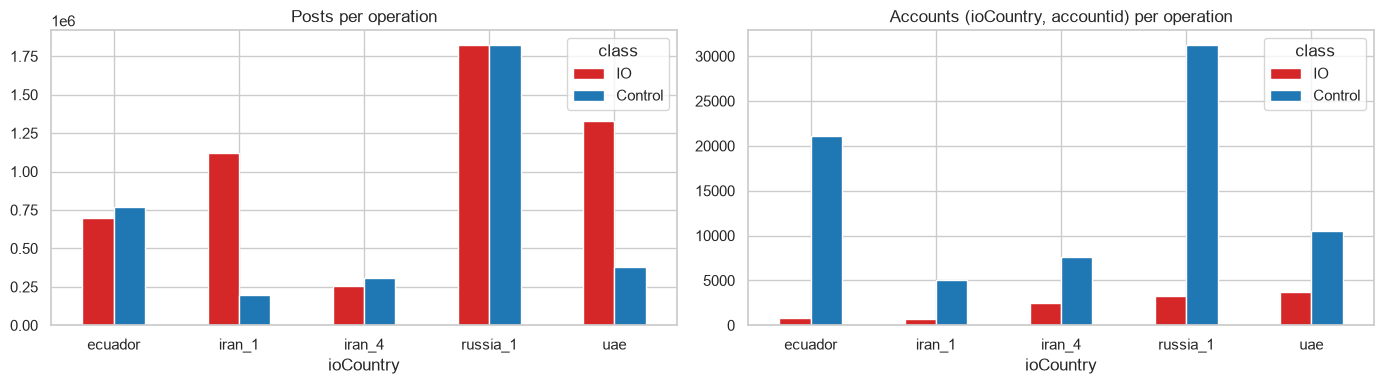

,count,mean,std,min,25%,50%,75%,90%,99%,max
class,,,,,,,,,,
IO,"10,917.0000",479.1000,"3,104.6000",1.0000,21.0000,88.0000,349.0000,"1,044.4000","5,434.4000","265,448.0000"
Control,"75,608.0000",46.1000,171.3000,1.0000,5.0000,20.0000,67.0000,99.0000,297.0000,"19,690.0000"


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vol = posts.groupby(['ioCountry', 'class'], observed=True).size().unstack('class')[CLASS_ORDER]
vol.plot(kind='bar', ax=axes[0], color=[CLASS_PALETTE[c] for c in CLASS_ORDER], rot=0)
axes[0].set_title('Posts per operation')
accs = acc.groupby(['ioCountry', 'class'], observed=True).size().unstack('class')[CLASS_ORDER]
accs.plot(kind='bar', ax=axes[1], color=[CLASS_PALETTE[c] for c in CLASS_ORDER], rot=0)
axes[1].set_title('Accounts (ioCountry, accountid) per operation')
plt.tight_layout()
plt.show()
display(acc.groupby('class', observed=True)['n_posts'].describe(percentiles=[.25, .5, .75, .9, .99]).round(1))

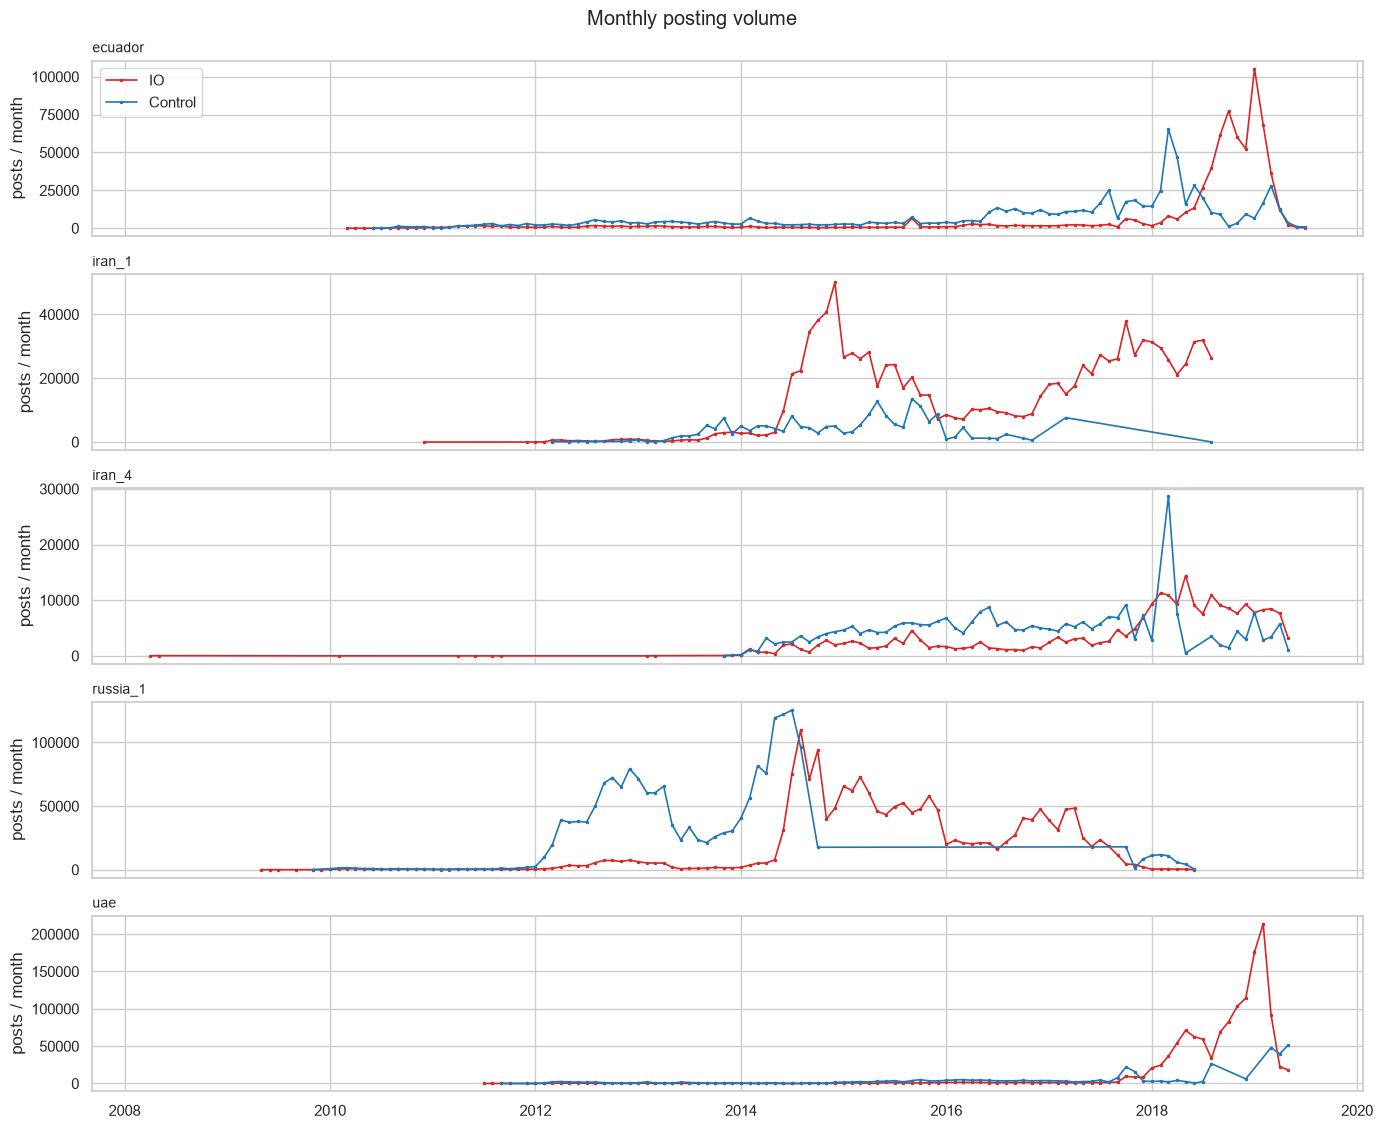

In [14]:
# Monthly number of posts of every operation (time series plot, [DU] pp. 23-24)
monthly = (posts.groupby(['ioCountry', 'class', posts['post_time'].dt.to_period('M')], observed=True)
           .size().rename('posts').reset_index())
monthly['post_time'] = monthly['post_time'].dt.to_timestamp()
ops = list(posts['ioCountry'].cat.categories)
fig, axes = plt.subplots(len(ops), 1, figsize=(14, 2.3 * len(ops)), sharex=True)
for ax, op in zip(axes, ops):
    for cls in CLASS_ORDER:
        m = monthly[(monthly['ioCountry'] == op) & (monthly['class'] == cls)]
        ax.plot(m['post_time'], m['posts'], color=CLASS_PALETTE[cls], label=cls, lw=1.2, marker='.', ms=3)
    ax.set_title(op, loc='left', fontsize=10)
    ax.set_ylabel('posts / month')
axes[0].legend(loc='upper left')
fig.suptitle('Monthly posting volume')
plt.tight_layout()
plt.show()
del monthly

IO activity is concentrated in specific periods (campaign peaks): Russia in 2014–2017, Iran_1 in 2014–2015 and
2017–2018, UAE and Ecuador with very sharp peaks in 2018–2019. Control posts cover days of the same windows
(1.2.6), but each control account contributes a single day.

### 1.3.2 Post type, language and publishing client

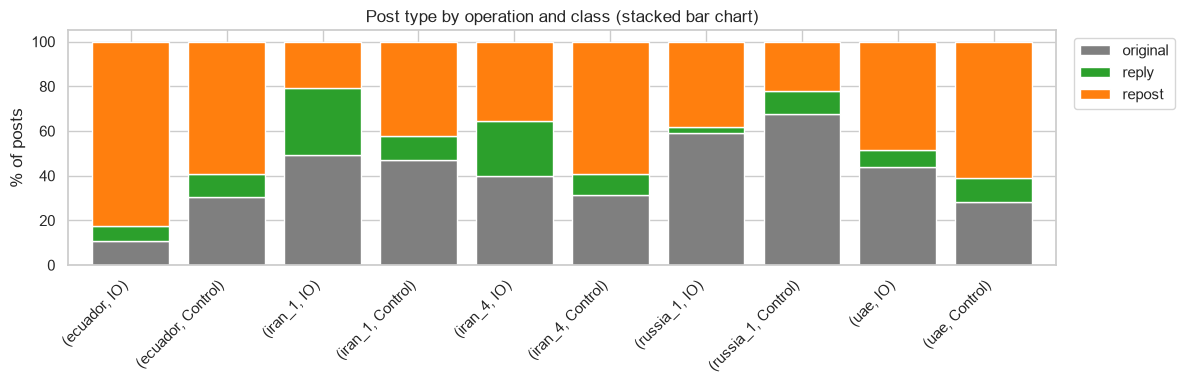

post_type          original   reply  repost
ioCountry class                            
ecuador   IO        10.9000  6.6000 82.5000
          Control   30.6000 10.1000 59.3000
iran_1    IO        49.1000 30.2000 20.7000
          Control   47.1000 10.8000 42.1000
iran_4    IO        39.9000 24.6000 35.5000
          Control   31.3000  9.7000 59.0000
russia_1  IO        59.1000  2.7000 38.2000
          Control   67.7000 10.0000 22.3000
uae       IO        43.9000  7.5000 48.6000
          Control   28.3000 10.6000 61.1000

In [15]:
posts['post_type'] = pd.Categorical(np.select([posts['is_repost'], posts['is_reply']], ['repost', 'reply'], 'original'),
                                    categories=['original', 'reply', 'repost'])
ptype = posts.groupby(['ioCountry', 'class'], observed=True)['post_type'].value_counts(normalize=True).unstack()
ax = (ptype * 100).plot(kind='bar', stacked=True, figsize=(12, 4), color=['#7f7f7f', '#2ca02c', '#ff7f0e'], width=0.8)
ax.set_ylabel('% of posts')
ax.set_xlabel('')
ax.set_title('Post type by operation and class (stacked bar chart)')
ax.legend(bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
display((ptype * 100).round(1))

post_language          en      ru      ar      es      fr    und      fa     pt     tr  unknown
ioCountry class                                                                                
ecuador   IO       9.2000  0.7000  0.1000 79.7000  0.3000 3.1000  0.0000 0.4000 0.1000   3.9000
          Control 19.0000  0.1000  0.3000 65.2000  0.7000 6.6000  0.0000 3.2000 0.1000   0.0000
iran_1    IO      24.7000  3.6000 13.7000  5.8000 28.8000 3.8000  8.2000 0.1000 8.2000   0.5000
          Control 59.3000  0.9000  4.9000 18.4000  2.6000 4.9000  0.4000 1.1000 1.1000   0.0000
iran_4    IO      12.7000  0.0000 11.6000  0.0000  0.1000 5.8000 68.9000 0.0000 0.4000   0.0000
          Control 44.0000  0.1000 34.7000  5.4000  1.0000 5.1000  5.2000 0.5000 0.5000   0.0000
russia_1  IO      32.6000 57.0000  0.4000  0.1000  0.1000 2.4000  0.0000 0.0000 0.0000   3.6000
          Control 44.1000 25.1000  2.2000  6.9000  2.2000 4.6000  0.0000 4.7000 0.3000   0.0000
uae       IO      17.0000  1.7000 60.5000  3.3000  2.6000 5.2000  2.4000 0.8000 1.9000   0.3000
          Control 25.9000  0.1000 59.2000  2.2000  0.7000 5.3000  0.4000 1.3000 0.4000   0.0000

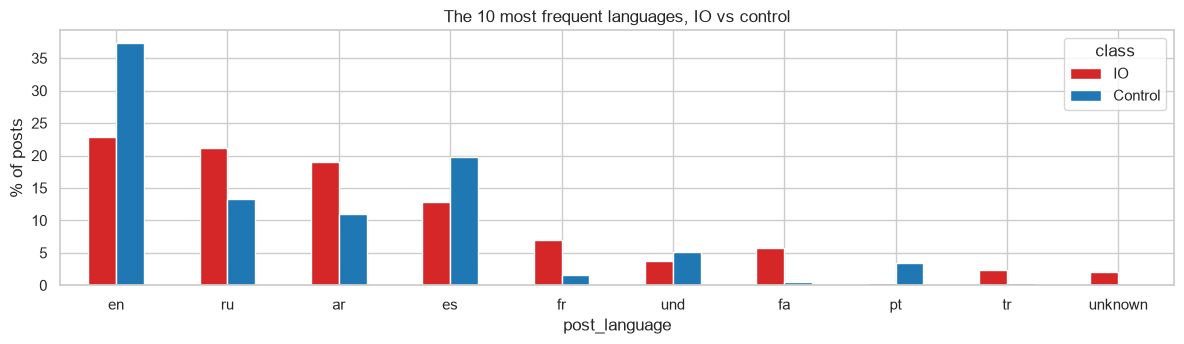

In [16]:
# Language: share of the most frequent languages in every operation x class group (table) + bar chart
top_lang = posts['post_language'].value_counts().head(10).index
lang_share = (posts.groupby(['ioCountry', 'class'], observed=True)['post_language'].value_counts(normalize=True)
              .unstack('post_language')[top_lang] * 100)
display(lang_share.round(1))
lang_cls = (posts.groupby('class', observed=True)['post_language'].value_counts(normalize=True)
            .unstack('post_language')[top_lang] * 100)
ax = lang_cls.T.plot(kind='bar', figsize=(12, 3.6), color=[CLASS_PALETTE[c] for c in lang_cls.index], rot=0)
ax.set_ylabel('% of posts')
ax.set_title('The 10 most frequent languages, IO vs control')
plt.tight_layout()
plt.show()

In [17]:
# Publishing client (anonymised): concentration of the distribution and its entropy ([SIM] pp. 20-22)
app_stats = []
for (op, cls), grp_ in posts.groupby(['ioCountry', 'class'], observed=True):
    vc = grp_['application_name'].value_counts()
    vc = vc[vc > 0]
    app_stats.append({'ioCountry': op, 'class': cls, 'distinct apps': len(vc),
                      'top-1 app share %': 100 * vc.iloc[0] / vc.sum(),
                      'top-3 apps share %': 100 * vc.iloc[:3].sum() / vc.sum(), 'entropy (bits)': entropy_bits(vc)})
display(pd.DataFrame(app_stats).set_index(['ioCountry', 'class']).round(2))

distinct apps  top-1 app share %  top-3 apps share %  entropy (bits)
ioCountry class                                                                        
ecuador   IO                  73            31.0700             90.3900          2.1800
          Control            759            39.0800             73.2300          3.5000
iran_1    IO                 124            62.2800             77.8800          2.2400
          Control            462            22.1900             52.6600          4.6600
iran_4    IO                  42            53.9500             94.5400          1.7700
          Control            460            28.4400             70.4300          3.7200
russia_1  IO                 257            28.7000             52.3400          4.0100
          Control           2343            18.7000             39.0700          5.4900
uae       IO                  71            35.8500             81.7600          2.4400
          Control            552            33.6500             76.2200          3.4300

* **Post type.** The IO–control difference changes direction across operations: Ecuador IO accounts mostly repost,
  Russian IO accounts mostly publish original content and almost never reply, Iranian IO accounts reply much more
  than their controls.
* **Language** follows the audience of each operation (Spanish in Ecuador, Arabic in UAE, Persian in Iran_4,
  Russian/English in Russia); Iran_1 IO accounts are strongly multilingual (French, English, Arabic, Turkish).
* **Clients.** In every operation IO posts use far fewer distinct applications, more concentrated on the top ones
  (lower entropy), consistent with centrally managed accounts using the same tools.

### 1.3.3 Content descriptors and descriptive statistics

mean     std    min     25%      50%      75%        max     mode     IQR     MAD
IO      text_len   126.4900 57.3500 1.0000 90.0000 123.0000 155.0000 2,249.0000 120.0000 65.0000 32.0000
        n_words     13.2400  7.1600 1.0000  8.0000  12.0000  17.0000    75.0000  10.0000  9.0000  4.0000
        n_hashtags   0.7300  1.3900 0.0000  0.0000   0.0000   1.0000    28.0000   0.0000  1.0000  0.0000
        n_urls       0.6600  0.6500 0.0000  0.0000   1.0000   1.0000     6.0000   1.0000  1.0000  1.0000
        n_mentions   0.7600  0.9500 0.0000  0.0000   1.0000   1.0000    50.0000   1.0000  1.0000  1.0000
Control text_len   143.9100 97.6600 1.0000 95.0000 135.0000 167.0000 2,531.0000 166.0000 72.0000 36.0000
        n_words     14.5900  8.9200 1.0000  9.0000  13.0000  18.0000   102.0000  13.0000  9.0000  5.0000
        n_hashtags   1.6000  2.3200 0.0000  0.0000   1.0000   2.0000    34.0000   0.0000  2.0000  1.0000
        n_urls       0.6900  0.6000 0.0000  0.0000   1.0000   1.0000     8.0000   1.0000  1.0000  0.0000
        n_mentions   0.9100  1.9100 0.0000  0.0000   1.0000   1.0000    51.0000   0.0000  1.0000  1.0000

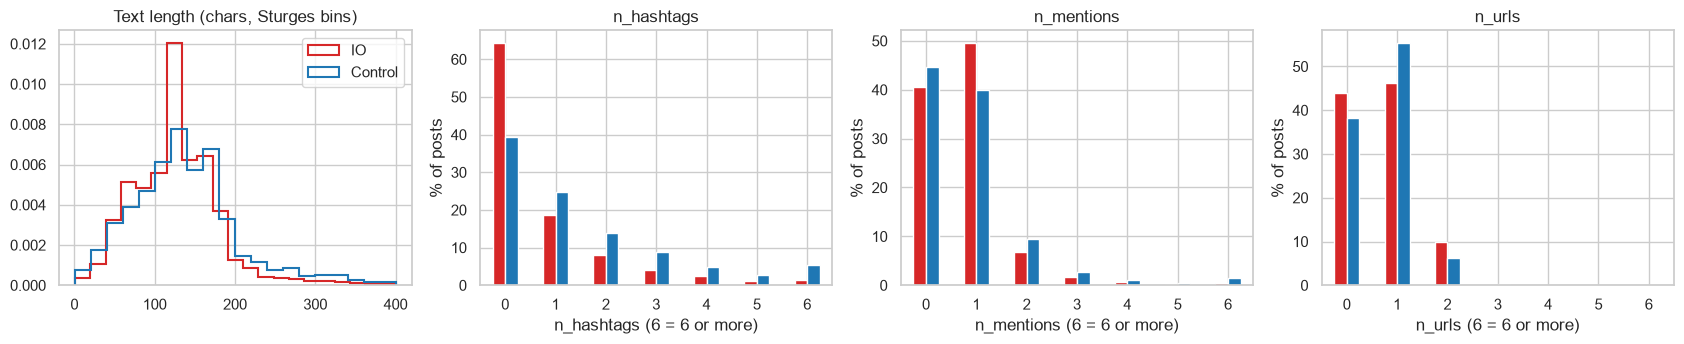

In [18]:
num_post_cols = ['text_len', 'n_words', 'n_hashtags', 'n_urls', 'n_mentions']


def describe_plus(df: pd.DataFrame) -> pd.DataFrame:
    """Central tendency and dispersion ([DU] pp. 31-33): mean, median, mode, std, five-number summary, IQR, MAD."""
    d = df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
    d['mode'] = df.mode().iloc[0]
    d['IQR'] = d['75%'] - d['25%']
    d['MAD'] = (df - df.median()).abs().median()
    return d


sample_posts = posts.sample(1_000_000, random_state=RANDOM_STATE)
desc = pd.concat({cls: describe_plus(sample_posts.loc[sample_posts['class'] == cls, num_post_cols])
                  for cls in CLASS_ORDER})
display(desc.round(2))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for cls in CLASS_ORDER:
    v = sample_posts.loc[(sample_posts['class'] == cls) & (sample_posts['text_len'] <= 400), 'text_len']
    axes[0].hist(v, bins=sturges_bins(len(v)), density=True, histtype='step', lw=1.5, color=CLASS_PALETTE[cls],
                 label=cls)
axes[0].set_title(f'Text length (chars, Sturges bins)')
axes[0].legend()
for ax, col in zip(axes[1:], ['n_hashtags', 'n_mentions', 'n_urls']):
    share = (sample_posts.assign(v=sample_posts[col].clip(upper=6)).groupby('class', observed=True)['v']
             .value_counts(normalize=True).unstack('class')[CLASS_ORDER] * 100)
    share.plot(kind='bar', ax=ax, color=[CLASS_PALETTE[c] for c in CLASS_ORDER], rot=0, legend=False)
    ax.set_xlabel(f'{col} (6 = 6 or more)')
    ax.set_ylabel('% of posts')
    ax.set_title(col)
plt.tight_layout()
plt.show()

IO posts contain fewer hashtags and mentions than control posts, and the IO text-length histogram shows sharp peaks
(template-like messages of identical length). Text length is positively skewed ([DU] pp. 25–26): mean > median.

### 1.3.4 Account-level attributes

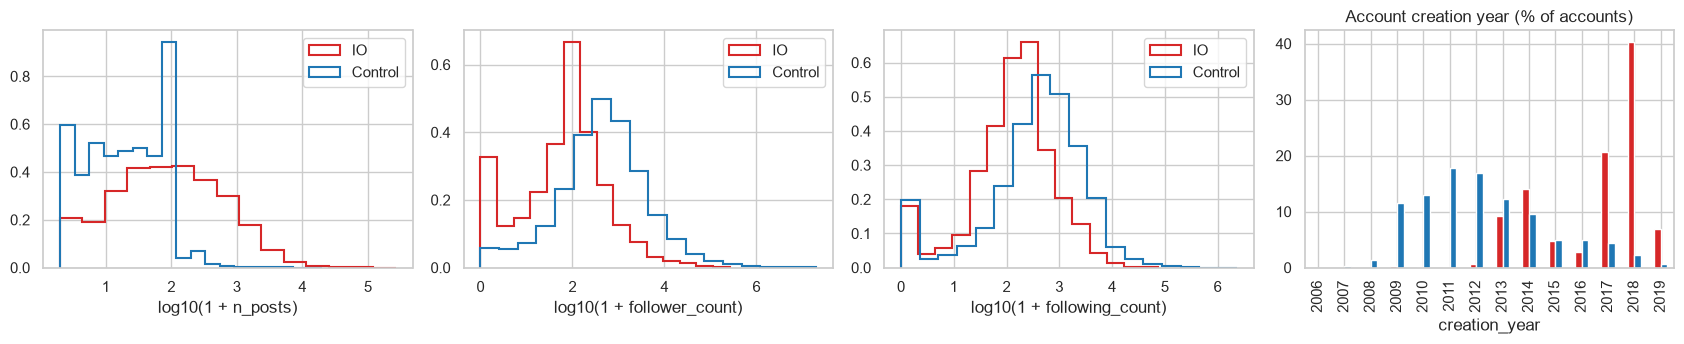

,median n_posts,median follower_count,median following_count
class,,,
IO,88.0000,85.0000,157.0000
Control,20.0000,477.0000,474.0000


In [19]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col in zip(axes, ['n_posts', 'follower_count', 'following_count']):
    for cls in CLASS_ORDER:
        v = np.log10(1 + acc.loc[acc['class'] == cls, col])
        ax.hist(v, bins=sturges_bins(len(v)), density=True, histtype='step', lw=1.5, color=CLASS_PALETTE[cls],
                label=cls)
    ax.set_xlabel(f'log10(1 + {col})')
    ax.legend()
acc['creation_year'] = acc['account_creation_date'].dt.year
cy = acc.groupby('class', observed=True)['creation_year'].value_counts(normalize=True).unstack('class')[CLASS_ORDER]
(cy * 100).plot(kind='bar', ax=axes[3], color=[CLASS_PALETTE[c] for c in CLASS_ORDER], legend=False)
axes[3].set_title('Account creation year (% of accounts)')
plt.tight_layout()
plt.show()
display(acc.groupby('class', observed=True)[['n_posts', 'follower_count', 'following_count']].median()
        .rename(columns=lambda c: f'median {c}'))

* IO accounts have many more posts than control accounts – mostly a consequence of the sampling design (1.2.6: the
  control quota of ≈100 posts per account is visible as a peak at log10(101) ≈ 2).
* IO accounts have **far fewer followers and following**, with a group of IO accounts with zero followers.
* IO accounts were **created in waves** (2013–2014, 2017 and especially 2018), consistent with batches of accounts
  registered for a campaign; control accounts are older and spread over 2009–2016.

## 1.4 Correlations and redundancies

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Covariance and Pearson's correlation coefficient | [DU] pp. 49–56; [SIM] p. 17 |
| Spearman's rank correlation | [DU] p. 59 |
| Visualisation of a correlation matrix | [DU] p. 60 |
| Scatter plot | [DU] pp. 39–42 |
| Contingency table and χ² test for nominal attributes | [DU] p. 17 |
| Mutual information between nominal attributes | [SIM] pp. 23–24 |
| Redundant features | [DP] pp. 14, 17–18 |

### 1.4.1 Numerical attributes (post level)

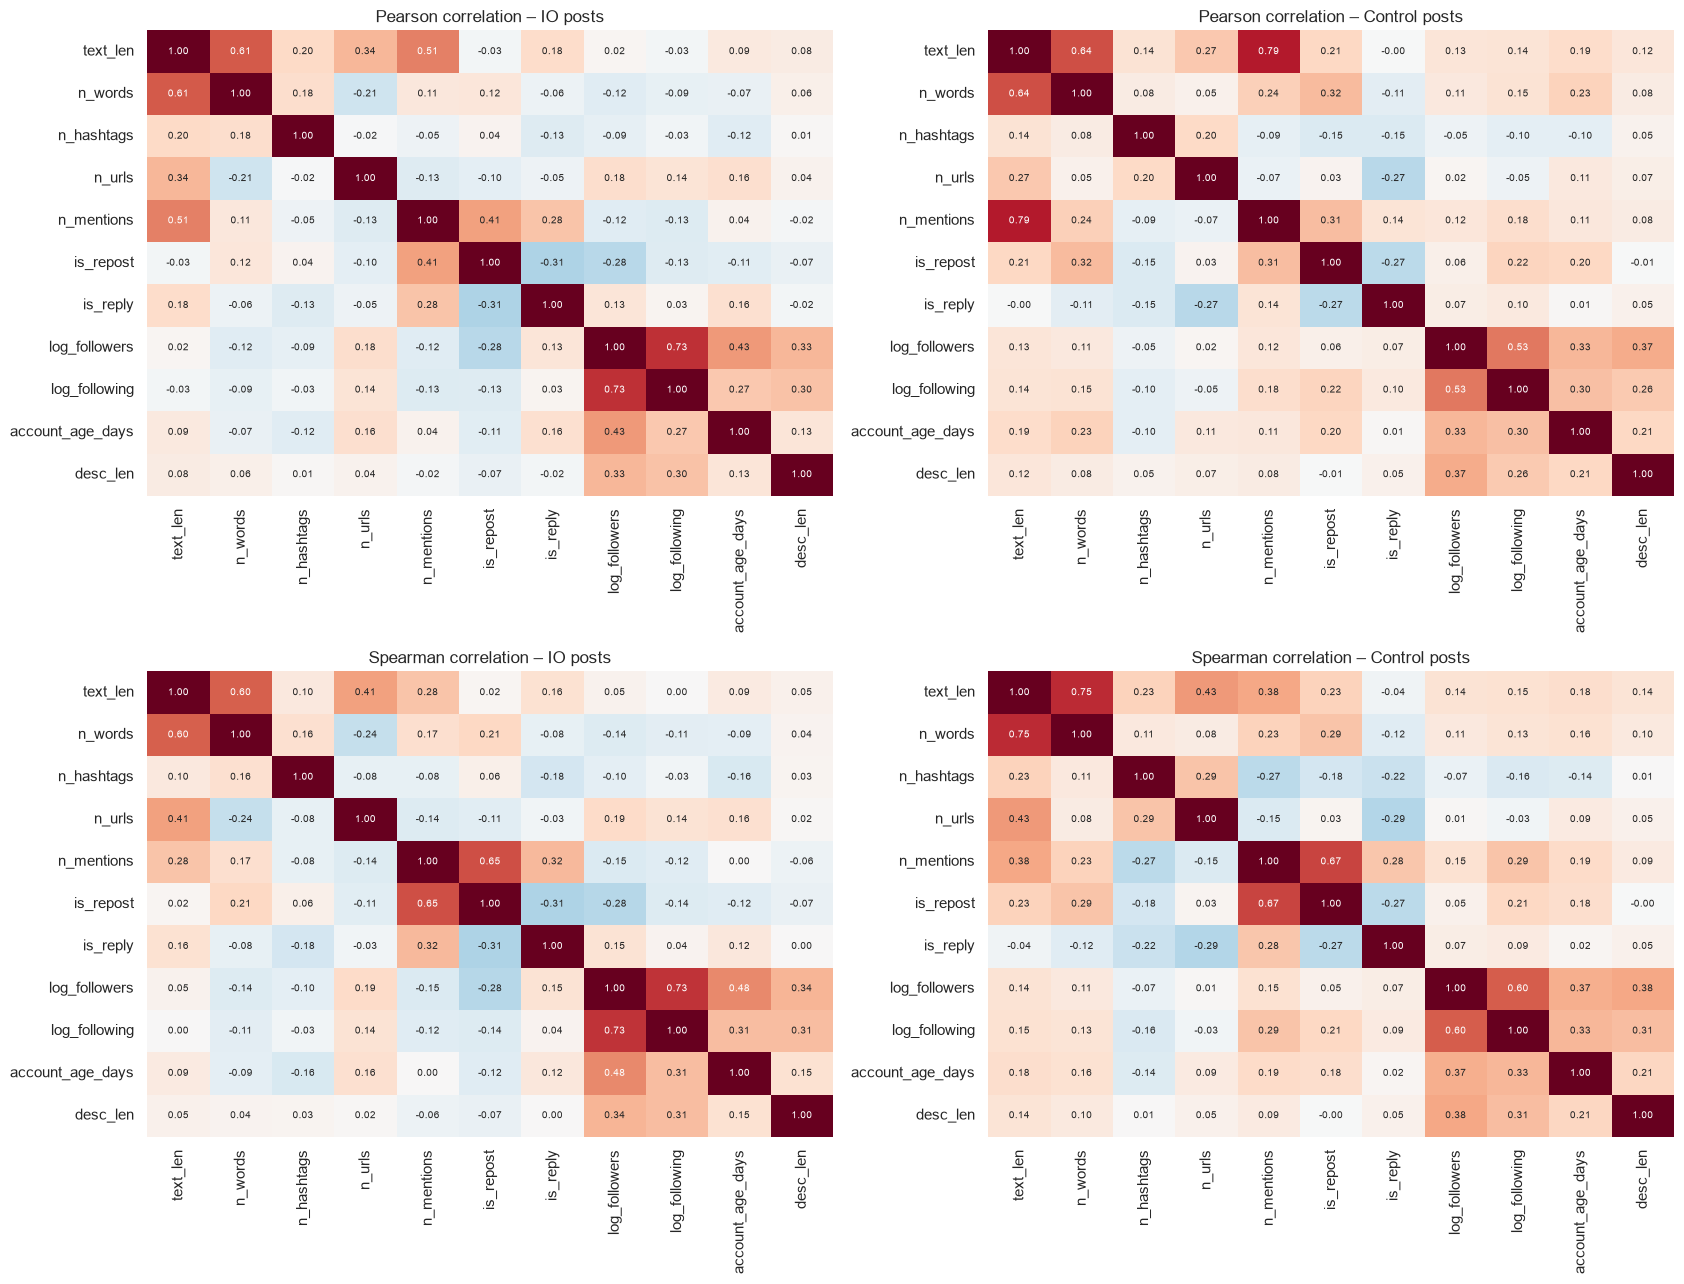

In [20]:
corr_df = sample_posts.assign(
    is_repost=sample_posts['is_repost'].astype(int), is_reply=sample_posts['is_reply'].astype(int),
    log_followers=np.log10(1 + sample_posts['follower_count']),
    log_following=np.log10(1 + sample_posts['following_count']),
    account_age_days=(sample_posts['post_time'] - sample_posts['account_creation_date']).dt.days,
    desc_len=sample_posts['desc_len'].fillna(0))
corr_cols = ['text_len', 'n_words', 'n_hashtags', 'n_urls', 'n_mentions', 'is_repost', 'is_reply',
             'log_followers', 'log_following', 'account_age_days', 'desc_len']
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
for i, method in enumerate(['pearson', 'spearman']):
    for j, cls in enumerate(CLASS_ORDER):
        cm = corr_df.loc[corr_df['class'] == cls, corr_cols].corr(method=method)
        sns.heatmap(cm, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=axes[i, j], cbar=False,
                    annot_kws={'size': 7})
        axes[i, j].set_title(f'{method.capitalize()} correlation – {cls} posts')
plt.tight_layout()
plt.show()

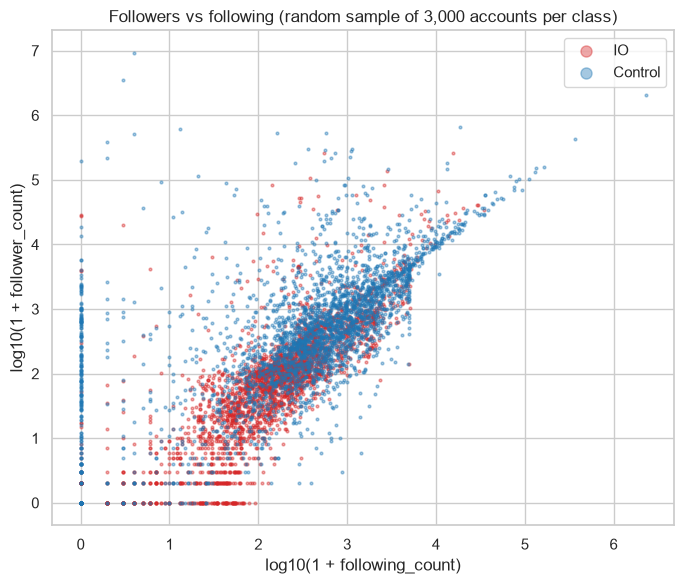

IO: Pearson (log-log) = 0.83 | Spearman = 0.85
Control: Pearson (log-log) = 0.61 | Spearman = 0.67


In [21]:
# Scatter plot (log-log) of followers vs following for a random sample of accounts of each class
sc_sample = acc.groupby('class', observed=True).sample(3000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(7, 6))
for cls in CLASS_ORDER:
    s = sc_sample[sc_sample['class'] == cls]
    ax.scatter(np.log10(1 + s['following_count']), np.log10(1 + s['follower_count']), s=4, alpha=0.4,
               color=CLASS_PALETTE[cls], label=cls)
ax.set_xlabel('log10(1 + following_count)')
ax.set_ylabel('log10(1 + follower_count)')
ax.legend(markerscale=4)
ax.set_title('Followers vs following (random sample of 3,000 accounts per class)')
plt.tight_layout()
plt.show()
for cls in CLASS_ORDER:
    a = acc[acc['class'] == cls]
    print(f'{cls}: Pearson (log-log) = {np.corrcoef(np.log10(1 + a["following_count"]), np.log10(1 + a["follower_count"]))[0, 1]:.2f}'
          f' | Spearman = {stats.spearmanr(a["following_count"], a["follower_count"]).statistic:.2f}')

### 1.4.2 Nominal attributes: contingency tables, χ² test and mutual information

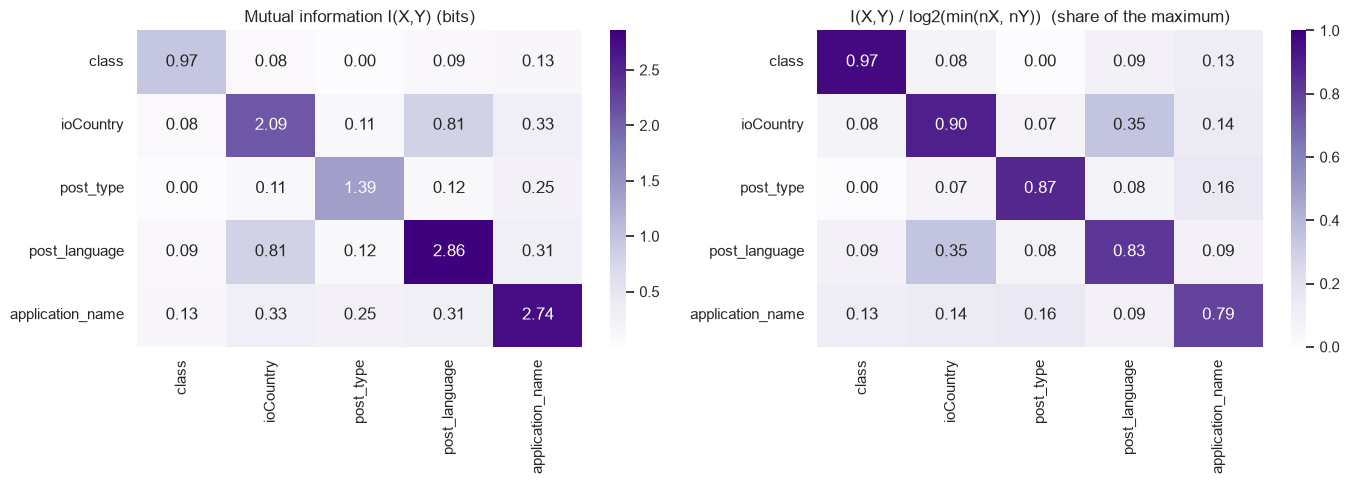

Contingency table class x post_type (sample of 300k posts):


post_type,original,reply,repost
class,,,
IO,82080,20663,77452
Control,60601,12292,46912


chi2 = 733, dof = 2, p-value = 8.14e-160


81221

In [22]:
cs = sample_posts.sample(300_000, random_state=RANDOM_STATE)
cat_vars = {'class': cs['class'].astype(str), 'ioCountry': cs['ioCountry'].astype(str),
            'post_type': cs['post_type'].astype(str),
            'post_language': cs['post_language'].astype(str).where(cs['post_language'].isin(top_lang), 'other'),
            'application_name': cs['application_name'].astype(str).where(
                cs['application_name'].isin(posts['application_name'].value_counts().head(10).index), 'other')}
mi = pd.DataFrame(index=cat_vars, columns=cat_vars, dtype=float)
for a in cat_vars:
    for b in cat_vars:
        mi.loc[a, b] = mutual_information_bits(cat_vars[a], cat_vars[b])
mi_rel = mi.copy()
for a in cat_vars:
    for b in cat_vars:  # maximum possible value: log2(min(nX, nY)), [SIM] p. 23
        mi_rel.loc[a, b] = mi.loc[a, b] / np.log2(min(cat_vars[a].nunique(), cat_vars[b].nunique()))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(mi, annot=True, fmt='.2f', cmap='Purples', ax=axes[0])
axes[0].set_title('Mutual information I(X,Y) (bits)')
sns.heatmap(mi_rel, annot=True, fmt='.2f', cmap='Purples', vmin=0, vmax=1, ax=axes[1])
axes[1].set_title('I(X,Y) / log2(min(nX, nY))  (share of the maximum)')
plt.tight_layout()
plt.show()

ct = pd.crosstab(cs['class'], cs['post_type'])
chi2, pval, dof, _ = stats.chi2_contingency(ct)
print('Contingency table class x post_type (sample of 300k posts):')
display(ct)
print(f'chi2 = {chi2:,.0f}, dof = {dof}, p-value = {pval:.2e}')
del corr_df, cs, cat_vars
gc.collect()

**Redundancies found** (and how they are handled):

* `text_len` and `n_words` are strongly correlated (Pearson and Spearman ≈ 0.75–0.8) → only the text length is used.
* `n_mentions` is strongly correlated with `is_repost` (≈ 0.65): a repost always mentions the original author.
* `log_followers` and `log_following` are correlated (≈ 0.6–0.7 at post level; at account level 0.61 for control and
  0.83 for IO accounts, Pearson on the log scale) but not redundant: their balance is informative.
* Repost identifiers are fully determined by `is_repost`; reply identifiers carry the same information as `is_reply`;
  account attributes repeated on every post are moved to the profile.
* Among nominal attributes, `post_language` shares a lot of information with the operation, and
  `application_name` is the attribute most informative about the class. The post type is almost independent of
  the class **globally** (very low mutual information), although it differs a lot within each operation (1.3.2):
  differences in opposite directions cancel out when operations are pooled, so comparisons must be made per
  operation. With 300k posts every χ² test is significant, so the strength of the dependence (mutual
  information) is more informative than the p-value.

## 1.5 User profiling and feature engineering

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Aggregation of objects (posts → accounts) | [DP] p. 4 |
| Feature creation / construction | [DP] pp. 20–22 |
| Entropy of a nominal attribute for sample data | [SIM] pp. 20–22; [DU] p. 17 |
| Mean and standard deviation (burstiness), median, quartiles, IQR | [DU] pp. 31–34 |
| Selection of records (minimum number of posts) | [DP] p. 2 |
| Conditional box plots, histograms | [DU] pp. 28–30, 34, 37 |
| Spearman correlation matrix and redundant features | [DU] pp. 59–60; [DP] pp. 14, 17–18 |
| Scatter matrix | [DU] p. 41 |
| Radar plot, min-max normalisation | [DU] p. 47; [DP] p. 47 |

Starting from the cleaned post-level table we build **one profile per account**, identified by the composite key
**(ioCountry, accountid)**. For an account $u$ let $P_u$ be its posts, $N_u = |P_u|$, $c(u)$ its operation and
$\mathbb{1}[\cdot]$ the indicator function. Entropies use $H(X) = -\sum_x p_x \log_2 p_x$, where $p_x$ is the share
of the account's posts with value $x$ ([SIM] p. 22).

**A. Activity and time** (reliable timestamps, but **not comparable** between IO and control because of the
day-bounded control sample, 1.2.6)

| Feature | What it captures | Formula |
|---|---|---|
| `n_posts` | volume of activity | $N_u$ |
| `rel_activity` | activity compared with the typical account of the same operation (unusually active accounts) | $\log_{10}\big(N_u / \operatorname{median}_{v: c(v)=c(u)} N_v\big)$ |
| `active_days` | number of distinct days with at least one post | $\lvert\{\text{day}(p) : p \in P_u\}\rvert$ |
| `lifespan_days` | observed activity period | $\max_p t_p - \min_p t_p$ (days) |
| `posts_per_active_day` | posting intensity on active days | $N_u / \text{active\_days}$ |
| `max_day_share` | temporal concentration: share of posts on the most active day | $\max_d n_{u,d} / N_u$ |
| `max_week_share` | the same on a weekly basis | $\max_w n_{u,w} / N_u$ |
| `hour_entropy` | regularity of the daily rhythm (0 = always the same hour, 1 = uniform over 24 hours) | $H(\text{hour}) / \log_2 24$ |
| `burstiness` | burstiness of the inter-post times $\tau$ (−1 periodic, 0 random, →1 bursty); $N_u \ge 3$ | $B = (\sigma_\tau - \mu_\tau)/(\sigma_\tau + \mu_\tau)$ |

**B. Interaction and broadcasting**

| Feature | What it captures | Formula |
|---|---|---|
| `repost_ratio` | amplification of other content | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ repost}]$ |
| `reply_ratio` | conversational activity | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ reply}]$ |
| `original_ratio` | own broadcast content | $1 - \text{repost\_ratio} - \text{reply\_ratio}$ |
| `interaction_ratio` | posts that directly address other accounts (replies, or original posts with mentions) | $\frac{1}{N_u}\sum_p \mathbb{1}[p \text{ reply} \lor (p \text{ not repost} \land m_p > 0)]$ |
| `broadcast_index` | balance between amplification and conversation, in $[-1, 1]$ | $\text{repost\_ratio} - \text{interaction\_ratio}$ |
| `self_repost_ratio` | self-amplification (reposting own posts) | $\frac{1}{N_u}\sum_p \mathbb{1}[\text{src}(p) = u]$ |
| `in_network_repost_ratio` | coordinated amplification: reposts of **other accounts of the same operation** present in the dataset (composite key, so only the same `ioCountry`) | $\frac{1}{N_u}\sum_p \mathbb{1}[\text{src}(p) \in A_{c(u)} \setminus \{u\}]$ |
| `top_reposted_share` | concentration of the reposted sources (NaN without reposts) | $\max_a r_{u,a} / \sum_a r_{u,a}$ |

**C. Content and platform**

| Feature | What it captures | Formula |
|---|---|---|
| `hashtags_per_post`, `urls_per_post`, `mentions_per_post` | use of hashtags / links / mentions | $\frac{1}{N_u}\sum_p h_p$ (same for URLs, mentions) |
| `mean_text_len` | average post length (characters) | $\frac{1}{N_u}\sum_p \text{len}(p)$ |
| `lang_entropy`, `n_languages` | one or several languages (`unknown` is a category) | $H(\text{post\_language})$, number of distinct languages |
| `app_entropy`, `n_apps` | one or several publishing clients | $H(\text{application\_name})$, number of distinct clients |
| `dup_text_share` | **copy-paste coordination**: original (non-repost) posts whose normalised text (≥ 20 characters) is also published by at least one *other account of the same operation* | $\frac{1}{N_u}\sum_{p \text{ not repost}} \mathbb{1}[\lvert\{v \in A_{c(u)} : \text{text}_p \in T_v\}\rvert \ge 2]$ |

**D. Account attributes**

| Feature | What it captures | Formula |
|---|---|---|
| `follower_count`, `following_count` | audience and social activity (cleaned snapshot) | used as $\log_{10}(1+x)$ |
| `follower_following_ratio` | balance between audience and followed accounts | $\log_{10}\frac{1+\text{followers}}{1+\text{following}}$ |
| `account_age_days` | age of the account when it posts | $\operatorname{median}_p (t_p - \text{creation\_date})$ (days) |
| `desc_len`, `has_description` | effort put in the profile | biography length (0 if missing), $\mathbb{1}[\text{biography present}]$ |

In [23]:
t0 = time.time()
p = posts                       # cleaned post-level table
g = p.groupby('acc_key', sort=True)
prof = pd.DataFrame({
    'ioCountry': g['ioCountry'].first(),
    'accountid': g['accountid'].first().astype(str),
    'is_control': g['is_control'].first(),
    'n_posts': g.size(),
    'n_reposts': g['is_repost'].sum(),
    'n_replies': g['is_reply'].sum(),
    'hashtags_per_post': g['n_hashtags'].mean(),
    'urls_per_post': g['n_urls'].mean(),
    'mentions_per_post': g['n_mentions'].mean(),
    'mean_text_len': g['text_len'].mean().astype(float),
    'follower_count': g['follower_count'].first(),
    'following_count': g['following_count'].first(),
    'desc_len': g['desc_len'].first().fillna(0).astype(float),
})
prof['class'] = pd.Categorical(np.where(prof['is_control'], 'Control', 'IO'), categories=CLASS_ORDER)

# --- A. activity and time ---
day_num = p['post_time'].to_numpy().astype('datetime64[D]').astype(np.int64)
day_counts = pd.Series(1, index=p.index).groupby([p['acc_key'], day_num]).size()
week_counts = pd.Series(1, index=p.index).groupby([p['acc_key'], (day_num + 3) // 7]).size()  # weeks from Monday
prof['active_days'] = day_counts.groupby(level=0).size()
prof['max_day_share'] = day_counts.groupby(level=0).max() / prof['n_posts']
prof['max_week_share'] = week_counts.groupby(level=0).max() / prof['n_posts']
prof['posts_per_active_day'] = prof['n_posts'] / prof['active_days']
prof['lifespan_days'] = (g['post_time'].max() - g['post_time'].min()).dt.total_seconds() / 86400
op_median = prof.groupby('ioCountry', observed=True)['n_posts'].median()
prof['rel_activity'] = np.log10(prof['n_posts'] / prof['ioCountry'].map(op_median).astype(float))
del day_counts, week_counts


def group_entropy(acc_key: pd.Series, values: pd.Series) -> pd.DataFrame:
    """Entropy (bits) of the distribution of `values` inside every account and number of distinct values."""
    cnt = pd.Series(1, index=acc_key.index).groupby([acc_key, values]).size()
    cnt = cnt[cnt > 0]
    share = cnt / cnt.groupby(level=0).transform('sum')
    ent = -(share * np.log2(share)).groupby(level=0).sum() + 0.0      # "+ 0.0" turns -0.0 into 0.0
    return pd.DataFrame({'entropy': ent, 'n_distinct': cnt.groupby(level=0).size()})


e = group_entropy(p['acc_key'], p['post_time'].dt.hour)
prof['hour_entropy'] = e['entropy'] / np.log2(24)
e = group_entropy(p['acc_key'], p['post_language'].cat.codes)
prof['lang_entropy'], prof['n_languages'] = e['entropy'], e['n_distinct']
e = group_entropy(p['acc_key'], p['application_name'].cat.codes)
prof['app_entropy'], prof['n_apps'] = e['entropy'], e['n_distinct']
del e

# Burstiness of inter-post times (accounts with >= 3 posts)
srt = p[['acc_key', 'post_time']].sort_values(['acc_key', 'post_time'])
tsec = srt['post_time'].to_numpy().astype('datetime64[s]').astype(np.int64)
acc_arr = srt['acc_key'].to_numpy()
same = acc_arr[1:] == acc_arr[:-1]
gaps = pd.Series(np.diff(tsec)[same].astype(float), index=acc_arr[1:][same])
gstats = gaps.groupby(level=0).agg(['mean', 'std', 'size'])
burst = (gstats['std'] - gstats['mean']) / (gstats['std'] + gstats['mean'])
prof['burstiness'] = burst.where(gstats['size'] >= 2)
del srt, tsec, acc_arr, same, gaps, gstats, burst

# --- B. interaction and broadcasting ---
prof['repost_ratio'] = prof['n_reposts'] / prof['n_posts']
prof['reply_ratio'] = prof['n_replies'] / prof['n_posts']
prof['original_ratio'] = 1 - prof['repost_ratio'] - prof['reply_ratio']
interactive = p['is_reply'] | (~p['is_repost'] & (p['n_mentions'] > 0))
prof['interaction_ratio'] = interactive.groupby(p['acc_key']).sum() / prof['n_posts']
prof['broadcast_index'] = prof['repost_ratio'] - prof['interaction_ratio']

reposts = p.loc[p['is_repost'], ['acc_key', 'rep_acc_key']]
self_rep = reposts['rep_acc_key'] == reposts['acc_key']
prof['self_repost_ratio'] = (self_rep.groupby(reposts['acc_key']).sum().reindex(prof.index, fill_value=0)
                             / prof['n_posts'])
# composite keys: a source is "in network" only if the same (ioCountry, accountid) exists in the dataset
in_net = reposts['rep_acc_key'].isin(prof.index) & ~self_rep
prof['in_network_repost_ratio'] = (in_net.groupby(reposts['acc_key']).sum().reindex(prof.index, fill_value=0)
                                   / prof['n_posts'])
src_counts = pd.Series(1, index=reposts.index).groupby([reposts['acc_key'], reposts['rep_acc_key']]).size()
prof['top_reposted_share'] = src_counts.groupby(level=0).max() / prof['n_reposts'].where(prof['n_reposts'] > 0)
del reposts, self_rep, in_net, src_counts, interactive

# --- C. duplicated (copy-pasted) content, counted within the same operation ---
orig = p.loc[~p['is_repost'] & (p['text_len'] >= 20), ['ioCountry', 'acc_key', 'text_h']]
acc_per_text = (orig.drop_duplicates(['ioCountry', 'text_h', 'acc_key'])
                .groupby(['ioCountry', 'text_h'], observed=True).size().rename('n_acc').reset_index())
orig = orig.merge(acc_per_text, on=['ioCountry', 'text_h'], how='left')
prof['dup_text_share'] = ((orig['n_acc'] > 1).groupby(orig['acc_key']).sum().reindex(prof.index, fill_value=0)
                          / prof['n_posts'])
del orig, acc_per_text

# --- D. account attributes ---
age_days = (p['post_time'] - p['account_creation_date']).dt.total_seconds() / 86400
prof['account_age_days'] = age_days.groupby(p['acc_key']).median()
prof['follower_following_ratio'] = np.log10((1 + prof['follower_count']) / (1 + prof['following_count']))
prof['has_description'] = (prof['desc_len'] > 0).astype(int)
del age_days, g
gc.collect()

prof = prof.reset_index()
prof.to_parquet(PROFILES_PQ, index=False)
print(f'Profiles: {prof.shape[0]:,} accounts x {prof.shape[1]} columns  ({time.time() - t0:.0f}s) -> {PROFILES_PQ.name}')
display(prof.head(3).T)

Profiles: 86,525 accounts x 39 columns  (13s) -> user_profiles.parquet


,0,1,2
acc_key,270973278975590,820257582910209,1530156752996448
ioCountry,iran_4,iran_1,russia_1
accountid,ec71f7cddaa0686abbe7afe874c46f7eb931c2b2df,a6a58a444f87a5294999dc38973ae27ad80b6f24b6,5c3699591eb65028c575d928d0a2858d64a2c38bc9
is_control,False,True,False
n_posts,9,11,782
n_reposts,0,11,524
n_replies,2,0,1
hashtags_per_post,0.0000,0.8182,0.8491
urls_per_post,0.1111,0.5455,0.2251
mentions_per_post,0.3333,1.0000,0.8747


### 1.5.1 Quality of the derived features

With one post every entropy is 0 and every share is 0 or 1, and burstiness needs at least three posts. We therefore
flag the accounts with at least `MIN_POSTS = 5` posts (selection of records, [DP] p. 2): they are the population
used in the profile analysis below and in the clustering.

In [24]:
MIN_POSTS = 5
FEATURES_A = ['n_posts', 'rel_activity', 'active_days', 'lifespan_days', 'posts_per_active_day', 'max_day_share',
              'max_week_share', 'hour_entropy', 'burstiness']
FEATURES_B = ['repost_ratio', 'reply_ratio', 'original_ratio', 'interaction_ratio', 'broadcast_index',
              'self_repost_ratio', 'in_network_repost_ratio', 'top_reposted_share']
FEATURES_C = ['hashtags_per_post', 'urls_per_post', 'mentions_per_post', 'mean_text_len', 'lang_entropy',
              'n_languages', 'app_entropy', 'n_apps', 'dup_text_share']
FEATURES_D = ['follower_count', 'following_count', 'follower_following_ratio', 'account_age_days', 'desc_len',
              'has_description']
ALL_FEATURES = FEATURES_A + FEATURES_B + FEATURES_C + FEATURES_D
GROUP_OF = {f: grp for grp, fs in zip('ABCD', [FEATURES_A, FEATURES_B, FEATURES_C, FEATURES_D]) for f in fs}

prof['enough_posts'] = prof['n_posts'] >= MIN_POSTS
print(pd.crosstab(prof['class'], prof['enough_posts'], margins=True))
na = prof[ALL_FEATURES].isna().sum()
print('Missing values in derived features:', na[na > 0].to_dict(),
      '(burstiness: < 3 posts; top_reposted_share: no reposts; mean_text_len: no text)')

enough_posts  False   True    All
class                            
IO              913  10004  10917
Control       16501  59107  75608
All           17414  69111  86525
Missing values in derived features: {'burstiness': 10616, 'top_reposted_share': 23505} (burstiness: < 3 posts; top_reposted_share: no reposts; mean_text_len: no text)


### 1.5.2 IO vs control on the profiles

For each feature we compare the two classes with medians and quartiles, and with the share of IO accounts whose
value is above the median of the control accounts (50% = no difference; a percentile-based summary, [DU] p. 34).

In [25]:
pe = prof[prof['enough_posts']].copy()
rows = []
for f in ALL_FEATURES:
    a = pe.loc[pe['class'] == 'IO', f].dropna()
    b = pe.loc[pe['class'] == 'Control', f].dropna()
    rows.append({'feature': f, 'group': GROUP_OF[f], 'median IO': a.median(), 'IQR IO': a.quantile(.75) - a.quantile(.25),
                 'median Control': b.median(), 'IQR Control': b.quantile(.75) - b.quantile(.25),
                 '% IO above control median': 100 * (a > b.median()).mean() + 50 * (a == b.median()).mean()})
cmp_tab = pd.DataFrame(rows).set_index('feature')
cmp_tab['distance from 50%'] = (cmp_tab['% IO above control median'] - 50).abs()
display(cmp_tab.sort_values('distance from 50%', ascending=False).round(3))

,group,median IO,IQR IO,median Control,IQR Control,% IO above control median,distance from 50%
feature,,,,,,,
max_day_share,A,0.1110,0.2000,1.0000,0.0000,0.3850,49.6150
active_days,A,30.0000,65.0000,1.0000,0.0000,99.6150,49.6150
max_week_share,A,0.2100,0.2900,1.0000,0.0000,1.2100,48.7900
posts_per_active_day,A,3.7220,4.3170,32.0000,71.4170,1.2690,48.7310
lifespan_days,A,143.0990,324.8610,0.8500,0.5800,98.6110,48.6110
account_age_days,D,95.7610,206.4710,848.6010,"1,275.2150",4.5780,45.4220
hour_entropy,A,0.7290,0.2410,0.4810,0.3030,87.9850,37.9850
follower_count,D,95.0000,219.2500,622.0000,"1,979.0000",12.8350,37.1650
n_apps,C,2.0000,2.0000,1.0000,1.0000,87.1250,37.1250


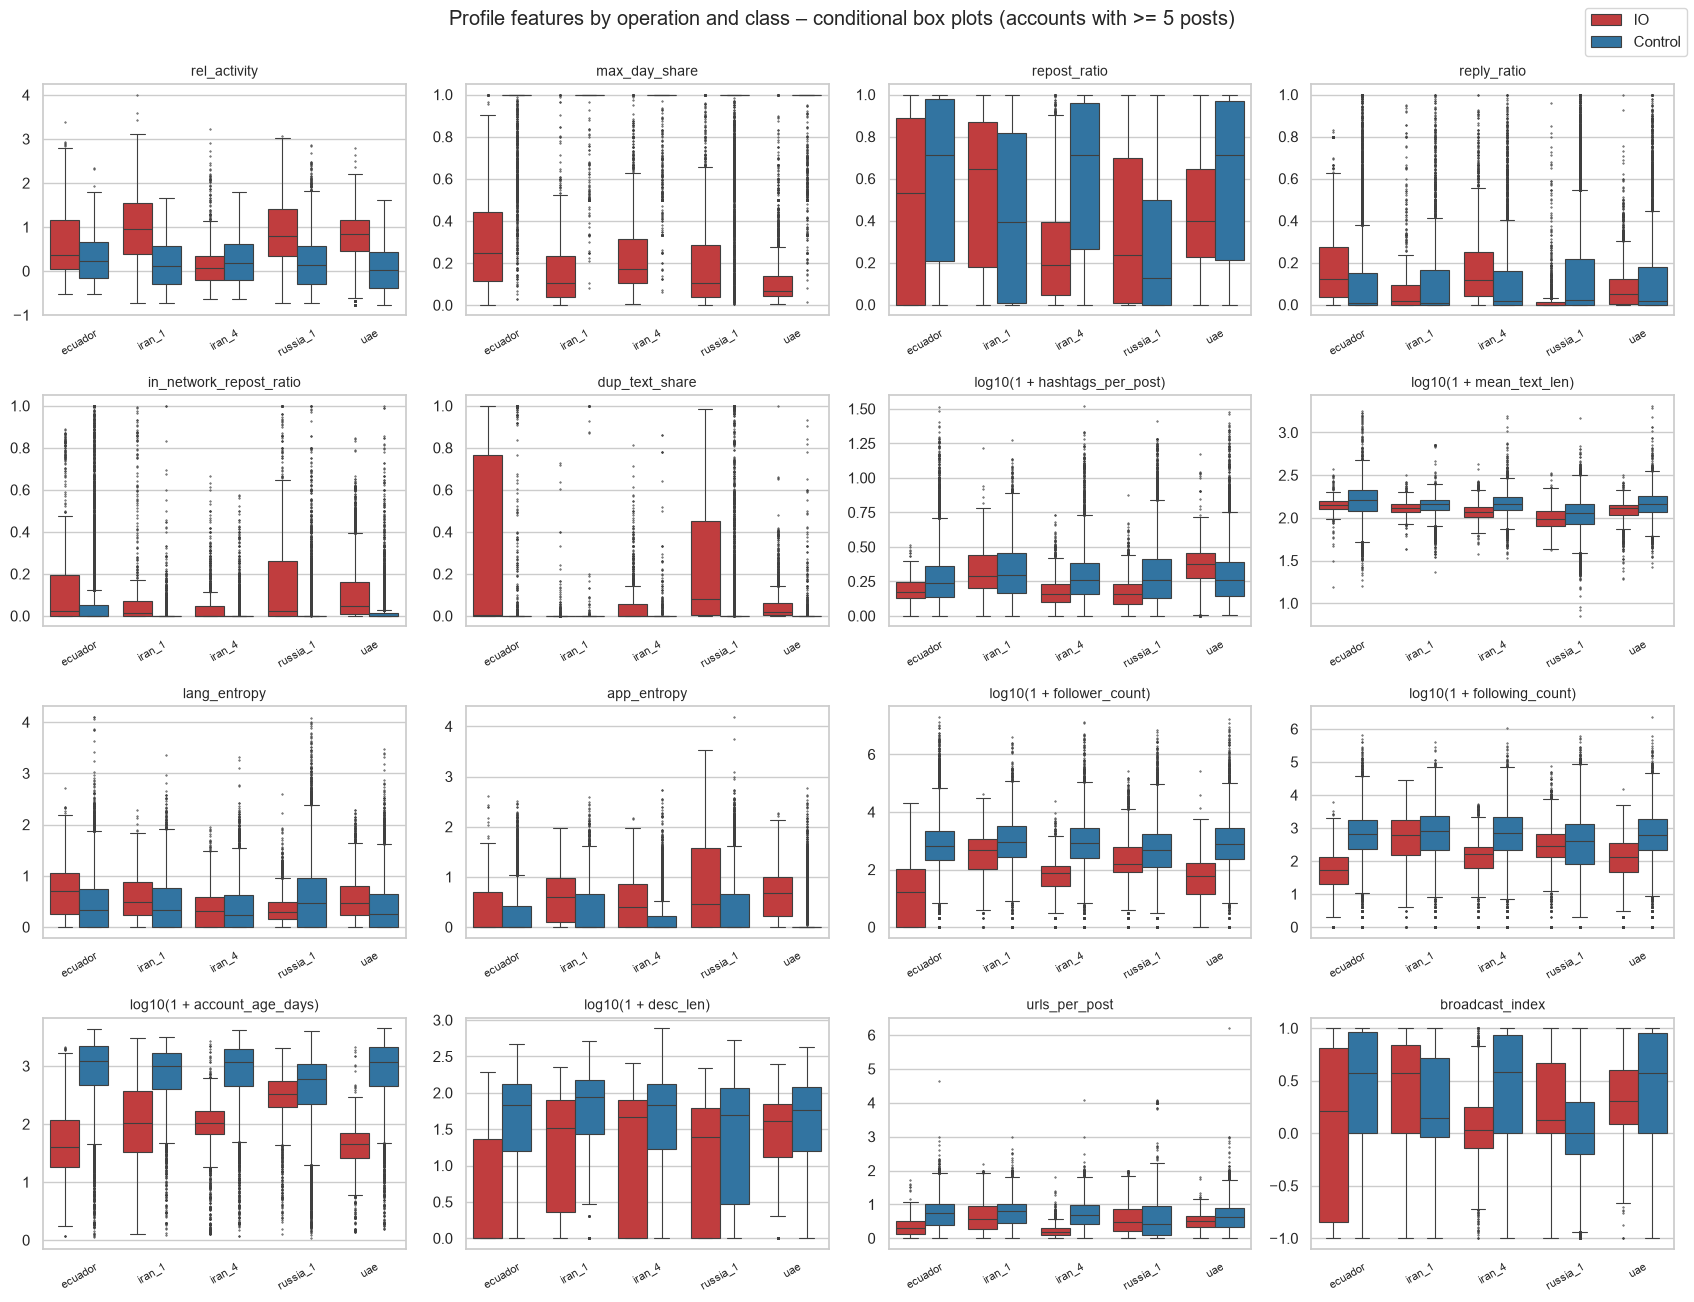

In [26]:
show = ['rel_activity', 'max_day_share', 'repost_ratio', 'reply_ratio', 'in_network_repost_ratio', 'dup_text_share',
        'hashtags_per_post', 'mean_text_len', 'lang_entropy', 'app_entropy', 'follower_count', 'following_count',
        'account_age_days', 'desc_len', 'urls_per_post', 'broadcast_index']
log_feats = {'follower_count', 'following_count', 'account_age_days', 'desc_len', 'hashtags_per_post', 'mean_text_len'}
fig, axes = plt.subplots(4, 4, figsize=(17, 13))
for ax, f in zip(axes.ravel(), show):
    y = np.log10(1 + pe[f]) if f in log_feats else pe[f]
    sns.boxplot(data=pe, x='ioCountry', y=y, hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER,
                ax=ax, fliersize=0.5, linewidth=0.8)
    ax.set_title(f'log10(1 + {f})' if f in log_feats else f, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.legend().remove()
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right')
fig.suptitle('Profile features by operation and class – conditional box plots (accounts with >= 5 posts)', y=1.0)
plt.tight_layout()
plt.show()

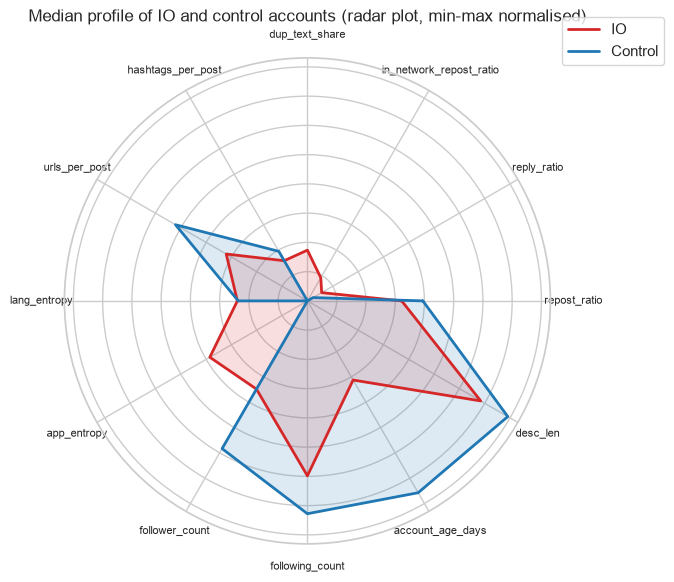

In [27]:
# Radar plot of the median profile of IO and control accounts (features min-max normalised on the class medians)
radar_feats = ['repost_ratio', 'reply_ratio', 'in_network_repost_ratio', 'dup_text_share', 'hashtags_per_post',
               'urls_per_post', 'lang_entropy', 'app_entropy', 'follower_count', 'following_count',
               'account_age_days', 'desc_len']
med = pe.groupby('class', observed=True)[radar_feats].median()
med_log = med.copy()
for f in ['follower_count', 'following_count', 'account_age_days', 'desc_len']:
    med_log[f] = np.log10(1 + med_log[f])
q = pe[radar_feats].copy()
for f in ['follower_count', 'following_count', 'account_age_days', 'desc_len']:
    q[f] = np.log10(1 + q[f])
lo, hi = q.quantile(0.05), q.quantile(0.95)
norm = ((med_log - lo) / (hi - lo).replace(0, 1)).clip(0, 1)     # min-max normalisation on the 5-95% range
angles = np.linspace(0, 2 * np.pi, len(radar_feats), endpoint=False).tolist()
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, polar=True)
for cls in CLASS_ORDER:
    vals = norm.loc[cls].tolist()
    ax.plot(angles + angles[:1], vals + vals[:1], color=CLASS_PALETTE[cls], lw=2, label=cls)
    ax.fill(angles + angles[:1], vals + vals[:1], color=CLASS_PALETTE[cls], alpha=0.15)
ax.set_xticks(angles)
ax.set_xticklabels(radar_feats, fontsize=8)
ax.set_yticklabels([])
ax.set_title('Median profile of IO and control accounts (radar plot, min-max normalised)')
ax.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1))
plt.tight_layout()
plt.show()

### 1.5.3 Correlations between the derived features

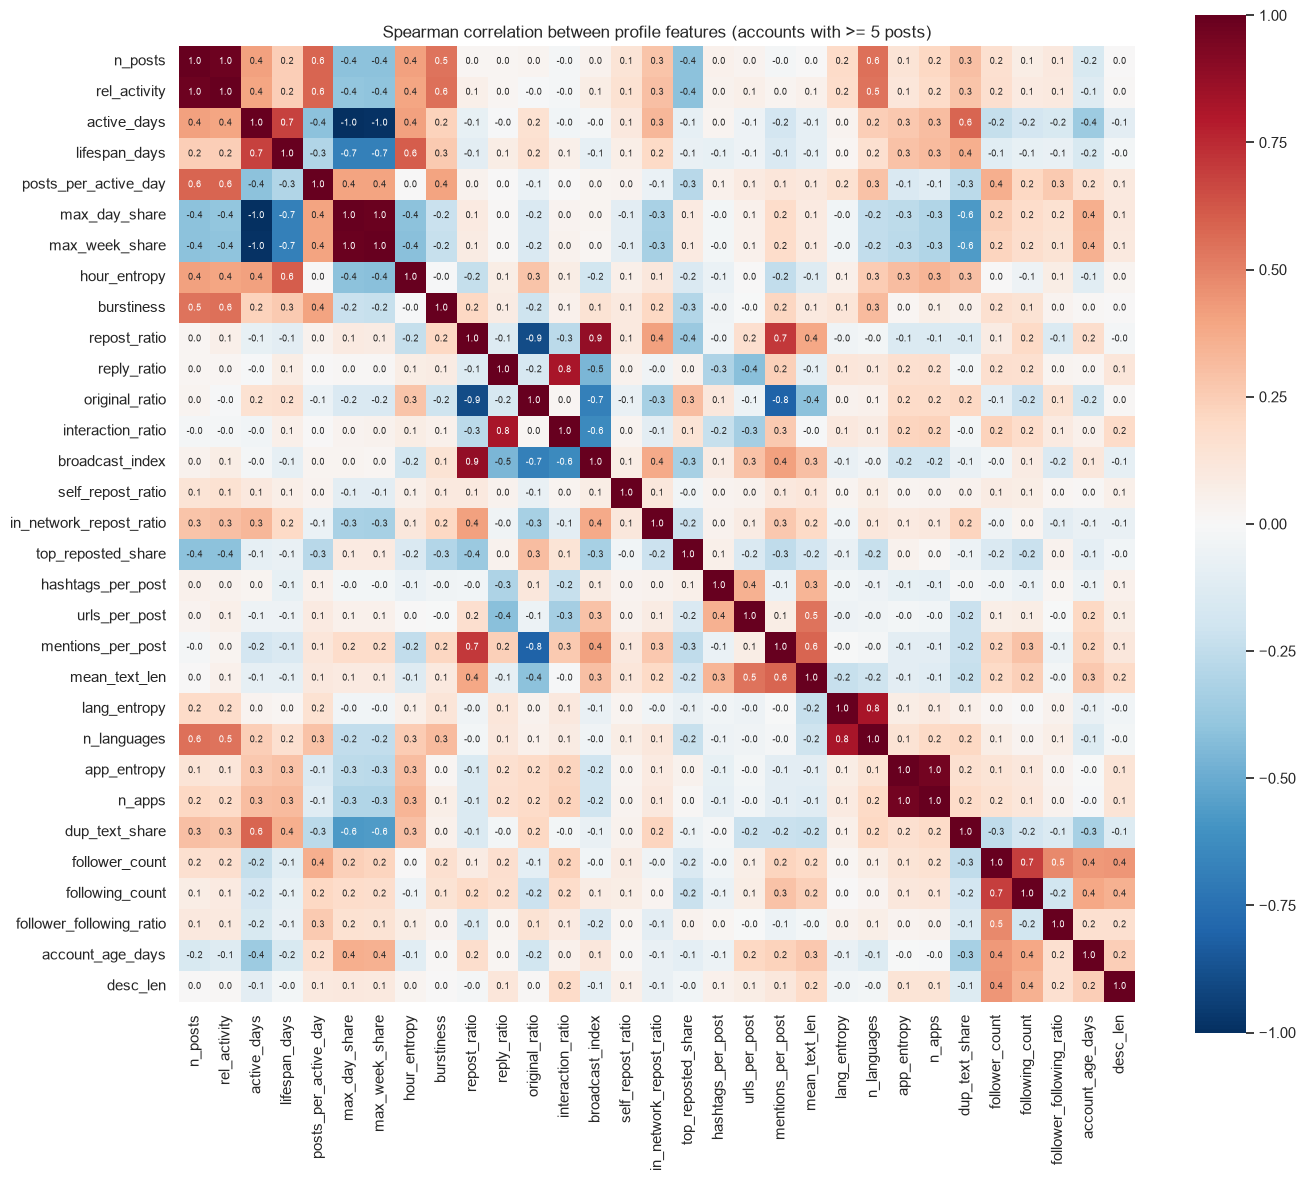

Most correlated pairs of features (|rho| >= 0.7):


,level_0,level_1,rho
0,active_days,max_day_share,-0.9990
1,max_day_share,max_week_share,0.9870
2,active_days,max_week_share,-0.9860
3,n_posts,rel_activity,0.9810
4,app_entropy,n_apps,0.9660
5,repost_ratio,original_ratio,-0.8980
6,repost_ratio,broadcast_index,0.8820
7,reply_ratio,interaction_ratio,0.8230
8,lang_entropy,n_languages,0.8200
9,original_ratio,mentions_per_post,-0.8070


In [28]:
corr_feats = [f for f in ALL_FEATURES if f != 'has_description']
cm = pe[corr_feats].corr(method='spearman')
plt.figure(figsize=(14, 12))
sns.heatmap(cm, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 6.5}, square=True)
plt.title('Spearman correlation between profile features (accounts with >= 5 posts)')
plt.tight_layout()
plt.show()
pairs = (cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1)).stack().rename('rho').reset_index()
         .assign(abs_rho=lambda d: d['rho'].abs()).sort_values('abs_rho', ascending=False))
print('Most correlated pairs of features (|rho| >= 0.7):')
display(pairs[pairs['abs_rho'] >= 0.7].drop(columns='abs_rho').round(3).reset_index(drop=True))

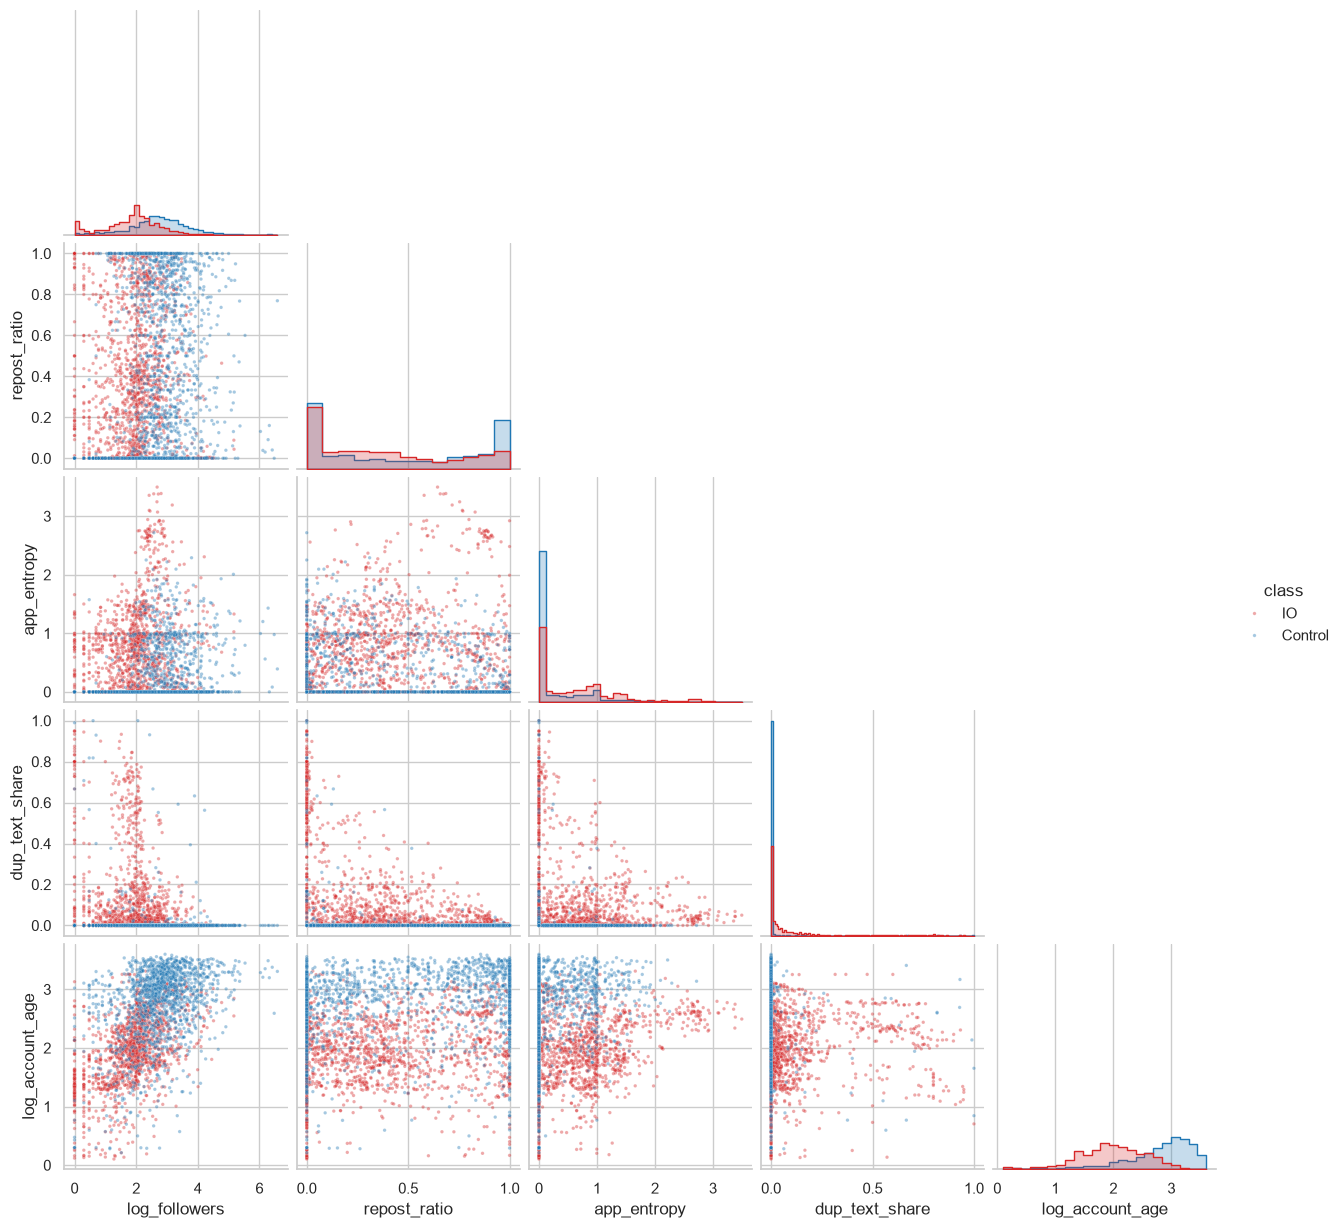

In [29]:
# Scatter matrix of a few key features (random sample of accounts, log scales where needed)
sm_sample = pe.groupby('class', observed=True).sample(1500, random_state=RANDOM_STATE)
sm = pd.DataFrame({'log_followers': np.log10(1 + sm_sample['follower_count']),
                   'repost_ratio': sm_sample['repost_ratio'], 'app_entropy': sm_sample['app_entropy'],
                   'dup_text_share': sm_sample['dup_text_share'],
                   'log_account_age': np.log10(1 + sm_sample['account_age_days']), 'class': sm_sample['class']})
sns.pairplot(sm, hue='class', palette=CLASS_PALETTE, hue_order=CLASS_ORDER, corner=True, diag_kind='hist',
             plot_kws={'s': 6, 'alpha': 0.4}, diag_kws={'common_norm': False, 'element': 'step'})
plt.show()
del sm_sample, sm

**Main findings on the user profiles**

* The **activity/time features** (group A) show the largest IO–control differences (e.g. `active_days`: median 30
  vs 1; `max_day_share`: 0.11 vs 1.0), but – as shown in 1.2.6 – they mostly describe the different observation
  windows of the two classes, not their behaviour.
* Among the behavioural features, IO accounts are clearly:
  * **younger** when they post (median account age 96 vs 849 days; only 4.6% of IO accounts are older than the
    median control account);
  * **less followed** (median 95 vs 622 followers) and following fewer accounts, with a negative
    follower/following balance;
  * engaged in **copy-paste coordination** (`dup_text_share`: 84% of IO accounts above the control median of 0) and
    in **amplification of their own operation** (`in_network_repost_ratio`: 82%);
  * using **more publishing clients per account** (`n_apps`, `app_entropy`) – partly a consequence of their larger
    number of posts – and fewer mentions, URLs and shorter texts/biographies.
* Repost/reply ratios and language entropy differ little *globally*, but a lot – and with opposite signs – inside
  the single operations (conditional box plots), so they remain useful to separate behavioural styles.
* **Redundant features** (|ρ| ≥ 0.7): `active_days` / `max_day_share` / `max_week_share`; `n_posts` /
  `rel_activity`; `app_entropy` / `n_apps`; `lang_entropy` / `n_languages`; `repost_ratio` / `original_ratio` /
  `broadcast_index` / `mentions_per_post`; `reply_ratio` / `interaction_ratio`. Only one representative of each group
  is used for clustering (filter method, [DP] p. 18).

---
# Task 2 – Clustering Analysis

Task 2 only needs the user profiles of Task 1 (`data/user_profiles.parquet`): it can be run on its own after the
setup cells of Section 0.

## 2.1 Selection and preparation of the attributes

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Selection of records and attributes; removing irrelevant / redundant features (filter method based on correlation) | [DP] pp. 2, 14, 17–18 |
| Curse of dimensionality (keep the number of attributes small) | [DP] pp. 15–16 |
| Logarithmic transformation | [DP] pp. 64–66 |
| Outlier treatment: IQR rule, substitution with L or U | [DP] p. 68 |
| z-score normalisation; standardisation needed for Euclidean distance | [DP] p. 47; [SIM] p. 4 |
| Pre-processing for K-means (normalise, treat outliers) | [KM] p. 19 |
| PCA (only for visualisation) and PCA plots | [DP] pp. 52–61; [DU] p. 63 |
| Box plots, Spearman correlation matrix | [DU] pp. 34, 59–60 |

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from pandas.plotting import parallel_coordinates

# Free the large post-level objects of Task 1 (if they exist)
for _name in ['posts', 'p', 'sample_posts', 'pe', 'acc', 'sc_sample']:
    globals().pop(_name, None)
gc.collect()

MIN_POSTS = 5
prof = pd.read_parquet(PROFILES_PQ)
data = prof[prof['n_posts'] >= MIN_POSTS].reset_index(drop=True)
data['class'] = pd.Categorical(data['class'].astype(str), categories=CLASS_ORDER)
print(f'Accounts available for clustering (>= {MIN_POSTS} posts): {len(data):,}  '
      f'{data["class"].value_counts().to_dict()}')

Accounts available for clustering (>= 5 posts): 69,111  {'Control': 59107, 'IO': 10004}


**Selected attributes** (filter method: non-redundant features describing *behaviour* in a way that is comparable
between IO and control accounts):

| Clustering attribute | From profile feature | Transformation | Why |
|---|---|---|---|
| `repost_ratio` | `repost_ratio` | – (proportion) | amplification (represents the redundant group original / broadcast / mentions) |
| `reply_ratio` | `reply_ratio` | – (proportion) | conversation (represents `interaction_ratio`) |
| `in_network_repost_ratio` | same | – (proportion) | coordinated amplification inside the operation |
| `dup_text_share` | same | – (proportion) | copy-paste coordination |
| `log_hashtags_per_post` | `hashtags_per_post` | log, IQR capping | hashtag campaigning (long tail) |
| `urls_per_post` | same | IQR capping | link sharing |
| `log_mean_text_len` | `mean_text_len` | log, IQR capping | content length |
| `lang_entropy` | same | – (bounded) | multilingual behaviour (represents `n_languages`) |
| `app_entropy` | same | – (bounded) | use of several clients (represents `n_apps`) |
| `log_followers` | `follower_count` | log, IQR capping | audience |
| `log_following` | `following_count` | log, IQR capping | social activity |
| `log_account_age` | `account_age_days` | log, IQR capping | age of the account when posting |
| `log_desc_len` | `desc_len` | log, IQR capping | profile completeness |

**Excluded attributes.** The label and the operation (used only for evaluation); all **activity/time** features of
group A, because the observation windows of IO and control accounts are different by design (1.2.6) and the
clusters would reproduce the data collection instead of behaviour; the redundant features of 1.5.3;
`follower_following_ratio` (a linear combination of two selected attributes); `self_repost_ratio` (almost always 0)
and `top_reposted_share` (undefined without reposts).

**Preparation.** (i) $\log_{10}(1+x)$ for long-tailed attributes; (ii) for the unbounded attributes, values outside
$[L, U] = [Q_1 - 1.5\,IQR, Q_3 + 1.5\,IQR]$ are replaced by $L$ or $U$ ([DP] p. 68), so that a few extreme accounts
cannot dominate centroid-based methods. Proportions and entropies are bounded by construction and are not capped:
for them the extreme values (e.g. accounts whose posts are almost all copies) are exactly the behaviour we want to
find ([DU] p. 61); (iii) z-score normalisation, so that every attribute contributes equally to the Euclidean
distance ([SIM] p. 4).

Values replaced by L or U (IQR rule): {'log_hashtags_per_post': 2082, 'urls_per_post': 135, 'log_mean_text_len': 1477, 'log_followers': 2964, 'log_following': 5288, 'log_account_age': 1854, 'log_desc_len': 0}
Clustering matrix: (69111, 13)


,count,mean,std,min,25%,50%,75%,max
repost_ratio,"69,111.0000",0.4430,0.3840,0.0000,0.0340,0.3750,0.8480,1.0000
reply_ratio,"69,111.0000",0.1210,0.1910,0.0000,0.0000,0.0190,0.1720,1.0000
in_network_repost_ratio,"69,111.0000",0.0410,0.1170,0.0000,0.0000,0.0000,0.0160,1.0000
dup_text_share,"69,111.0000",0.0270,0.1180,0.0000,0.0000,0.0000,0.0000,1.0000
log_hashtags_per_post,"69,111.0000",0.2810,0.1850,0.0000,0.1380,0.2510,0.3850,0.7560
urls_per_post,"69,111.0000",0.5900,0.4140,0.0000,0.2220,0.5830,0.9370,2.0080
log_mean_text_len,"69,111.0000",2.1100,0.1700,1.6790,2.0020,2.1230,2.2160,2.5390
lang_entropy,"69,111.0000",0.5060,0.5290,0.0000,0.0000,0.3690,0.7870,4.0990
app_entropy,"69,111.0000",0.3380,0.5280,0.0000,0.0000,0.0000,0.6400,4.1860
log_followers,"69,111.0000",2.6410,0.9770,0.3120,2.0760,2.6830,3.2510,5.0150


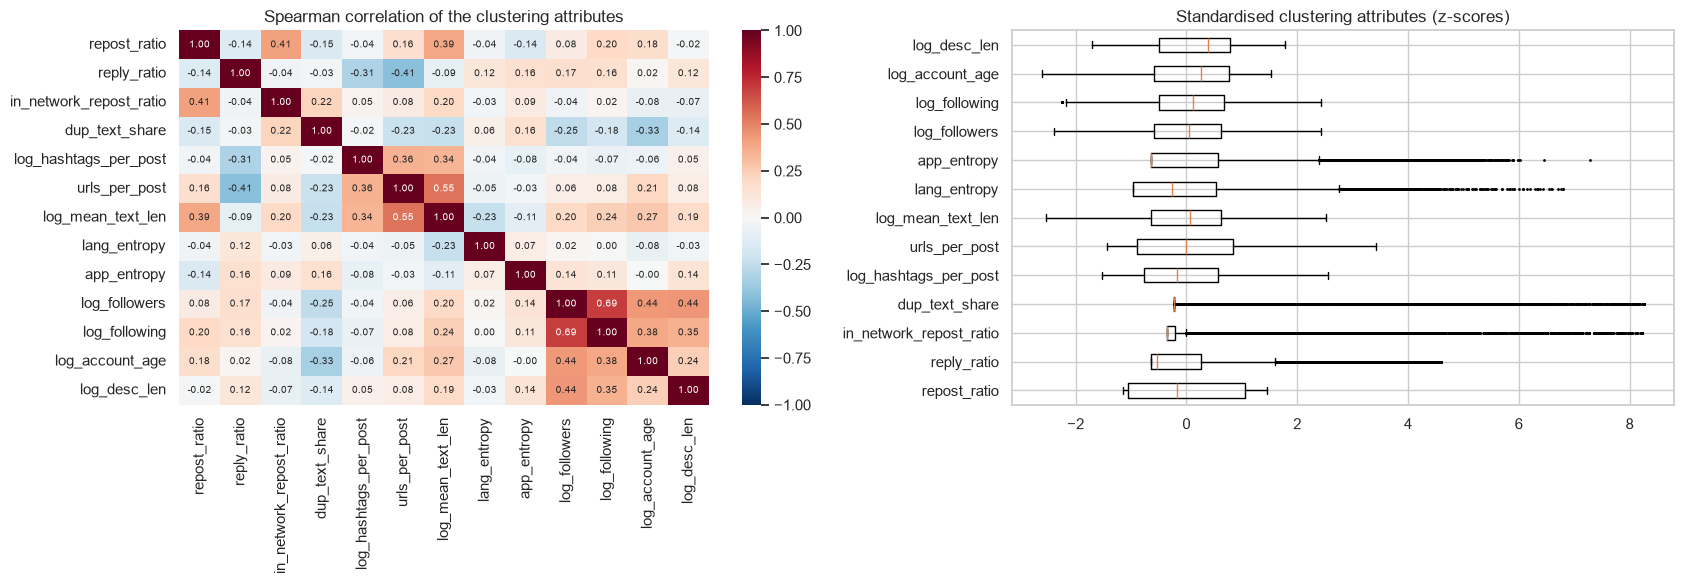

In [31]:
CLUSTER_SPEC = {  # clustering attribute -> (profile column, log-transform?, IQR capping?)
    'repost_ratio': ('repost_ratio', False, False),
    'reply_ratio': ('reply_ratio', False, False),
    'in_network_repost_ratio': ('in_network_repost_ratio', False, False),
    'dup_text_share': ('dup_text_share', False, False),
    'log_hashtags_per_post': ('hashtags_per_post', True, True),
    'urls_per_post': ('urls_per_post', False, True),
    'log_mean_text_len': ('mean_text_len', True, True),
    'lang_entropy': ('lang_entropy', False, False),
    'app_entropy': ('app_entropy', False, False),
    'log_followers': ('follower_count', True, True),
    'log_following': ('following_count', True, True),
    'log_account_age': ('account_age_days', True, True),
    'log_desc_len': ('desc_len', True, True),
}
CLUSTER_FEATURES = list(CLUSTER_SPEC)

feat = pd.DataFrame({name: np.log10(1 + data[col].clip(lower=0)) if use_log else data[col]
                     for name, (col, use_log, _) in CLUSTER_SPEC.items()})
feat = feat.fillna(feat.median())     # mean_text_len is missing only when no post has text
capped = {}
for name, (_, _, cap) in CLUSTER_SPEC.items():
    if cap:
        q1, q3 = feat[name].quantile([0.25, 0.75])
        lo_, hi_ = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        capped[name] = int(((feat[name] < lo_) | (feat[name] > hi_)).sum())
        feat[name] = feat[name].clip(lower=lo_, upper=hi_)
print('Values replaced by L or U (IQR rule):', capped)
scaler = StandardScaler()
X = scaler.fit_transform(feat)
print('Clustering matrix:', X.shape)
display(feat.describe().T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
sns.heatmap(feat.corr(method='spearman'), cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7}, ax=axes[0])
axes[0].set_title('Spearman correlation of the clustering attributes')
axes[1].boxplot(X, orientation='horizontal', tick_labels=CLUSTER_FEATURES, flierprops={'markersize': 1})
axes[1].set_title('Standardised clustering attributes (z-scores)')
plt.tight_layout()
plt.show()

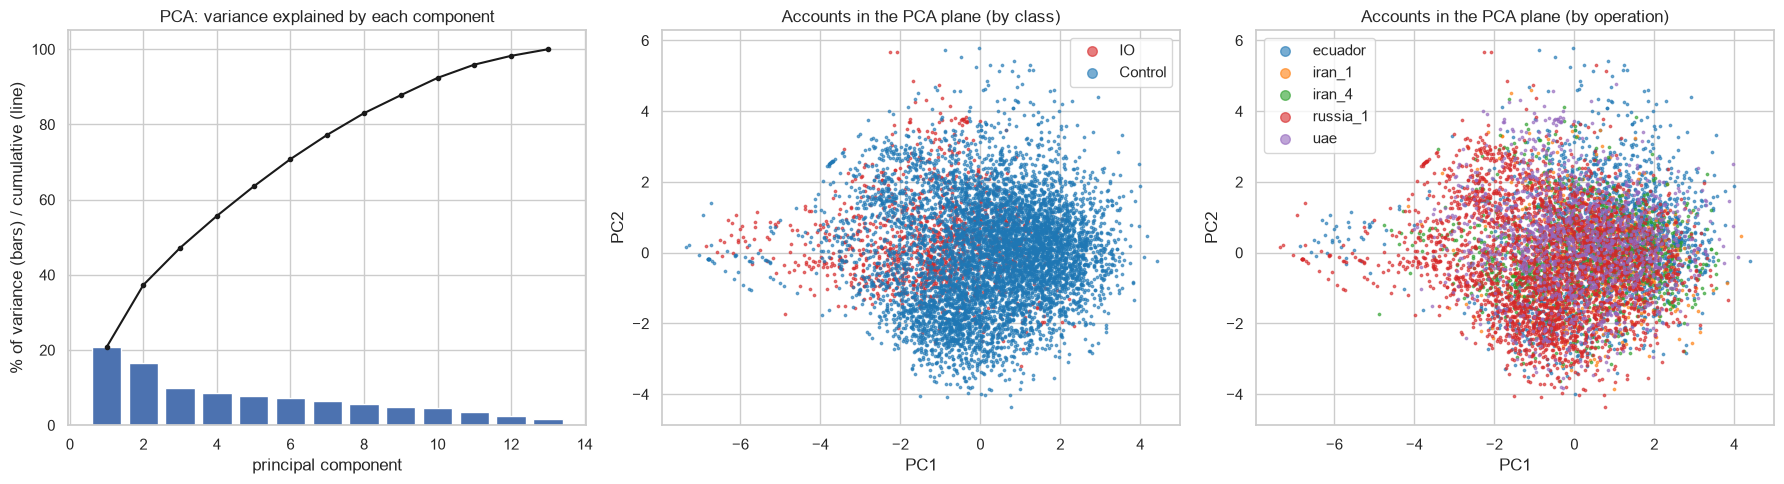

Explained variance (first 5 PCs): [20.8 16.5  9.9  8.5  7.8] | 2 PCs together: 37.3 %


,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,log_hashtags_per_post,urls_per_post,log_mean_text_len,lang_entropy,app_entropy,log_followers,log_following,log_account_age,log_desc_len
PC1,0.2700,-0.0500,0.0500,-0.2800,0.0900,0.2900,0.3900,-0.1100,0.0500,0.4300,0.4100,0.3700,0.2900
PC2,0.2800,-0.3900,0.2900,-0.0100,0.3400,0.4000,0.3100,-0.1000,-0.1600,-0.3200,-0.2800,-0.1600,-0.2600


In [32]:
# PCA: used only to VISUALISE the accounts (every algorithm works in the full 13-dimensional space)
pca = PCA(random_state=RANDOM_STATE).fit(X)
X_pca = pca.transform(X)[:, :2]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(range(1, len(CLUSTER_FEATURES) + 1), pca.explained_variance_ratio_ * 100)
axes[0].plot(range(1, len(CLUSTER_FEATURES) + 1), np.cumsum(pca.explained_variance_ratio_) * 100, 'k.-')
axes[0].set_xlabel('principal component')
axes[0].set_ylabel('% of variance (bars) / cumulative (line)')
axes[0].set_title('PCA: variance explained by each component')
vis_idx = rng.choice(len(X), size=8000, replace=False)          # sample of points used in the scatter plots
for cls in CLASS_ORDER:
    m = (data['class'].to_numpy()[vis_idx] == cls)
    axes[1].scatter(X_pca[vis_idx][m, 0], X_pca[vis_idx][m, 1], s=3, color=CLASS_PALETTE[cls], label=cls, alpha=0.6)
axes[1].set_title('Accounts in the PCA plane (by class)')
axes[1].legend(markerscale=4)
for i, op in enumerate(data['ioCountry'].cat.categories):
    m = (data['ioCountry'].to_numpy()[vis_idx] == op)
    axes[2].scatter(X_pca[vis_idx][m, 0], X_pca[vis_idx][m, 1], s=3, color=plt.cm.tab10(i), label=op, alpha=0.6)
axes[2].set_title('Accounts in the PCA plane (by operation)')
axes[2].legend(markerscale=4)
for ax in axes[1:]:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()
print('Explained variance (first 5 PCs):', (pca.explained_variance_ratio_[:5] * 100).round(1),
      '| 2 PCs together:', round(pca.explained_variance_ratio_[:2].sum() * 100, 1), '%')
display(pd.DataFrame(pca.components_[:2].T, index=CLUSTER_FEATURES, columns=['PC1', 'PC2']).round(2).T)

In [33]:
# Helper functions shared by all the clustering methods
def cluster_names(labels, noise_label=-1):
    return pd.Series(np.asarray(labels)).map(lambda c: 'noise' if c == noise_label else f'C{c}')


def name_order(names):
    return sorted(set(names), key=lambda s: (s == 'noise', int(s[1:]) if s != 'noise' else 0))


def entropy_purity(labels, classes, noise_label=-1):
    """External validity ([VAL] p. 20): total entropy e = sum_j m_j/m * e_j and purity = sum_j m_j/m * max_i p_ij,
    computed on the clustered points (noise excluded)."""
    lab, cl = np.asarray(labels), np.asarray(classes)
    m = lab != noise_label
    ct = pd.crosstab(lab[m], cl[m]).to_numpy().astype(float)
    pij = ct / ct.sum(1, keepdims=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        e_j = -np.nansum(np.where(pij > 0, pij * np.log2(pij), 0), axis=1)
    w = ct.sum(1) / ct.sum()
    return float((w * e_j).sum()), float((w * pij.max(1)).sum())


def cluster_summary(labels, name, noise_label=-1, idx=None):
    """Size, share of IO accounts, operation mix, entropy and purity (w.r.t. the class) of every cluster."""
    d = data if idx is None else data.iloc[idx]
    lab = cluster_names(labels, noise_label).set_axis(d.index)
    is_io = d['class'].eq('IO')
    summ = pd.DataFrame({'size': lab.value_counts(), 'size %': 100 * lab.value_counts(normalize=True),
                         '% IO': 100 * is_io.groupby(lab).mean()})
    summ = summ.join((pd.crosstab(lab, d['ioCountry'], normalize='index') * 100).add_prefix('% '))
    summ['% of all IO accounts'] = 100 * is_io.groupby(lab).sum() / is_io.sum()
    p_io = summ['% IO'] / 100
    with np.errstate(divide='ignore', invalid='ignore'):
        summ['class entropy'] = -(np.where(p_io > 0, p_io * np.log2(p_io), 0)
                                  + np.where(p_io < 1, (1 - p_io) * np.log2(1 - p_io), 0))
    summ['class purity'] = np.maximum(p_io, 1 - p_io)
    e_tot, p_tot = entropy_purity(labels, d['class'], noise_label)
    print(f'{name}: {len(summ) - ("noise" in summ.index)} clusters | total class entropy = {e_tot:.3f} bits, '
          f'purity = {p_tot:.3f} (noise excluded)')
    return summ.loc[name_order(summ.index)].round(3)


def cluster_profiles(labels, name, noise_label=-1, idx=None):
    """Parallel-coordinates plot of the mean z-score of every attribute in every cluster ([DU] p. 45) and table
    of the medians in original units (log attributes back-transformed)."""
    Xs = X if idx is None else X[idx]
    fs = feat if idx is None else feat.iloc[idx]
    lab = cluster_names(labels, noise_label).to_numpy()
    z = pd.DataFrame(Xs, columns=CLUSTER_FEATURES).groupby(lab).mean()
    z = z.loc[name_order(z.index)]
    fig, ax = plt.subplots(figsize=(15, 4.5))
    parallel_coordinates(z.reset_index().rename(columns={'index': 'cluster'}), 'cluster', ax=ax,
                         color=[plt.cm.tab10(i % 10) if c != 'noise' else '#999999' for i, c in enumerate(z.index)],
                         lw=2)
    ax.axhline(0, color='k', lw=0.6)
    ax.set_ylabel('mean z-score')
    ax.set_title(f'{name}: cluster profiles (parallel coordinates of the cluster means)')
    ax.tick_params(axis='x', rotation=30)
    plt.tight_layout()
    plt.show()
    med = fs.reset_index(drop=True).groupby(lab).median()
    for col, (_, use_log, _) in CLUSTER_SPEC.items():
        if use_log:
            med[col] = 10 ** med[col] - 1
    med.columns = [CLUSTER_SPEC[c][0] if CLUSTER_SPEC[c][1] else c for c in CLUSTER_FEATURES]
    return med.loc[name_order(med.index)].round(3)


def internal_scores(Xs, labels, noise_label=-1, sample=None):
    """SSE (cohesion), BSS (separation) and average silhouette ([VAL] pp. 14-19); noise points excluded."""
    lab = np.asarray(labels)
    m = lab != noise_label
    Xm, lm = Xs[m], lab[m]
    if len(set(lm)) < 2:
        return {'SSE': np.nan, 'BSS': np.nan, 'silhouette': np.nan}
    overall = Xm.mean(0)
    sse = bss = 0.0
    for c in np.unique(lm):
        pts = Xm[lm == c]
        cen = pts.mean(0)
        sse += ((pts - cen) ** 2).sum()
        bss += len(pts) * ((cen - overall) ** 2).sum()
    sil = silhouette_score(Xm, lm, sample_size=sample, random_state=RANDOM_STATE)
    return {'SSE': sse, 'BSS': bss, 'silhouette': sil}


def scatter_pca(labels, title, ax, idx=None, noise_label=-1):
    """Clusters in the PCA plane (noise in light grey)."""
    pos = vis_idx if idx is None else idx
    lab = np.asarray(labels) if idx is not None else np.asarray(labels)[vis_idx]
    xy = X_pca[pos]
    for c in sorted(set(lab)):
        m = lab == c
        ax.scatter(xy[m, 0], xy[m, 1], s=3 if c <= 0 else 6, label='noise' if c == noise_label else f'C{c}',
                   color='lightgrey' if c == noise_label else plt.cm.tab10(c % 10), zorder=1 if c <= 0 else 3)
    ax.set_title(title)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(markerscale=4, fontsize=8)

## 2.2 K-means

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Basic K-means algorithm (centroid = mean, Euclidean distance) | [KM] pp. 3–6 |
| Random initial centroids and multiple runs | [KM] pp. 6, 20–29 |
| SSE and choice of the number of clusters (SSE curve) | [KM] pp. 7–8; [VAL] pp. 14–15 |
| Cohesion (SSE) and separation (BSS) | [VAL] pp. 16–18 |
| Silhouette coefficient (points, clusters, clustering) | [VAL] p. 19 |
| Statistical framework: SSE compared with random data | [VAL] pp. 4, 21–22 |
| External validity: entropy and purity w.r.t. the class | [VAL] p. 20 |
| Limitations of K-means (sizes, densities, shapes, outliers) | [KM] pp. 10–16 |
| Parallel coordinates, PCA plot | [DU] pp. 45, 63 |

### 2.2.1 Choice of k

K-means is run for $k = 2, \dots, 12$ with **random initial centroids and 10 runs** for every k (the run with the
lowest SSE is kept). For each k we record the SSE, the BSS and the average silhouette (computed on a random sample
of 10,000 accounts).

,SSE,BSS,silhouette
k,,,
2,"776,237.6090","122,205.3910",0.1390
3,"699,326.5110","199,116.4890",0.1290
4,"641,064.4700","257,378.5300",0.1450
5,"590,910.0730","307,532.9270",0.1550
6,"552,271.0000","346,172.0000",0.1480
7,"521,782.3250","376,660.6750",0.1450
8,"499,399.8750","399,043.1250",0.1490
9,"478,377.1240","420,065.8760",0.1400
10,"460,526.0230","437,916.9770",0.1440


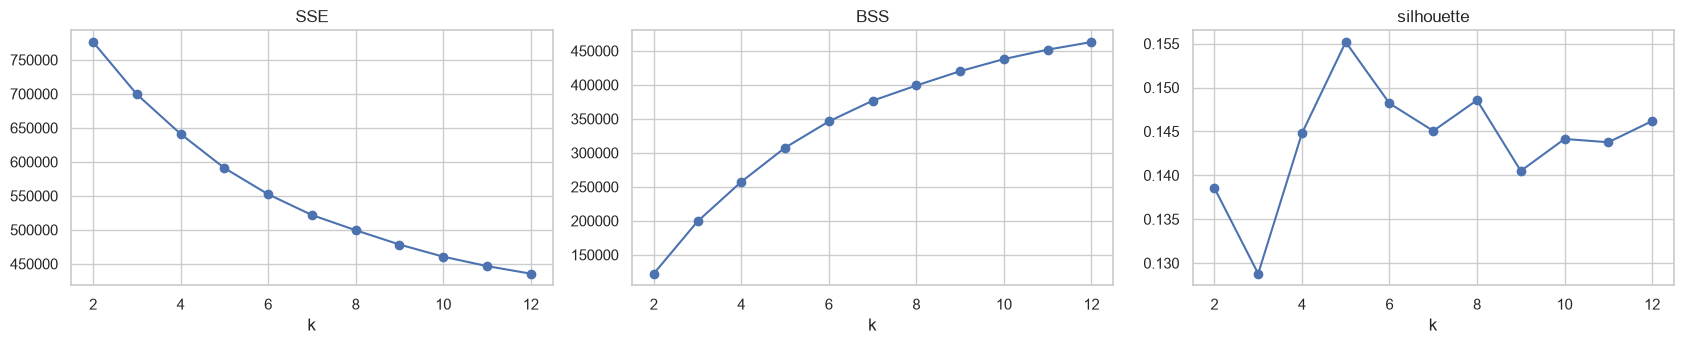

In [34]:
K_RANGE = range(2, 13)
km_rows, km_models = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, init='random', n_init=10, random_state=RANDOM_STATE).fit(X)
    km_models[k] = km
    sc = internal_scores(X, km.labels_, sample=10_000)
    km_rows.append({'k': k, **sc})
km_eval = pd.DataFrame(km_rows).set_index('k')
display(km_eval.round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, col in zip(axes, ['SSE', 'BSS', 'silhouette']):
    ax.plot(km_eval.index, km_eval[col], marker='o')
    ax.set_title(col)
    ax.set_xlabel('k')
plt.tight_layout()
plt.show()

**Choice of k.** The SSE decreases smoothly, without a sharp elbow (BSS grows by the same amount, since
SSE + BSS is constant, [VAL] p. 18): its curvature is strongest between k = 4 and k = 6, typical of behavioural data
without well-separated groups. The silhouette is low for every k (0.13–0.16: the clusters overlap) but reaches its
**maximum at k = 5** (0.155). Larger values of k reduce the SSE only marginally while fragmenting the groups. We
therefore select **k = 5**.

### 2.2.2 Is the structure better than random? (statistical framework for the SSE)

Following [VAL] pp. 21–22, we compare the SSE of the chosen clustering with the SSE obtained by K-means (same k) on
**random data** with the same marginal distributions: every attribute is shuffled independently, which keeps each
distribution but destroys the joint structure.

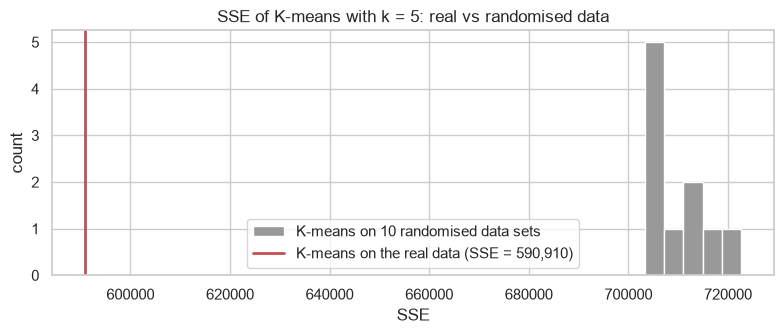

Random data: SSE between 703,264 and 722,638; real data: 590,910 (16.6% lower)


In [35]:
K_BEST = 5
kmeans = km_models[K_BEST]
labels_km = kmeans.labels_
rand_sse = []
for r in range(10):
    perm_rng = np.random.default_rng(100 + r)            # one generator: a different permutation for every column
    Xr = np.column_stack([perm_rng.permutation(X[:, j]) for j in range(X.shape[1])])
    rand_sse.append(KMeans(n_clusters=K_BEST, init='random', n_init=5, random_state=r).fit(Xr).inertia_)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(rand_sse, bins=sturges_bins(len(rand_sse)), color='#999999', label='K-means on 10 randomised data sets')
ax.axvline(kmeans.inertia_, color='r', lw=2, label=f'K-means on the real data (SSE = {kmeans.inertia_:,.0f})')
ax.set_xlabel('SSE')
ax.set_ylabel('count')
ax.legend()
ax.set_title(f'SSE of K-means with k = {K_BEST}: real vs randomised data')
plt.tight_layout()
plt.show()
print(f'Random data: SSE between {min(rand_sse):,.0f} and {max(rand_sse):,.0f}; real data: {kmeans.inertia_:,.0f} '
      f'({100 * (1 - kmeans.inertia_ / np.mean(rand_sse)):.1f}% lower)')
del Xr

### 2.2.3 Final K-means model: centroids and interpretation

K-means centroids in original units (log attributes back-transformed):


,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.8510,0.0240,0.4660,0.0220,0.9640,0.7860,152.0020,0.3060,0.7350,132.8330,186.8760,271.1430,8.6580
C1,0.6400,0.0600,0.0250,0.0020,1.0750,0.8140,164.7030,0.4320,0.2900,"1,548.5500","1,153.6310","1,045.9850",48.3110
C2,0.3270,0.0460,0.0210,0.0160,1.3370,0.6720,121.2510,0.5400,0.2110,45.1820,40.4230,127.6560,6.8070
C3,0.2370,0.2800,0.0090,0.0090,0.4770,0.2420,96.2080,0.6070,0.4500,682.9000,480.1310,493.1000,35.2100
C4,0.0480,0.0600,0.0110,0.6600,0.7580,0.1370,83.4300,0.5500,0.1400,38.8340,71.9140,129.4440,4.4240


K-means (k=5): 5 clusters | total class entropy = 0.490 bits, purity = 0.864 (noise excluded)


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts,class entropy,class purity
C0,3479,5.0340,49.2380,40.2700,2.9610,2.9890,30.9570,22.8230,17.1230,1.0000,0.5080
C1,27320,39.5310,3.1630,33.2030,9.0810,13.9280,25.9480,17.8400,8.6370,0.2020,0.9680
C2,15590,22.5580,24.4960,12.4820,5.8500,12.2580,48.2870,21.1230,38.1750,0.8030,0.7550
C3,20783,30.0720,11.2400,18.5730,5.2350,11.3600,52.7310,12.1010,23.3510,0.5070,0.8880
C4,1939,2.8060,65.6010,18.3080,0.8770,3.2490,74.6260,2.9400,12.7150,0.9290,0.6560


Medians of the attributes in every cluster (original units):


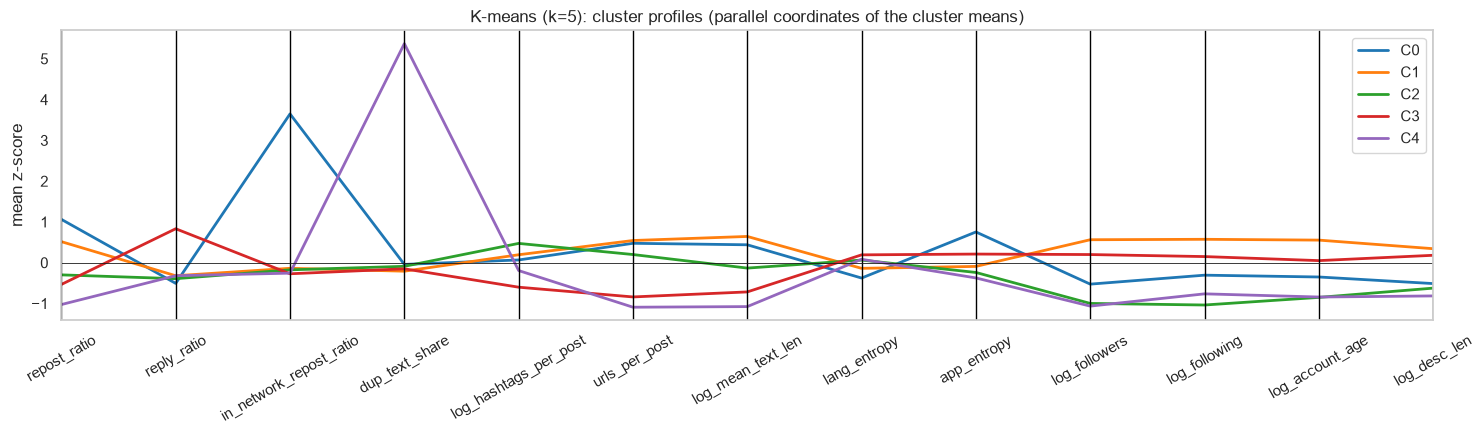

,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.9130,0.0000,0.4040,0.0000,0.9660,0.8240,138.9600,0.2410,0.1020,147.0000,205.0000,336.4020,15.0000
C1,0.7880,0.0000,0.0000,0.0000,0.9230,0.8120,159.4950,0.2860,0.0000,"1,307.0000","1,208.0000","1,337.5500",92.0000
C2,0.1110,0.0000,0.0000,0.0000,1.1740,0.7220,125.3640,0.4050,0.0000,54.0000,53.0000,128.8520,10.0000
C3,0.1820,0.2310,0.0000,0.0000,0.3800,0.1850,96.7710,0.5030,0.1870,613.0000,510.0000,648.7580,58.0000
C4,0.0000,0.0000,0.0000,0.6360,0.7010,0.0910,78.3960,0.2670,0.0000,54.0000,113.0000,195.5210,0.0000


In [36]:
cent = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=CLUSTER_FEATURES,
                    index=[f'C{i}' for i in range(K_BEST)])
for col, (_, use_log, _) in CLUSTER_SPEC.items():
    if use_log:
        cent[col] = 10 ** cent[col] - 1
cent.columns = [CLUSTER_SPEC[c][0] if CLUSTER_SPEC[c][1] else c for c in CLUSTER_FEATURES]
print('K-means centroids in original units (log attributes back-transformed):')
display(cent.round(3))
km_name = f'K-means (k={K_BEST})'
display(cluster_summary(labels_km, km_name))
print('Medians of the attributes in every cluster (original units):')
display(cluster_profiles(labels_km, km_name))

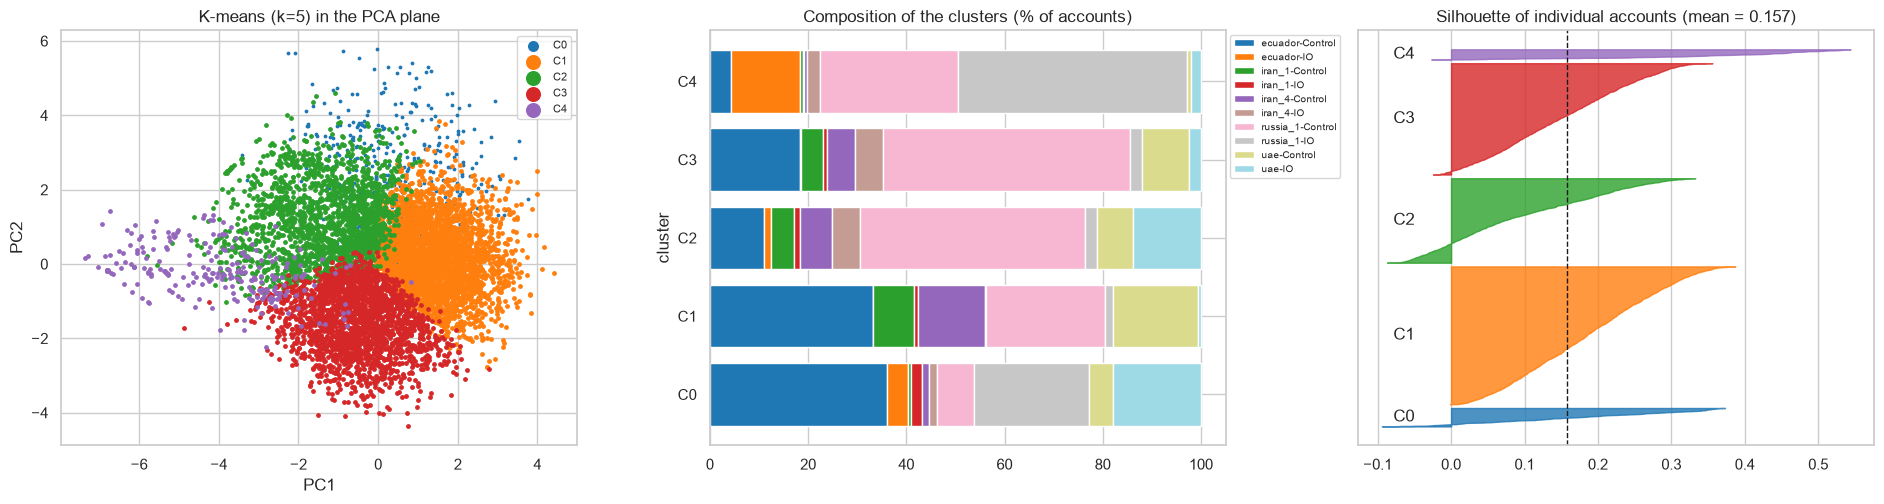

Average silhouette per cluster: {'C0': 0.17, 'C1': 0.186, 'C2': 0.093, 'C3': 0.15, 'C4': 0.359}


In [37]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
scatter_pca(labels_km, f'{km_name} in the PCA plane', axes[0])
op_class = (data['ioCountry'].astype(str) + '-' + data['class'].astype(str)).rename('operation-class')
comp = pd.crosstab(cluster_names(labels_km).set_axis(data.index).rename('cluster'), op_class, normalize='index') * 100
comp.plot(kind='barh', stacked=True, ax=axes[1], colormap='tab20', width=0.8, legend=False)
axes[1].set_title('Composition of the clusters (% of accounts)')
axes[1].legend(bbox_to_anchor=(1.0, 1.0), fontsize=7)
sil_idx = rng.choice(len(X), size=5000, replace=False)
sil_vals = silhouette_samples(X[sil_idx], labels_km[sil_idx])
y0 = 0
for c in range(K_BEST):
    v = np.sort(sil_vals[labels_km[sil_idx] == c])
    axes[2].fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=plt.cm.tab10(c), alpha=0.8)
    axes[2].text(-0.05, y0 + len(v) / 2, f'C{c}', ha='right', va='center')
    y0 += len(v) + 50
axes[2].axvline(sil_vals.mean(), color='k', ls='--', lw=1)
axes[2].set_title(f'Silhouette of individual accounts (mean = {sil_vals.mean():.3f})')
axes[2].set_yticks([])
plt.tight_layout()
plt.show()
print('Average silhouette per cluster:',
      pd.Series(sil_vals).groupby(labels_km[sil_idx]).mean().rename(lambda c: f'C{c}').round(3).to_dict())

In [38]:
# Activity/time features (NOT used for clustering) inside every cluster, for interpretation only
display(data.groupby(cluster_names(labels_km).to_numpy())[
    ['n_posts', 'active_days', 'max_day_share', 'hour_entropy', 'mentions_per_post', 'n_languages', 'n_apps']]
    .median().round(2))

,n_posts,active_days,max_day_share,hour_entropy,mentions_per_post,n_languages,n_apps
C0,81.0000,3.0000,0.5000,0.6100,1.0900,3.0000,2.0000
C1,40.0000,1.0000,1.0000,0.4800,1.1600,2.0000,1.0000
C2,38.0000,1.0000,1.0000,0.5500,0.3700,2.0000,1.0000
C3,31.0000,1.0000,1.0000,0.5300,0.7300,3.0000,2.0000
C4,80.0000,5.0000,0.4400,0.5900,0.0600,3.0000,1.0000


**Interpretation of the K-means clusters** (medians in original units in the table above):

| Cluster | Size | % IO | Profile | Label |
|---|---|---|---|---|
| C1 | 40% | 3% | oldest accounts (≈3.7 years), ≈1.3k followers / 1.2k following, complete biographies, repost-oriented (≈80% reposts) with hashtags and links, longest texts | **established organic users** |
| C3 | 30% | 11% | ≈23% of posts are replies, short texts, few links/hashtags, highest language entropy; mostly Russian controls | **conversational users** |
| C2 | 23% | 24% | ≈54 followers and following, ≈4 months old, very short or empty biographies, many hashtags, few reposts; holds **38% of all IO accounts** | **low-profile young accounts** |
| C0 | 5% | 49% | ≈90% reposts, ≈40% of the posts are reposts of *other accounts of the same operation*, more publishing clients, young accounts with few followers; Ecuador, Russia and UAE | **network amplifiers** (coordinated retweeting) |
| C4 | 3% | 66% | no reposts, **≈64% of the posts are verbatim copies** of texts published by other accounts of the operation, short texts, no biography; 75% Russia | **copy-paste broadcasters** |

* The structure is **not random**: the SSE of the real data is ≈16–18% lower than on randomised data with the same
  marginal distributions ([VAL] pp. 21–22), but the low silhouettes show that, apart from C4 (silhouette ≈ 0.36),
  the clusters are partitions of a continuum rather than well-separated groups ([KM] pp. 10–16: K-means always
  returns k convex groups).
* The two smallest clusters (C0, C4) are **IO-dominated** and correspond to two known coordination strategies:
  retweet networks and copy-pasta. IO accounts are nevertheless spread over all the clusters (38% look like
  low-profile young accounts, 23% like conversational users): IO behaviour is a **mix of strategies**, several of
  which resemble those of genuine users. Overall the class entropy drops only from 0.60 to 0.49 bits and the purity
  rises only from 0.855 (all accounts in one cluster) to 0.864.
* The activity/time features (not used for clustering) confirm the picture: C0 and C4 accounts have more active days
  and lower daily concentration, i.e. the full timelines typical of IO accounts.

## 2.3 Density-based clustering: DBSCAN

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| DBSCAN: density, Eps, MinPts (point itself counted), core / border / noise points | [DBSCAN] pp. 2–8 |
| When DBSCAN works / does not work (varying densities, high dimensionality) | [DBSCAN] pp. 9–10 |
| Choice of Eps and MinPts with the sorted k-th nearest-neighbour distance plot | [DBSCAN] p. 11 |
| Stratified sampling (representative sample) | [DP] pp. 9–13 |
| Density-based clusters | [CL-INTRO] p. 14 |
| Internal (SSE, silhouette) and external (entropy, purity) validity | [VAL] pp. 14–20 |

DBSCAN computes the Eps-neighbourhood of every point; to keep memory and time under control it is run on a
**stratified random sample of 20,000 accounts** (same proportions of operations and classes as the whole set,
[DP] p. 12). We proceed in two steps:

1. **k-distance plots** ([DBSCAN] p. 11): for MinPts = k, the distance of every point to its k-th nearest
   neighbour (the point itself included, as in the definition of a core point) is sorted; the sharp increase
   ("knee") separates points inside dense regions from noise;
2. a **grid search** on (Eps, MinPts) recording number of clusters, noise share, size of the largest cluster and
   silhouette (noise excluded).

DBSCAN sample: (19998, 13) {'Control': 17104, 'IO': 2894}


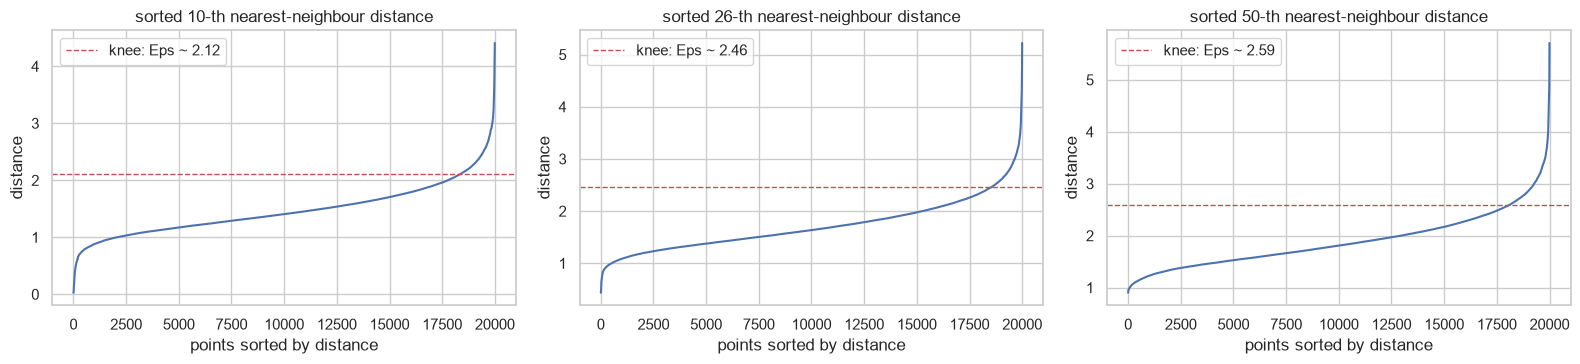

Knee of the k-distance curves: {10: 2.116, 26: 2.459, 50: 2.594}


In [39]:
db_idx = np.sort(data.groupby(['ioCountry', 'class'], observed=True)
                 .sample(frac=20_000 / len(data), random_state=RANDOM_STATE).index.to_numpy())
Xd = X[db_idx]
print('DBSCAN sample:', Xd.shape, data.loc[db_idx, 'class'].value_counts().to_dict())


def knee_point(y):
    """Index of the point of a sorted curve with the largest distance from the chord joining its extremes."""
    x = np.linspace(0, 1, len(y))
    yn = (y - y.min()) / (y.max() - y.min())
    return int(np.argmax(np.abs(yn - x)))


MIN_PTS_GRID = [10, 26, 50]            # 26 = 2 x number of attributes (a common rule of thumb)
fig, axes = plt.subplots(1, len(MIN_PTS_GRID), figsize=(16, 3.8))
knees = {}
for ax, mp in zip(axes, MIN_PTS_GRID):
    dist, _ = NearestNeighbors(n_neighbors=mp).fit(Xd).kneighbors(Xd)
    kd = np.sort(dist[:, -1])
    kn = knee_point(kd)
    knees[mp] = kd[kn]
    ax.plot(kd)
    ax.axhline(kd[kn], color='r', ls='--', lw=1, label=f'knee: Eps ~ {kd[kn]:.2f}')
    ax.set_title(f'sorted {mp}-th nearest-neighbour distance')
    ax.set_xlabel('points sorted by distance')
    ax.set_ylabel('distance')
    ax.legend()
plt.tight_layout()
plt.show()
print('Knee of the k-distance curves:', {k: round(float(v), 3) for k, v in knees.items()})

,MinPts,Eps,clusters,noise %,largest cluster %,silhouette (no noise),% IO in noise
0,10,0.8000,31,93.9140,2.1350,0.3260,13.6310
1,10,1.0000,55,78.3080,9.3210,0.1260,13.5310
2,10,1.2000,36,52.2350,43.3940,-0.2070,14.2830
3,10,1.4000,26,29.6880,66.6970,-0.1020,16.1360
4,10,1.6000,12,15.2070,83.7580,0.0420,18.7770
5,10,1.8000,4,7.6410,91.8240,0.3850,20.8120
6,10,2.0000,5,3.6350,95.7000,0.2190,19.6700
7,10,2.2000,3,1.8150,97.8300,0.3980,18.7330
8,10,2.5000,2,0.6550,99.2950,0.2190,12.2140
9,26,0.8000,5,98.7850,0.4900,0.7150,14.4520


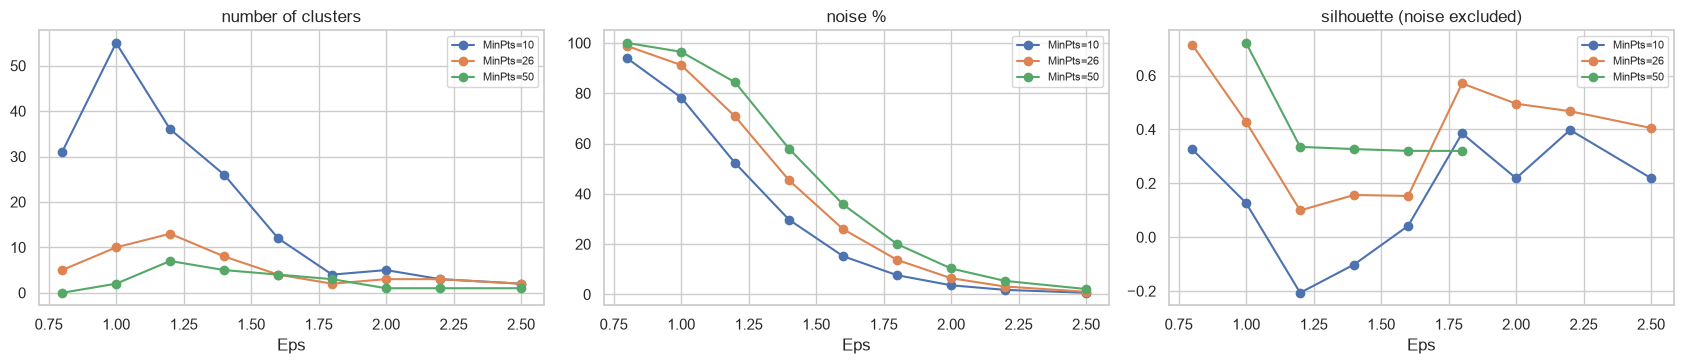

In [40]:
EPS_GRID = [0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5]
db_rows = []
for mp in MIN_PTS_GRID:
    for eps in EPS_GRID:
        lab = DBSCAN(eps=eps, min_samples=mp).fit_predict(Xd)
        sizes = pd.Series(lab[lab >= 0]).value_counts()
        sc = internal_scores(Xd, lab, sample=5000)
        db_rows.append({'MinPts': mp, 'Eps': eps, 'clusters': len(sizes), 'noise %': 100 * (lab == -1).mean(),
                        'largest cluster %': 100 * sizes.max() / len(lab) if len(sizes) else 0,
                        'silhouette (no noise)': sc['silhouette'],
                        '% IO in noise': 100 * data.loc[db_idx[lab == -1], 'class'].eq('IO').mean()
                        if (lab == -1).any() else np.nan})
db_grid = pd.DataFrame(db_rows)
display(db_grid.round(3))
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for mp in MIN_PTS_GRID:
    d = db_grid[db_grid['MinPts'] == mp]
    for ax, col in zip(axes, ['clusters', 'noise %', 'silhouette (no noise)']):
        ax.plot(d['Eps'], d[col], marker='o', label=f'MinPts={mp}')
for ax, t in zip(axes, ['number of clusters', 'noise %', 'silhouette (noise excluded)']):
    ax.set_title(t)
    ax.set_xlabel('Eps')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Choice of the parameters.**

* The knees of the k-distance curves (Eps ≈ 2.1–2.6) are where almost every account becomes a core point: with these
  values DBSCAN returns one giant cluster (> 90% of the accounts) and at most a couple of tiny ones – the accounts
  form one continuous dense region, as already suggested by K-means.
* Small values of Eps (≤ 1.2) fragment the data into many micro-clusters and most accounts become noise.
* In between, **MinPts = 50, Eps = 1.6** gives a stable and interpretable solution: one main cluster plus a few small
  but **very dense** groups that are separated from it (with Eps = 1.8 one of them already merges into the main
  cluster). A large MinPts (≈4 × the number of attributes) guarantees that these groups are really dense regions and
  not chance agglomerations; the price is a large share of noise. As warned in [DBSCAN] p. 10, regions of very
  different density and 13 dimensions make a single Eps a compromise.

Point types ([DBSCAN] p. 2): {'noise': 7155, 'border': 6482, 'core': 6361}
DBSCAN (Eps=1.6, MinPts=50): 4 clusters | total class entropy = 0.417 bits, purity = 0.915 (noise excluded)


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts,class entropy,class purity
C0,12432,62.1660,8.7440,24.9840,7.0700,13.5940,36.9050,17.4470,37.5600,0.4280,0.9130
C1,134,0.6700,100.0000,0.0000,0.0000,0.0000,100.0000,0.0000,4.6300,-0.0000,1.0000
C2,206,1.0300,98.0580,0.0000,0.0000,2.4270,97.5730,0.0000,6.9800,0.1380,0.9810
C3,71,0.3550,98.5920,1.4080,0.0000,0.0000,1.4080,97.1830,2.4190,0.1070,0.9860
noise,7155,35.7790,19.5810,23.8570,6.3170,9.6440,44.8220,15.3600,48.4110,0.7130,0.8040


Medians of the attributes in every cluster (original units):


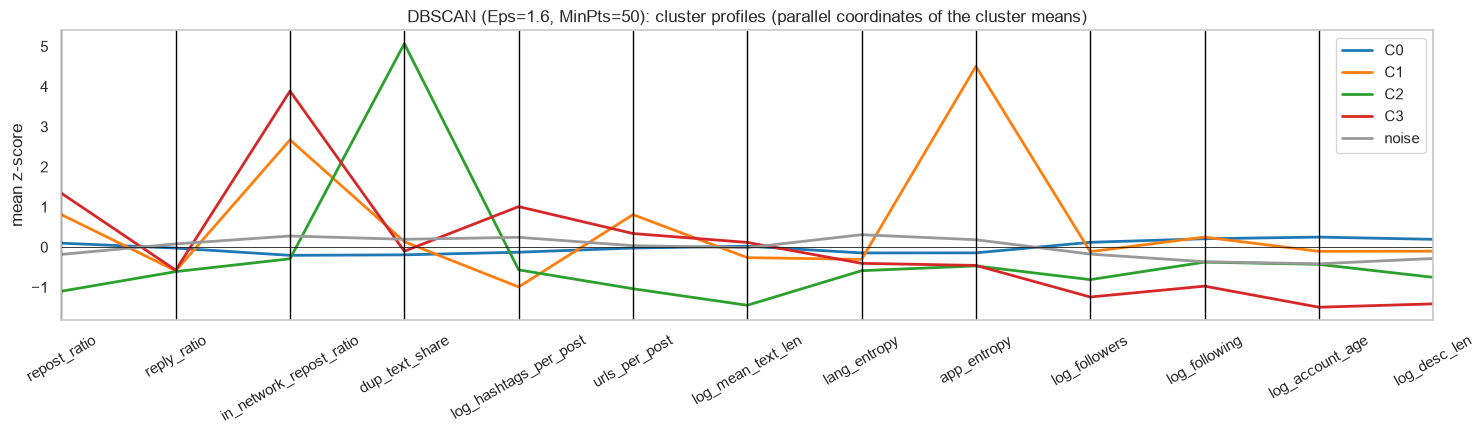

,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.4550,0.0320,0.0000,0.0000,0.6870,0.5880,133.0000,0.3370,0.0000,614.0000,612.0000,904.9970,66.0000
C1,0.8080,0.0070,0.3580,0.0370,0.2340,0.9470,119.2260,0.3040,2.7250,293.9980,458.9300,401.9540,27.0000
C2,0.0000,0.0000,0.0000,0.6240,0.5110,0.1500,73.9420,0.1780,0.0000,73.4980,153.0000,221.2690,5.4810
C3,0.9760,0.0060,0.4750,0.0060,1.8400,0.7220,134.2900,0.2820,0.0000,29.0000,50.0000,45.5500,0.0000
noise,0.2310,0.0030,0.0000,0.0000,1.0000,0.5590,129.5560,0.5270,0.0000,276.0000,200.0000,363.5960,30.0000


Contingency table DBSCAN clusters x K-means clusters (DBSCAN sample):


K-means,C0,C1,C2,C3,C4
DBSCAN,,,,,
C0,42,6188,2054,4148,0
C1,133,0,0,1,0
C2,0,0,0,0,206
C3,71,0,0,0,0
noise,750,1650,2462,1935,358


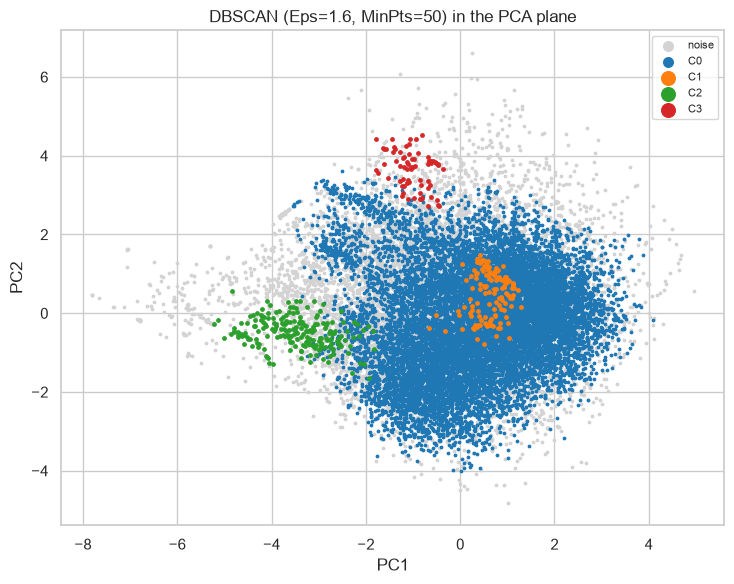

In [41]:
DB_EPS, DB_MIN_PTS = 1.6, 50
dbscan = DBSCAN(eps=DB_EPS, min_samples=DB_MIN_PTS).fit(Xd)
labels_db_sample = dbscan.labels_
is_core = np.zeros(len(Xd), dtype=bool)
is_core[dbscan.core_sample_indices_] = True
point_type = np.where(is_core, 'core', np.where(labels_db_sample == -1, 'noise', 'border'))
print('Point types ([DBSCAN] p. 2):', pd.Series(point_type).value_counts().to_dict())
labels_db = np.full(len(data), -2)          # -2 = account not in the DBSCAN sample
labels_db[db_idx] = labels_db_sample
db_name = f'DBSCAN (Eps={DB_EPS}, MinPts={DB_MIN_PTS})'
display(cluster_summary(labels_db_sample, db_name, idx=db_idx))
print('Medians of the attributes in every cluster (original units):')
display(cluster_profiles(labels_db_sample, db_name, idx=db_idx))
print('Contingency table DBSCAN clusters x K-means clusters (DBSCAN sample):')
display(pd.crosstab(cluster_names(labels_db_sample).rename('DBSCAN'),
                    cluster_names(labels_km[db_idx]).rename('K-means')))
fig, ax = plt.subplots(figsize=(7.5, 6))
scatter_pca(labels_db_sample, f'{db_name} in the PCA plane', ax, idx=db_idx)
plt.tight_layout()
plt.show()

**Interpretation of the DBSCAN clusters** (20,000-account sample, 14.5% IO; ≈6.4k core, ≈6.5k border and ≈7.2k
noise points):

| Cluster | Size | % IO | Profile |
|---|---|---|---|
| C0 | 62% | 9% | the dense **core of ordinary behaviour**: it absorbs K-means clusters C1, C2 and C3 (contingency table) |
| C1 | 134 | **100%** (Russia) | reposting accounts (≈80% reposts, ≈36% in-network) that use **many different clients** (app entropy ≈ 2.7 bits): a retweet network operated through many applications – a dense core inside K-means C0 |
| C2 | 206 | **98%** (Russia) | **copy-paste broadcasters**: ≈62% duplicated texts, no reposts, short texts – the dense core of K-means C4 (all 206 accounts are in K-means C4) |
| C3 | 71 | **99%** (UAE) | a **retweet farm**: accounts ≈1.5 months old, ≈30 followers, no biography, ≈98% reposts, ≈48% in-network, ≈1.8 hashtags per post |
| noise | 36% | 20% | accounts in sparse regions: more multilingual, younger and following fewer accounts than the core |

* **Every dense region outside the core is almost purely IO**: coordinated accounts are behaviourally
  *near-identical* (they are run with the same tools and scripts), which is exactly what a density-based method
  detects. DBSCAN therefore gives the purest IO clusters of all methods (class purity of the clustered points 0.915).
* The price is coverage: the three pure clusters contain only ≈14% of the IO accounts of the sample, while ≈48% of
  the IO accounts are **noise**. Noise is not "garbage" here: IO accounts are over-represented in it (20% vs 14.5%),
  i.e. many IO accounts have unusual, individual profiles that belong to no dense group.

## 2.4 Hierarchical (agglomerative) clustering

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Agglomerative algorithm on the proximity matrix | [HIER] pp. 2–9 |
| Inter-cluster proximity: MIN (single link), MAX (complete link), group average, Ward's method | [HIER] pp. 10–27 |
| Dendrogram and cutting the dendrogram to obtain k clusters | [HIER] pp. 2–3, 16, 20, 24 |
| O(N²) space / O(N³) time → sampling | [HIER] p. 30; [DP] pp. 9–12 |
| Limitations (irreversible merges, noise, sizes, shapes) | [HIER] p. 31 |
| Validity via correlation between proximity matrix and ideal (incidence) similarity matrix | [VAL] pp. 7–8 |
| Silhouette, entropy and purity | [VAL] pp. 19–20 |

Agglomerative clustering needs the full proximity matrix, so it is run on a random sample of **6,000 accounts**
drawn from the DBSCAN sample (the same accounts are used for the final comparison in 2.5). Distances are Euclidean on
the standardised attributes. For every linkage we cut the dendrogram into $k = 2..10$ clusters and record the
silhouette, the size of the largest cluster and the **correlation between the proximity (distance) matrix and the
ideal similarity matrix** ([VAL] p. 7: entry 1 if two points are in the same cluster, 0 otherwise). With distances,
a good clustering gives a **strongly negative** correlation (points of the same cluster are close).

silhouette                        largest cluster %                          corr(proximity, incidence)                         
linkage    average complete single   ward           average complete  single    ward                    average complete  single    ward
k                                                                                                                                       
2           0.4330   0.3430 0.3780 0.1010           99.1670  96.5000 99.9830 66.4670                    -0.3120  -0.4170 -0.0360 -0.1740
3           0.3210   0.3290 0.2930 0.0750           95.5670  95.1000 99.9670 34.4000                    -0.4800  -0.5250 -0.0440 -0.2000
4           0.2890   0.2020 0.1970 0.0850           95.2670  95.1000 99.9500 34.4000                    -0.4930  -0.5270 -0.0460 -0.2530
5           0.2400   0.0430 0.1830 0.0990           95.2330  84.5670 99.9170 32.0670                    -0.4940  -0.3390 -0.0620 -0.3140
6           0.2220   0.0480 0.1770 0.1010           95.2330  72.9330 99.9000 32.0670                    -0.4940  -0.3490 -0.0670 -0.3340
7           0.1990   0.0420 0.1660 0.0980           95.2330  72.9330 99.9000 32.0670                    -0.4940  -0.3490 -0.0670 -0.3360
8           0.1840   0.0610 0.1660 0.0970           95.2330  38.2330 99.8830 32.0670                    -0.4940  -0.3050 -0.0880 -0.3410
9           0.1500   0.0150 0.1660 0.0870           94.6000  38.2330 99.8670 23.8670                    -0.4990  -0.3060 -0.1010 -0.3160
10          0.1180   0.0120 0.1640 0.0750           94.2170  38.2330 99.8500 20.8500                    -0.5000  -0.3080 -0.1080 -0.2870

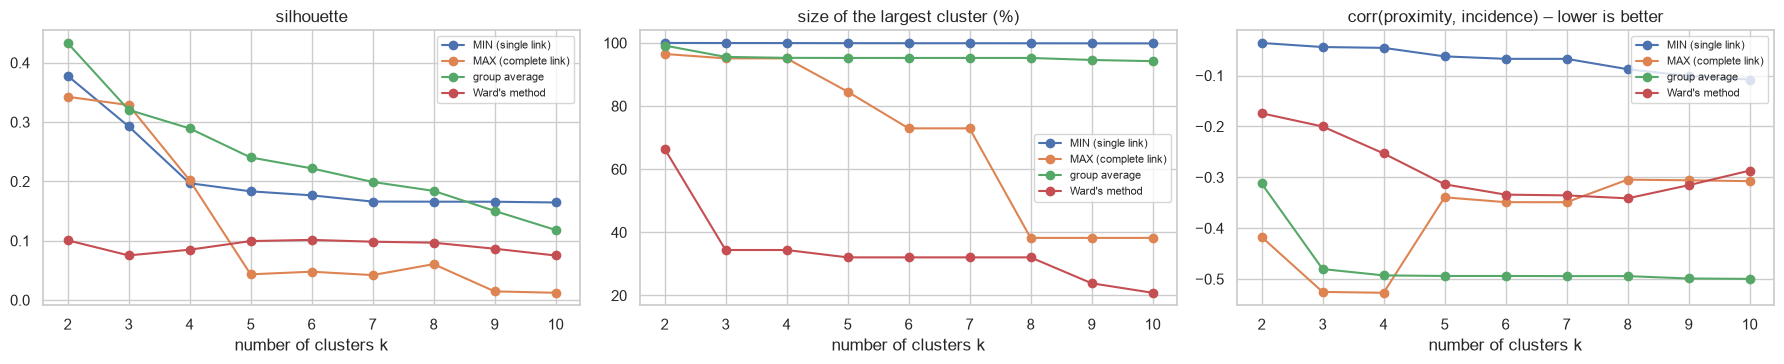

In [42]:
H_N = 6000
h_idx = np.sort(np.random.default_rng(RANDOM_STATE).choice(db_idx, size=H_N, replace=False))
Xh = X[h_idx]
Dh = pdist(Xh)                       # condensed Euclidean proximity matrix (N(N-1)/2 entries)


def incidence_correlation(labels, D=Dh, noise_label=None):
    """Pearson correlation between the proximity (distance) matrix and the ideal similarity (incidence) matrix
    ([VAL] pp. 7-8). Noise points, if any, are treated as singleton clusters."""
    lab = np.asarray(labels).astype(float).copy()
    if noise_label is not None:
        noise = lab == noise_label
        lab[noise] = -1000 - np.arange(noise.sum())          # every noise point is its own cluster
    same = 1.0 - pdist(lab.reshape(-1, 1), metric='hamming')  # 1 if same cluster, 0 otherwise
    return float(np.corrcoef(D, same)[0, 1])


LINKAGES = {'single': 'MIN (single link)', 'complete': 'MAX (complete link)', 'average': 'group average',
            'ward': "Ward's method"}
Z, h_rows = {}, []
for method in LINKAGES:
    Z[method] = linkage(Xh, method='ward') if method == 'ward' else linkage(Dh, method=method)
    for k in range(2, 11):
        lab = fcluster(Z[method], t=k, criterion='maxclust') - 1
        sizes = np.bincount(lab)
        h_rows.append({'linkage': method, 'k': k, 'silhouette': silhouette_score(Xh, lab) if len(sizes) > 1 else np.nan,
                       'largest cluster %': 100 * sizes.max() / len(lab),
                       'corr(proximity, incidence)': incidence_correlation(lab)})
h_eval = pd.DataFrame(h_rows)
display(h_eval.pivot(index='k', columns='linkage',
                     values=['silhouette', 'largest cluster %', 'corr(proximity, incidence)']).round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
for method in LINKAGES:
    d = h_eval[h_eval['linkage'] == method]
    for ax, col in zip(axes, ['silhouette', 'largest cluster %', 'corr(proximity, incidence)']):
        ax.plot(d['k'], d[col], marker='o', label=LINKAGES[method])
for ax, col in zip(axes, ['silhouette', 'size of the largest cluster (%)', 'corr(proximity, incidence) – lower is better']):
    ax.set_title(col)
    ax.set_xlabel('number of clusters k')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

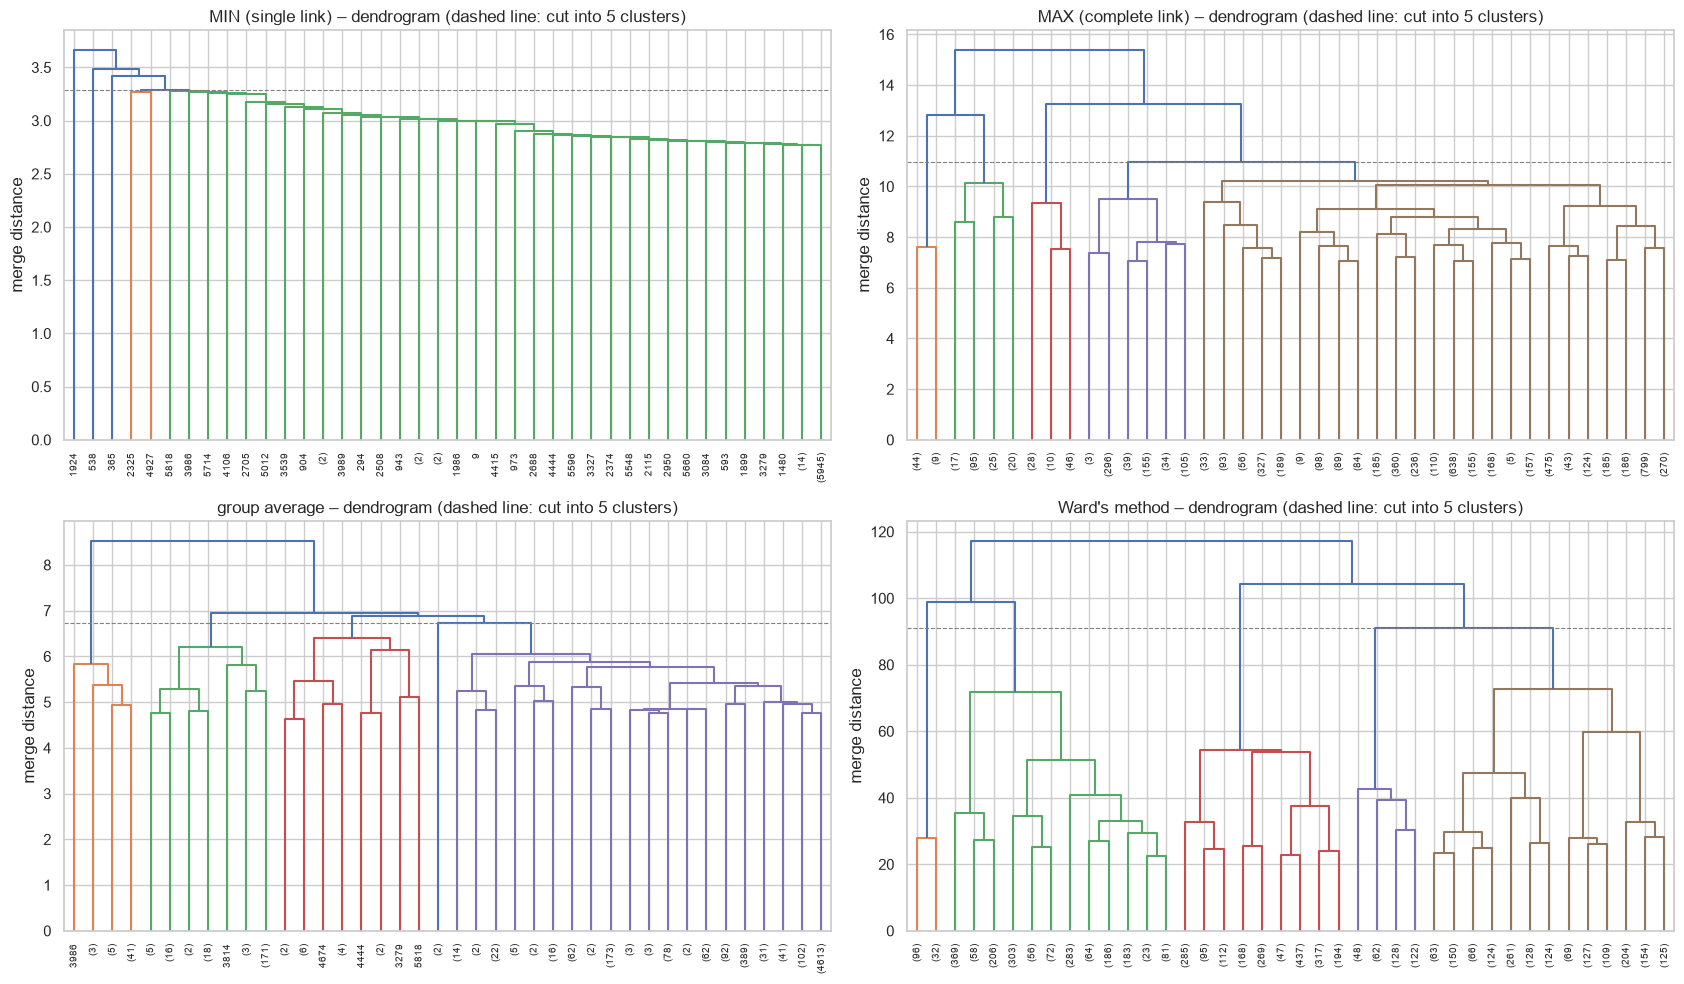

Ward's method – height gap of the merge that reduces k clusters to k-1 (a large gap suggests cutting at k):


,2,3,4,5,6,7,8,9,10
height gap,13.0300,5.3700,7.8700,18.2600,0.8800,11.9100,5.6200,0.6500,2.4100


In [43]:
# Dendrograms (truncated to the last 40 merges; numbers in brackets = accounts in a leaf). The MIN tree is very deep
# (chaining), hence the higher recursion limit.
import sys
sys.setrecursionlimit(max(sys.getrecursionlimit(), 20_000))
fig, axes = plt.subplots(2, 2, figsize=(17, 10))
for ax, method in zip(axes.ravel(), LINKAGES):
    cut = Z[method][-(5 - 1), 2] - 1e-9          # height that leaves 5 clusters
    dendrogram(Z[method], truncate_mode='lastp', p=40, ax=ax, show_contracted=False, color_threshold=cut,
               leaf_rotation=90, leaf_font_size=7)
    ax.axhline(cut, color='grey', ls='--', lw=0.8)
    ax.set_title(f'{LINKAGES[method]} – dendrogram (dashed line: cut into 5 clusters)')
    ax.set_ylabel('merge distance')
plt.tight_layout()
plt.show()
ward_h = Z['ward'][:, 2]
gaps = pd.Series({k: ward_h[-(k - 1)] - ward_h[-k] for k in range(2, 11)}, name='height gap')
print("Ward's method – height gap of the merge that reduces k clusters to k-1 (a large gap suggests cutting at k):")
display(gaps.to_frame().T.round(2))

**Comparison of the linkages** ([HIER] pp. 15–27).

* **MIN (single link)**: one cluster with > 99.8% of the accounts for every k – the *chaining* effect and the
  sensitivity to noise described in [HIER] p. 18.
* **Group average**: also one giant cluster (≥ 94%) plus a few small groups of outliers. Its silhouette and its
  proximity–incidence correlation (≈ −0.49) look good only because a few isolated outliers are very far from
  everything else; the partition is useless to describe profiles.
* **MAX (complete link)**: less extreme but unbalanced (85% of the accounts in one cluster for k = 5) and with the
  lowest silhouettes; it tends to break large clusters ([HIER] p. 22).
* **Ward's method** (the hierarchical analogue of K-means, [HIER] p. 26) gives balanced and interpretable clusters.
  Its dendrogram has the **largest height gap at k = 5** (the merge 5 → 4 clusters is the most expensive one), the
  silhouette is flat around 0.10 for every k and the proximity–incidence correlation is ≈ −0.31 at k = 5. We
  therefore cut the Ward dendrogram at **k = 5** (the same k as K-means, which also eases the comparison).

Cluster sizes (sorted) when every dendrogram is cut into k = 5 clusters:


,#1,#2,#3,#4,#5
MIN (single link),5995,2,1,1,1
MAX (complete link),5074,632,157,84,53
group average,5714,216,50,18,2
Ward's method,1924,1884,1704,360,128


Hierarchical, Ward's method (k=5): 5 clusters | total class entropy = 0.508 bits, purity = 0.862 (noise excluded)


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts,class entropy,class purity
C0,128,2.1330,65.6250,17.9690,2.3440,0.7810,77.3440,1.5620,9.6660,0.9280,0.6560
C1,1884,31.4000,22.7710,15.3400,4.1930,13.0040,47.2930,20.1700,49.3670,0.7740,0.7720
C2,1924,32.0670,3.8460,31.5490,10.0310,13.2020,28.2220,16.9960,8.5160,0.2350,0.9620
C3,360,6.0000,41.9440,41.6670,3.6110,3.3330,30.2780,21.1110,17.3760,0.9810,0.5810
C4,1704,28.4000,7.6880,20.8330,7.6880,10.9150,45.9510,14.6130,15.0750,0.3910,0.9230


Medians of the attributes in every cluster (original units):


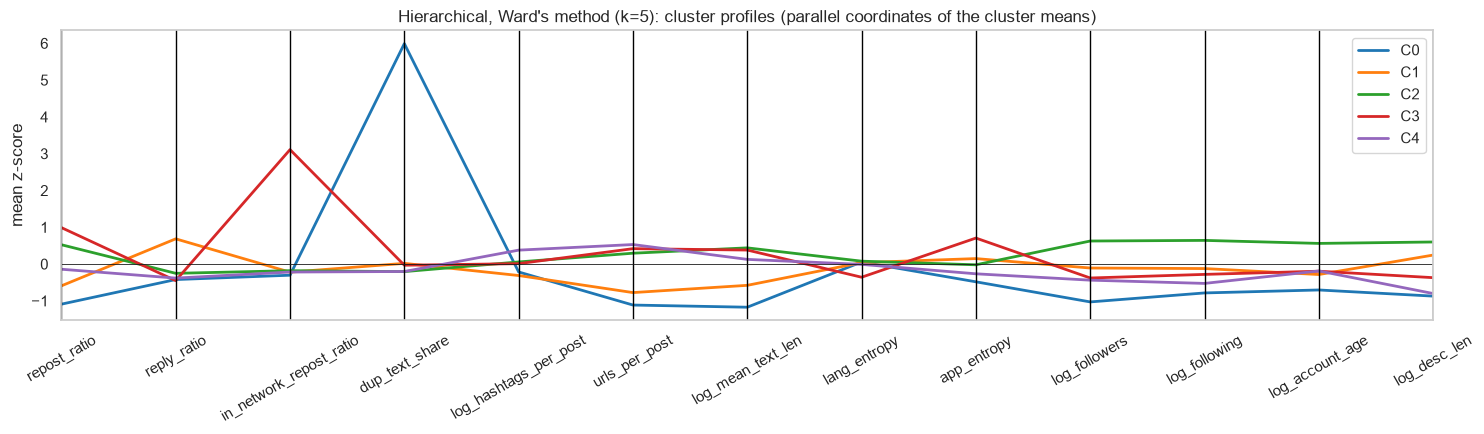

,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.0000,0.0000,0.0000,0.7120,0.6590,0.1110,75.2130,0.2470,0.0000,57.4980,115.4990,217.6120,0.0000
C1,0.1670,0.1880,0.0000,0.0000,0.5560,0.2000,102.6670,0.4210,0.1320,398.5000,367.0000,439.8380,56.0000
C2,0.7430,0.0130,0.0000,0.0000,0.8000,0.7230,149.3820,0.3900,0.0000,"1,456.0000","1,379.4990","1,300.8440",101.0000
C3,0.8880,0.0020,0.3600,0.0000,0.8610,0.7840,137.6080,0.2460,0.4540,175.4430,222.9440,392.4360,23.4950
C4,0.1670,0.0000,0.0000,0.0000,1.0000,0.9190,137.2250,0.3490,0.0000,214.0000,168.0000,513.4120,0.0000


Contingency table Ward clusters x K-means clusters (hierarchical sample):


K-means,C0,C1,C2,C3,C4
Ward,,,,,
C0,0,0,0,0,128
C1,9,122,424,1284,45
C2,5,1581,53,285,0
C3,257,72,20,10,1
C4,8,598,880,218,0


In [44]:
H_K = 5
labels_h = {m: fcluster(Z[m], t=H_K, criterion='maxclust') - 1 for m in LINKAGES}
sizes_tab = pd.DataFrame({LINKAGES[m]: pd.Series(np.sort(np.bincount(l))[::-1]) for m, l in labels_h.items()})
sizes_tab = sizes_tab.fillna(0).astype(int).set_axis([f'#{i + 1}' for i in range(len(sizes_tab))])
print(f'Cluster sizes (sorted) when every dendrogram is cut into k = {H_K} clusters:')
display(sizes_tab.T)
labels_ward = labels_h['ward']
ward_name = f"Hierarchical, Ward's method (k={H_K})"
display(cluster_summary(labels_ward, ward_name, idx=h_idx))
print('Medians of the attributes in every cluster (original units):')
display(cluster_profiles(labels_ward, ward_name, idx=h_idx))
print('Contingency table Ward clusters x K-means clusters (hierarchical sample):')
display(pd.crosstab(cluster_names(labels_ward).rename('Ward'), cluster_names(labels_km[h_idx]).rename('K-means')))

**Interpretation of the Ward clusters** (6,000-account sample):

| Cluster | Size | % IO | Profile | K-means counterpart |
|---|---|---|---|---|
| C2 | 32% | 4% | established users: ≈1.5k followers, ≈3.6 years old, long biographies, ≈74% reposts | C1 |
| C1 | 31% | 23% (**49% of all IO accounts**) | conversational / low-profile mix: ≈19% replies, ≈400 followers, ≈15 months old | C3 + C2 |
| C4 | 28% | 8% | link and hashtag sharers without biography (≈0.9 links and 1 hashtag per post) | C1 + C2 |
| C3 | 6% | 42% | **network amplifiers**: ≈89% reposts, ≈36% in-network, several clients | C0 |
| C0 | 2% | 66% (77% Russia) | **copy-paste broadcasters**: ≈71% duplicated texts, no reposts | C4 (all of them) |

Ward and K-means share the most information among the methods (2.5) and recover the same two IO-dominated groups
(amplifiers and copy-paste broadcasters), which makes them **robust findings**; they differ mainly in how they split
the large mass of ordinary accounts.

## 2.5 Comparison of the clustering solutions

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Aspects of cluster validation; internal, external and relative indices | [VAL] pp. 3–6 |
| Internal: SSE (cohesion), BSS (separation), silhouette | [VAL] pp. 14–19 |
| Correlation between proximity and ideal similarity (incidence) matrices | [VAL] pp. 7–8 |
| Similarity matrix ordered by cluster label (visual inspection) | [VAL] pp. 9–13 |
| External: entropy and purity | [VAL] p. 20 |
| Agreement between two clusterings: contingency table, mutual information (max = log2(min(nX, nY))) | [SIM] pp. 23–24 |
| Strengths and limitations of each algorithm | [KM] pp. 10–16; [DBSCAN] pp. 9–10; [HIER] pp. 17–31 |

All solutions are compared on the **same 6,000 accounts** of the hierarchical sample (K-means labels come from the
model trained on all accounts, DBSCAN labels from the model trained on the 20,000-account sample). External
measures use information that was **not** used for clustering: the class (IO / control) and the operation.

Reference: entropy of the class in the sample = 0.597 bits, purity of a single cluster = 0.855


,clusters,noise %,SSE,BSS,silhouette,"corr(proximity, incidence)",class entropy,class purity,operation entropy,operation purity,% IO in IO-majority clusters,max % IO of a cluster (>=1% size)
K-means (k=5),5.0000,0.0000,"51,260.1180","26,470.0220",0.1550,-0.4210,0.4910,0.8650,2.0150,0.4310,29.3440,62.0690
"DBSCAN (Eps=1.6, MinPts=50)",4.0000,35.1000,"32,398.6760","4,107.4250",0.3110,-0.4590,0.4320,0.9100,2.0650,0.3910,14.8450,98.5510
Ward (k=5),5.0000,0.0000,"56,417.3260","21,312.8140",0.0990,-0.3140,0.5080,0.8620,2.0290,0.4220,9.6660,65.6250
Group average (k=5),5.0000,0.0000,"68,825.8040","8,904.3360",0.2400,-0.4940,0.5690,0.8600,2.0650,0.4080,14.0390,56.4810
MAX / complete (k=5),5.0000,0.0000,"65,434.3650","12,295.7750",0.0430,-0.3390,0.5730,0.8590,2.0530,0.4120,10.2420,56.6880


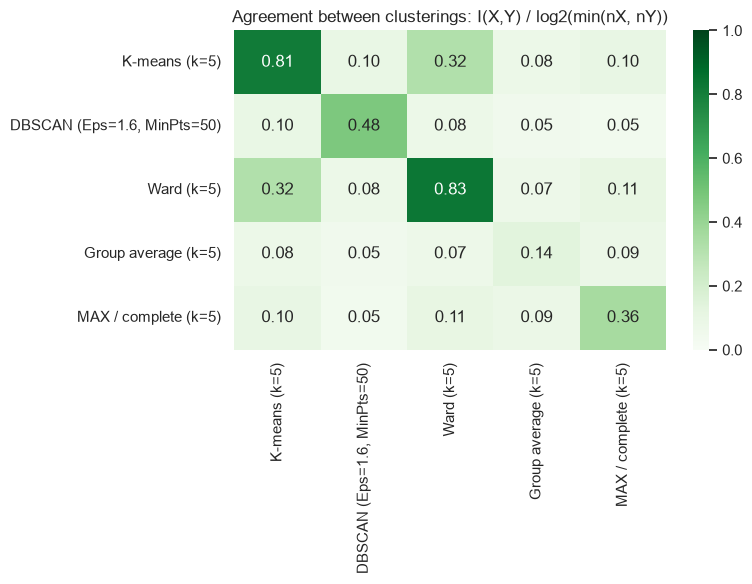

In [45]:
methods = {
    f'K-means (k={K_BEST})': labels_km[h_idx],
    f'DBSCAN (Eps={DB_EPS}, MinPts={DB_MIN_PTS})': labels_db[h_idx],
    f"Ward (k={H_K})": labels_ward,
    f'Group average (k={H_K})': labels_h['average'],
    f'MAX / complete (k={H_K})': labels_h['complete'],
}
y_class = data.iloc[h_idx]['class'].astype(str).to_numpy()
y_op = data.iloc[h_idx]['ioCountry'].astype(str).to_numpy()


def compare_row(lab):
    lab = np.asarray(lab)
    noise = -1 if (lab == -1).any() else None
    sc = internal_scores(Xh, lab)
    e_cls, p_cls = entropy_purity(lab, y_class)
    e_op, p_op = entropy_purity(lab, y_op)
    s = pd.DataFrame({'lab': lab, 'io': y_class == 'IO'})
    s_nn = s[s['lab'] != -1]
    io_share = s_nn.groupby('lab')['io'].mean()
    big = s_nn['lab'].value_counts()
    big = big[big >= 0.01 * len(s)].index
    return {'clusters': int(len(set(lab)) - (noise is not None)), 'noise %': 100 * (lab == -1).mean(), **sc,
            'corr(proximity, incidence)': incidence_correlation(lab, noise_label=noise),
            'class entropy': e_cls, 'class purity': p_cls, 'operation entropy': e_op, 'operation purity': p_op,
            '% IO in IO-majority clusters': 100 * s_nn['io'][s_nn['lab'].map(io_share) > 0.5].sum() / s['io'].sum(),
            'max % IO of a cluster (>=1% size)': 100 * io_share[big].max()}


comparison = pd.DataFrame({name: compare_row(lab) for name, lab in methods.items()}).T
print(f'Reference: entropy of the class in the sample = {entropy_bits(pd.Series(y_class).value_counts()):.3f} bits, '
      f'purity of a single cluster = {(y_class == "Control").mean():.3f}')
display(comparison.round(3))


def mi_matrix(meths):
    """Mutual information between every pair of clusterings, relative to its maximum log2(min(nX, nY))."""
    out = pd.DataFrame(index=meths, columns=meths, dtype=float)
    for a in meths:
        for b in meths:
            na_, nb_ = len(set(meths[a])), len(set(meths[b]))
            out.loc[a, b] = mutual_information_bits(meths[a], meths[b]) / np.log2(min(na_, nb_))
    return out


plt.figure(figsize=(8, 6))
sns.heatmap(mi_matrix(methods), annot=True, fmt='.2f', cmap='Greens', vmin=0, vmax=1)
plt.title('Agreement between clusterings: I(X,Y) / log2(min(nX, nY))')
plt.tight_layout()
plt.show()

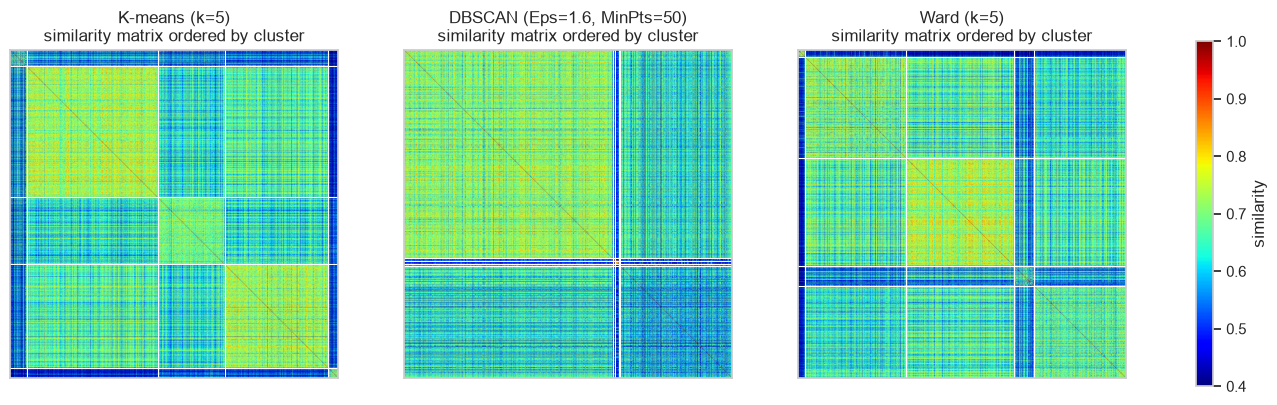

In [46]:
# Similarity matrices ordered by cluster label ([VAL] pp. 9-13), on 1,200 accounts of the common sample
sub = np.sort(np.random.default_rng(1).choice(len(h_idx), size=1200, replace=False))
D_sub = pdist(Xh[sub])
from scipy.spatial.distance import squareform
S_sub = 1 - squareform(D_sub) / D_sub.max()              # similarity in [0, 1]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
for ax, name in zip(axes, list(methods)[:3]):
    lab = np.asarray(methods[name])[sub]
    order = np.argsort(np.where(lab == -1, lab.max() + 1, lab), kind='stable')   # noise last
    im = ax.imshow(S_sub[np.ix_(order, order)], cmap='jet', vmin=0.4, vmax=1)
    bounds = np.cumsum(pd.Series(np.where(lab == -1, lab.max() + 1, lab)).value_counts().sort_index().to_numpy())
    for b in bounds[:-1]:
        ax.axhline(b, color='w', lw=0.8)
        ax.axvline(b, color='w', lw=0.8)
    ax.set_title(f'{name}\nsimilarity matrix ordered by cluster')
    ax.set_xticks([])
    ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label='similarity')
plt.show()

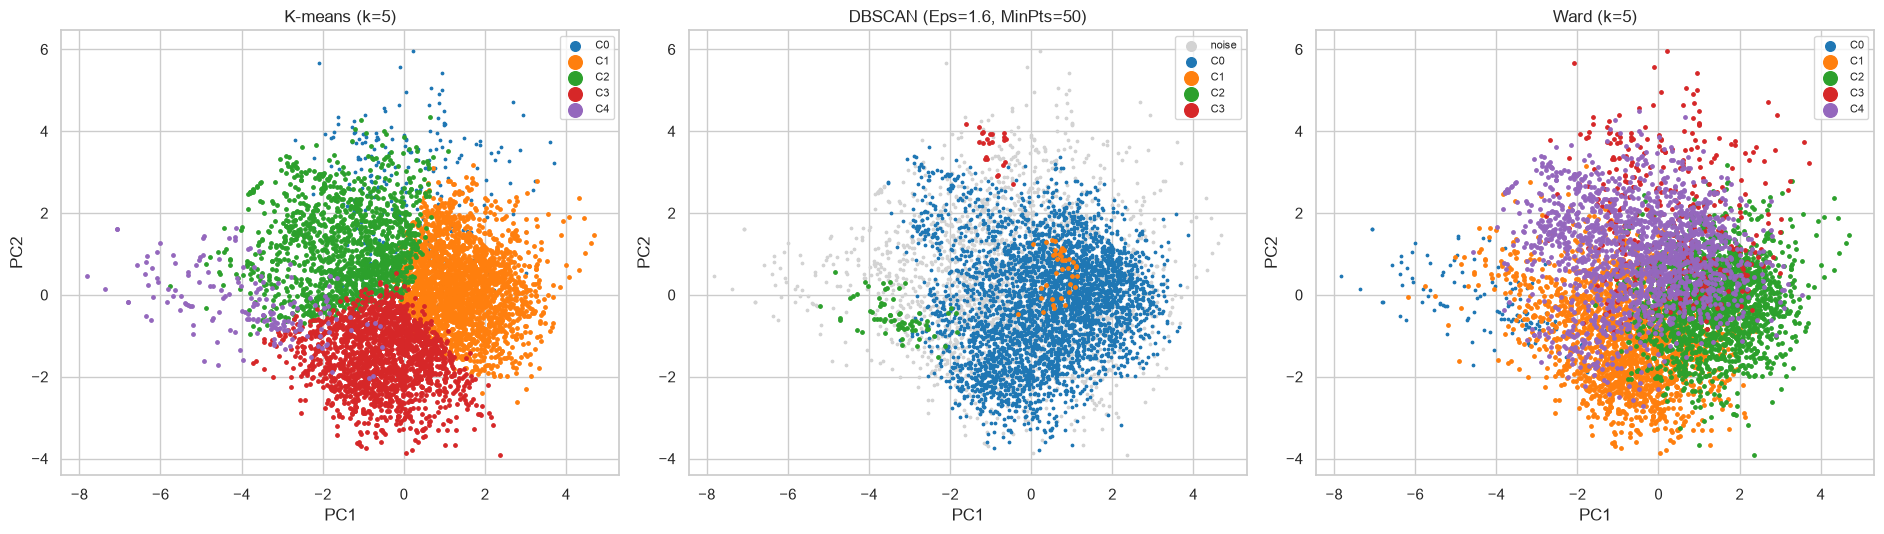

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
for ax, name in zip(axes, list(methods)[:3]):
    scatter_pca(methods[name], name, ax, idx=h_idx)
plt.tight_layout()
plt.show()

**Quantitative comparison.**

* *Internal measures.* DBSCAN has the best silhouette (≈ 0.31), but it is computed only on the ≈65% of accounts that
  are not noise and on a solution dominated by one big cluster. Group average looks good (silhouette ≈ 0.24, best
  proximity–incidence correlation ≈ −0.49) only because it isolates a few outliers. Among the methods producing
  balanced partitions, **K-means** has the lowest SSE, the highest BSS and the best silhouette and correlation – as
  expected, since it directly minimises the SSE – followed by Ward.
* *External measures.* With a single cluster the class entropy would be ≈ 0.60 bits and the purity 0.855. K-means
  (0.49 / 0.865), Ward (0.51 / 0.862) and the other linkages improve these values only slightly, DBSCAN a bit more
  on its clustered points (0.43 / 0.910). The operation is not reproduced either (operation entropy ≈ 2.0 bits of
  2.32). **No method recovers the IO/control label**: the clusters describe behavioural styles that cut across
  classes and operations.
* *Concentration of IO accounts.* DBSCAN finds the purest IO clusters (up to ≈99% IO) but they cover few IO accounts;
  K-means puts ≈29% of the IO accounts of the sample in IO-majority clusters (its amplifier cluster is at the 50%
  threshold), Ward ≈10%.
* *Agreement.* K-means and Ward share the most information (≈0.32 of the maximum mutual information); DBSCAN and the
  other linkages share very little with the rest, because their partitions are dominated by one giant cluster. The
  ordered similarity matrices ([VAL] pp. 9–13) show only weak blocks for K-means and Ward and one large block for
  DBSCAN, consistently with the low silhouettes.

**Strengths and limitations** (as observed on these data, cf. the limitations listed in the slides).

| Method | Strengths | Limitations |
|---|---|---|
| K-means | scales to all 69k accounts; centroids easy to interpret; lowest SSE | k must be chosen and the data have no clear k; assumes globular clusters of similar size; sensitive to outliers (mitigated by log + IQR capping); partitions a continuum ([KM] pp. 10–16) |
| DBSCAN | finds dense groups of any shape and an explicit noise class; isolates near-identical coordinated accounts | very sensitive to Eps / MinPts; one density threshold for regions of very different density; costly neighbourhood queries (sample); distances lose contrast in 13 dimensions ([DBSCAN] p. 10) |
| Hierarchical | no k needed in advance; the dendrogram shows the structure at several scales; Ward consistent with K-means | the linkage is decisive (MIN and group average degenerate into one cluster + outliers); O(N²) memory → 6k sample; merges cannot be undone ([HIER] pp. 30–31) |

**Robust findings across methods.** Two IO-dominated behaviours – **network amplifiers** (coordinated in-network
reposting, several clients) and **copy-paste broadcasters** (verbatim duplicated content, no reposts) – are found by
K-means, Ward and DBSCAN (DBSCAN in an even purer form, revealing also a UAE retweet farm). The remaining IO accounts
blend with control accounts, mostly in a group of **low-profile young accounts** (few followers, empty biographies),
where behaviour alone does not separate IO accounts from genuine newcomers.

## 2.6 Optional: Mixture models and the EM algorithm (Gaussian Mixture Model)

**Techniques and course slides used in this section**

| Technique | Slides |
|---|---|
| Model-based (probabilistic) clustering with a mixture of Gaussians | [KM-VAR] pp. 13–27 |
| EM algorithm (soft assignment in the E-step, parameter update in the M-step) | [KM-VAR] pp. 16, 28 |
| Advantages and disadvantages of EM | [KM-VAR] p. 29 |
| Bayesian Information Criterion to choose the number of clusters | [KM-VAR] pp. 7–9 |
| Fuzzy / probabilistic clusterings (membership weights summing to 1) | [CL-INTRO] p. 9 |
| Entropy, purity, mutual information | [VAL] p. 20; [SIM] pp. 23–24 |

The slides on K-means variants present three extensions of K-means (bisecting K-means, X-means and mixture models
fitted with EM). We use the **mixture of Gaussians fitted with EM**, because it is the variant that changes the most
with respect to the mandatory methods: every cluster is a multivariate Gaussian with its own mean and covariance
matrix (clusters of different sizes and shapes, [KM-VAR] p. 29), and every account receives a **probability** of
belonging to each cluster (soft assignment) instead of a hard label.

**Model selection with BIC.** BIC balances the fit (log-likelihood) and the number of parameters
([KM-VAR] pp. 7–8). scikit-learn reports $BIC = -2 \log L + p \log n$, i.e. the slide definition with the opposite
sign: here **lower is better**. Several attributes have many values exactly at 0 (no duplicated texts, no
in-network reposts), which makes some covariance matrices almost singular; a small value (`reg_covar = 1e-3`) is
added to their diagonal to keep the EM estimates stable.

covariance,diag,full,full: BIC decrease vs k-1
k,,,
2,"1,950,192.0000","1,913,058.0000",NaN
3,"1,749,350.0000","1,558,721.0000","354,337.0000"
4,"1,684,347.0000","1,522,872.0000","35,849.0000"
5,"1,573,960.0000","1,407,695.0000","115,177.0000"
6,"1,532,794.0000","1,344,690.0000","63,004.0000"
7,"1,494,611.0000","1,335,664.0000","9,026.0000"
8,"1,409,237.0000","1,311,886.0000","23,779.0000"
9,"1,379,632.0000","1,265,418.0000","46,467.0000"
10,"1,356,316.0000","1,213,808.0000","51,610.0000"


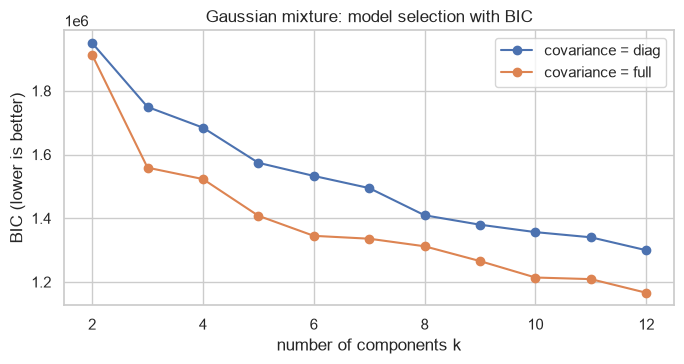

In [48]:
GMM_K = range(2, 13)
gmm_rows, gmm_models = [], {}
for cov in ['diag', 'full']:
    for k in GMM_K:
        gm = GaussianMixture(n_components=k, covariance_type=cov, reg_covar=1e-3, n_init=1,
                             random_state=RANDOM_STATE).fit(X)
        gmm_models[(cov, k)] = gm
        gmm_rows.append({'covariance': cov, 'k': k, 'BIC': gm.bic(X)})
gmm_bic = pd.DataFrame(gmm_rows).pivot(index='k', columns='covariance', values='BIC')
gmm_bic['full: BIC decrease vs k-1'] = -gmm_bic['full'].diff()
display(gmm_bic.round(0))
fig, ax = plt.subplots(figsize=(7, 3.8))
for cov in ['diag', 'full']:
    ax.plot(gmm_bic.index, gmm_bic[cov], marker='o', label=f'covariance = {cov}')
ax.set_xlabel('number of components k')
ax.set_ylabel('BIC (lower is better)')
ax.set_title('Gaussian mixture: model selection with BIC')
ax.legend()
plt.tight_layout()
plt.show()

**Choice of the model.** Full covariance matrices always give a much lower BIC than diagonal ones (the attributes
are correlated, so elliptical clusters with free orientation fit better). BIC keeps decreasing up to 12 components:
with ≈69k accounts the penalty for extra parameters is small compared with the likelihood gain, so BIC has no
minimum in the range. We therefore use the "elbow" of the curve: the first improvement (2 → 3 components) is
≈354k, and **after k = 5 every additional component improves BIC by less than 20% of that first gain**. We select
the full-covariance model with **k = 5**, which also has the same number of clusters as K-means and Ward.

GMM / EM (full covariance, k=5): 5 clusters | total class entropy = 0.422 bits, purity = 0.863 (noise excluded)


,size,size %,% IO,% ecuador,% iran_1,% iran_4,% russia_1,% uae,% of all IO accounts,class entropy,class purity
C0,8391,12.1410,46.3830,26.9460,5.6730,9.2000,29.8530,28.3280,38.9040,0.9960,0.5360
C1,18654,26.9910,5.3230,19.1380,9.1670,9.4240,50.3590,11.9120,9.9260,0.3000,0.9470
C2,20882,30.2150,5.3630,21.5980,7.5470,11.2390,48.1080,11.5080,11.1960,0.3020,0.9460
C3,14295,20.6840,2.0080,38.5800,5.3100,16.1530,17.3420,22.6160,2.8690,0.1420,0.9800
C4,6889,9.9680,53.8830,11.2790,1.1610,15.3580,53.3600,18.8420,37.1050,0.9960,0.5390


Medians of the attributes in every cluster (original units):


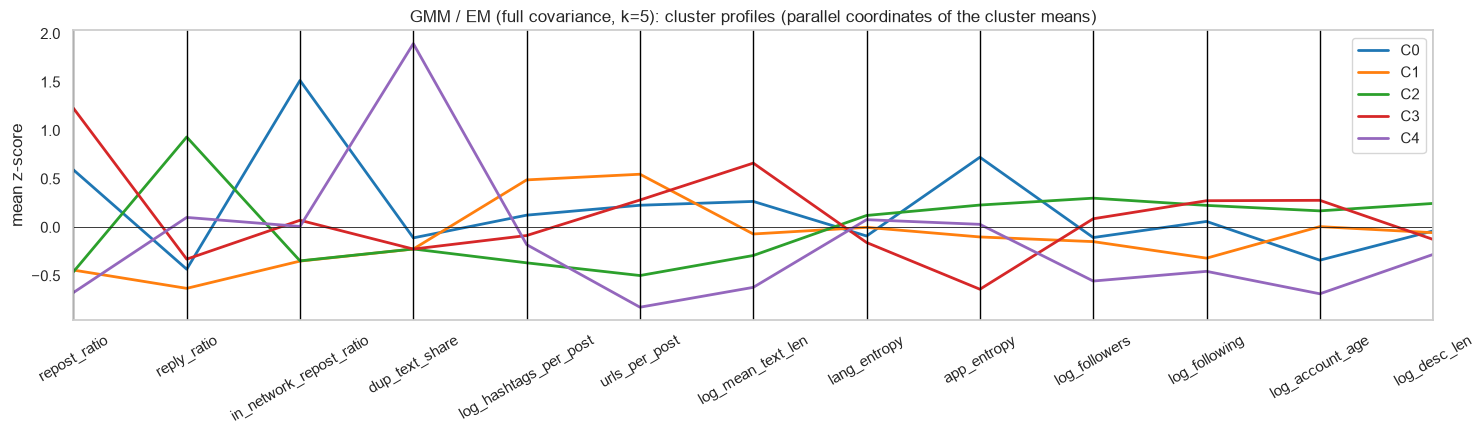

,repost_ratio,reply_ratio,in_network_repost_ratio,dup_text_share,hashtags_per_post,urls_per_post,mean_text_len,lang_entropy,app_entropy,follower_count,following_count,account_age_days,desc_len
C0,0.7300,0.0100,0.1110,0.0000,0.9440,0.7040,136.2250,0.3440,0.5950,303.0000,399.0000,344.9760,48.0000
C1,0.0000,0.0000,0.0000,0.0000,1.1510,1.0000,129.4130,0.3250,0.0000,388.0000,283.0000,681.2620,52.0000
C2,0.2000,0.2420,0.0000,0.0000,0.4920,0.2960,115.5880,0.4690,0.2300,803.0000,624.0000,802.9100,70.0000
C3,0.9700,0.0000,0.0000,0.0000,0.7620,0.7140,161.5560,0.2760,0.0000,519.0000,679.0000,"1,066.6280",45.0000
C4,0.1230,0.0400,0.0100,0.1260,0.6900,0.2000,98.3080,0.3690,0.0810,107.0000,182.0000,179.0520,32.0000


,max posterior,uncertain (p < 0.8)
class,,
IO,0.9520,0.0970
Control,0.9570,0.0810


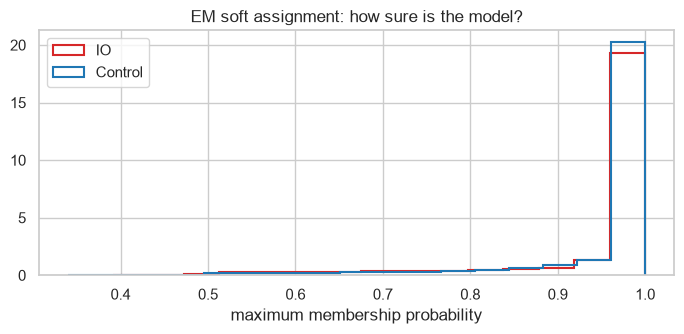

In [49]:
GMM_COV, GMM_K_BEST = 'full', 5
gmm = gmm_models[(GMM_COV, GMM_K_BEST)]
labels_gmm = gmm.predict(X)
proba = gmm.predict_proba(X)
gmm_name = f'GMM / EM ({GMM_COV} covariance, k={GMM_K_BEST})'
display(cluster_summary(labels_gmm, gmm_name))
print('Medians of the attributes in every cluster (original units):')
display(cluster_profiles(labels_gmm, gmm_name))

# Soft assignment: maximum membership probability of every account
conf = pd.DataFrame({'max posterior': proba.max(axis=1), 'class': data['class']})
conf['uncertain (p < 0.8)'] = conf['max posterior'] < 0.8
display(conf.groupby('class', observed=True)[['max posterior', 'uncertain (p < 0.8)']].mean().round(3))
fig, ax = plt.subplots(figsize=(7, 3.5))
for cls in CLASS_ORDER:
    v = conf.loc[conf['class'] == cls, 'max posterior']
    ax.hist(v, bins=sturges_bins(len(v)), density=True, histtype='step', lw=1.5, color=CLASS_PALETTE[cls], label=cls)
ax.set_xlabel('maximum membership probability')
ax.set_title('EM soft assignment: how sure is the model?')
ax.legend()
plt.tight_layout()
plt.show()

In [50]:
# Comparison with the mandatory methods on the common sample of 6,000 accounts
methods_ext = dict(methods)
methods_ext[gmm_name] = labels_gmm[h_idx]
comparison_ext = pd.DataFrame({name: compare_row(lab) for name, lab in methods_ext.items()}).T
display(comparison_ext.round(3))
print('Agreement with K-means on all accounts, I / log2(min(nX, nY)):',
      round(mutual_information_bits(labels_km, labels_gmm) / np.log2(min(K_BEST, GMM_K_BEST)), 3))
print('Contingency table GMM components x K-means clusters (all accounts):')
display(pd.crosstab(cluster_names(labels_gmm).rename('GMM'), cluster_names(labels_km).rename('K-means')))

,clusters,noise %,SSE,BSS,silhouette,"corr(proximity, incidence)",class entropy,class purity,operation entropy,operation purity,% IO in IO-majority clusters,max % IO of a cluster (>=1% size)
K-means (k=5),5.0000,0.0000,"51,260.1180","26,470.0220",0.1550,-0.4210,0.4910,0.8650,2.0150,0.4310,29.3440,62.0690
"DBSCAN (Eps=1.6, MinPts=50)",4.0000,35.1000,"32,398.6760","4,107.4250",0.3110,-0.4590,0.4320,0.9100,2.0650,0.3910,14.8450,98.5510
Ward (k=5),5.0000,0.0000,"56,417.3260","21,312.8140",0.0990,-0.3140,0.5080,0.8620,2.0290,0.4220,9.6660,65.6250
Group average (k=5),5.0000,0.0000,"68,825.8040","8,904.3360",0.2400,-0.4940,0.5690,0.8600,2.0650,0.4080,14.0390,56.4810
MAX / complete (k=5),5.0000,0.0000,"65,434.3650","12,295.7750",0.0430,-0.3390,0.5730,0.8590,2.0530,0.4120,10.2420,56.6880
"GMM / EM (full covariance, k=5)",5.0000,0.0000,"62,319.8100","15,410.3300",0.0530,-0.2120,0.4260,0.8610,1.9970,0.4470,38.3200,52.9410


Agreement with K-means on all accounts, I / log2(min(nX, nY)): 0.219
Contingency table GMM components x K-means clusters (all accounts):


K-means,C0,C1,C2,C3,C4
GMM,,,,,
C0,2750,2939,1764,938,0
C1,0,8040,8058,2556,0
C2,0,5082,1542,14258,0
C3,568,10794,2292,641,0
C4,161,465,1934,2390,1939


**Does the mixture model add new insights?**

| Component | Size | % IO | Profile |
|---|---|---|---|
| C0 | 12% | 46% (**39% of all IO accounts**) | repost-based amplifiers: ≈73% reposts, in-network reposts, the **only component using several clients** (app entropy ≈ 0.6 bits), ≈1 year old, ≈300 followers |
| C4 | 10% | 54% (**37% of all IO accounts**) | young accounts (≈6 months) with few followers, mostly original posts, and the **only component whose typical account has duplicated texts** |
| C1 | 27% | 5% | link and hashtag sharers that never repost |
| C2 | 30% | 5% | conversational, multilingual users (≈24% replies) |
| C3 | 21% | 2% | established pure reposters (≈97% reposts, ≈3 years old) |

* **Two components gather ≈76% of all IO accounts**, each about half IO, against ≈30% for the two IO-dominated
  K-means clusters. The GMM partition is the one that best concentrates the IO accounts in IO-majority groups (see the
  comparison table) and has the lowest class entropy among the methods that assign every account.
* The reason is the probabilistic model: each component has its own covariance matrix, so the EM algorithm can model
  the many exact zeros of the coordination attributes (components with almost no variance on duplicated texts,
  in-network reposts or client diversity) and separate accounts showing **small but present coordination signals**
  from accounts showing none. For K-means and Ward a small share of copied posts is only a small Euclidean distance,
  so those accounts are absorbed by the large "ordinary" clusters.
* Internal indices are poor (low silhouette, weak proximity–incidence correlation): overlapping elliptical
  components are not what these distance-based indices reward – a reminder that quantitative indices must not be the
  only basis of the comparison. Its agreement with K-means is low (≈0.2 of the maximum mutual information): it is a
  genuinely different view of the data.
* The soft assignment is confident for both classes (mean maximum membership probability ≈ 0.95; ≈8–10% of the
  accounts below 0.8), so IO accounts are not more often "between" clusters than control accounts.

---
## Conclusions

1. **Data quality.** The data contained syntactic errors (invalid labels, text and negative values in numerical
   attributes), duplicates and partially missing reply identifiers. All were repaired with explicit rules keyed by the
   composite identifiers (ioCountry, id), exploiting the fact that account attributes are repeated on every post.
2. **Timestamps.** `post_time` is the real publication time (reposts and replies never precede the original post),
   but control accounts are observed in a **day-bounded window of at most ≈100 posts ending at 23:59 UTC**, whereas IO
   accounts are observed over their whole history. Volume and time features are therefore not comparable between the
   classes and were excluded from clustering.
3. **Profiles.** IO accounts are younger, less followed, copy-paste content, amplify their own operation and use
   fewer applications overall but more clients per account; other habits (post type, language) depend strongly on
   the operation.
4. **Clustering.** Behavioural profiles form a continuum (low silhouettes, no natural k) and no method reproduces
   the IO/control label. All methods agree on two IO-dominated behaviours – **network amplifiers** and
   **copy-paste broadcasters** – which DBSCAN isolates as almost pure IO groups, while the Gaussian mixture fitted
   with EM gathers three quarters of the IO accounts in the two components of accounts with coordination signals.